# Swahili Text Classification — Complete Coursework
**BAGANJA EMMANUEL **  
**NSIMBI NOEL **  
**KAKUMBA JEREMIAH **

CSC 63106: Artificial Intelligence · Group 1: Text Classification

## How to use

1. Open this notebook in **Google Colab**.
2. Read the next cell and choose a `MODE`:
   - `"view"` — needs the embedded results data, which this copy leaves out; the saved results are already shown as outputs.
   - `"quick"` — download data and train a quick BiLSTM baseline.
   - `"full"` — train everything: BiLSTM, GRU, Word2Vec/FastText, mBERT, AfriBERTa.
3. `Runtime → Run all`.

For `"full"`, enable a GPU:
`Runtime → Change runtime type → T4 GPU`.

The results are already saved in this notebook's outputs, so the figures and tables can be read
without running anything.

After a run, the last section writes a `results_export/` folder (all the figures)
and a `results_export.zip`.
The random seed is set in the first code cell (`SEED = 42`).


## 1. Choose the mode

In [1]:
MODE = "view"          # "view", "quick", "full"
DATASET = "swahili_news"

EPOCHS_RNN = 8
EPOCHS_HF = 5
BATCH_HF = 16
MAX_LEN = 128

# ---- Reproducibility -----------------------------------------------------
SEED = 42              # change this one number to re-run with another seed
DETERMINISTIC = True   # a little slower, but repeat runs give the same numbers

import os, random
import numpy as np
os.environ["SEED"] = str(SEED)                       # read by src/config.py
os.environ["DETERMINISTIC"] = "1" if DETERMINISTIC else "0"
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"    # needed for deterministic GPU maths
random.seed(SEED)
np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    if DETERMINISTIC:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        torch.use_deterministic_algorithms(True, warn_only=True)
except ImportError:
    pass
print(f"seed = {SEED}, deterministic = {DETERMINISTIC}")


seed = 42, deterministic = True


## 2. Install dependencies


In [2]:
if MODE != "view":
    !pip install -q numpy pandas scikit-learn matplotlib seaborn datasets gensim wordcloud tqdm torch transformers accelerate sentencepiece sacremoses protobuf
print("dependencies ready")

dependencies ready


## 3. Recreate the project source code

These cells write the `src/` files from inside the notebook, so there is nothing
to upload manually.

In [3]:
import os
os.makedirs("src", exist_ok=True)
os.makedirs("report", exist_ok=True)
print("directories ready")

directories ready


In [4]:
%%writefile src/config.py
"""Central configuration for the Swahili text-classification project.

Every script imports paths, dataset metadata, stopwords and the random seed
from here so that the project stays reproducible and easy to move between a
laptop (CPU) and Google Colab (GPU).
"""
from __future__ import annotations

import os
from pathlib import Path

# --------------------------------------------------------------------------- #
# Paths
# --------------------------------------------------------------------------- #
ROOT = Path(__file__).resolve().parents[1]
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
OUTPUT_DIR = ROOT / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
METRIC_DIR = OUTPUT_DIR / "metrics"
MODEL_DIR = OUTPUT_DIR / "models"

for _p in (RAW_DIR, PROCESSED_DIR, FIG_DIR, METRIC_DIR, MODEL_DIR):
    _p.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------------------------------- #
# Reproducibility
# --------------------------------------------------------------------------- #
# The notebook sets SEED in its first cell and passes it on through the environment.
SEED = int(os.environ.get("SEED", "42"))

# --------------------------------------------------------------------------- #
# Datasets
# --------------------------------------------------------------------------- #
# `label_names` is ordered by integer label id, exactly as stored in the
# Hugging Face ClassLabel / CSV.
DATASETS: dict[str, dict] = {
    "swahili_news": {
        "hf_id": "community-datasets/swahili_news",
        "hf_config": "swahili_news",
        "text_col": "text",
        "label_col": "label",
        "label_names": [
            "uchumi",      # 0 economy / business
            "kitaifa",     # 1 national
            "michezo",     # 2 sports
            "kimataifa",   # 3 international
            "burudani",    # 4 entertainment
            "afya",        # 5 health
        ],
        "local_csv": None,
        "task": "Swahili news topic classification (6 classes)",
        "splits": {"train": "train", "test": "test"},
    },
    "swahili_twitter": {
        "hf_id": "Davis/Swahili-tweet-sentiment",
        "hf_config": "default",
        "text_col": "Tweets",
        "label_col": "Labels",
        # -1 = negative, 0 = neutral, 1 = positive (documented convention for
        # this community CSV; verified against the raw value distribution).
        "label_map": {-1: 0, 0: 1, 1: 2},
        "label_names": ["negative", "neutral", "positive"],
        "local_csv": RAW_DIR / "swahili_twitter.csv",
        "task": "Swahili Twitter sentiment classification (3 classes)",
        "splits": {"train": "train"},
    },
}

DEFAULT_DATASET = "swahili_news"

# --------------------------------------------------------------------------- #
# Preprocessing defaults
# --------------------------------------------------------------------------- #
MAX_WORDS = 30_000     # vocabulary size for the RNN models
MAX_LEN = 128          # tokens per document after padding / truncation
EMBED_DIM = 200        # Word2Vec / FastText vector size
MIN_FREQ = 2           # minimum token frequency kept in the vocabulary

# --------------------------------------------------------------------------- #
# Swahili stopwords
# --------------------------------------------------------------------------- #
# Curated list of high-frequency function words. Removing them helps bag-of-
# words models but can hurt sequence models because Swahili packs grammatical
# information (tense, subject, negation) into prefixes. The pipeline therefore
# makes stopword removal optional (`--keep-stopwords`).
SWAHILI_STOPWORDS: set[str] = {
    "na", "ya", "wa", "kwa", "ni", "za", "la", "katika", "hii", "hiyo",
    "hilo", "huyo", "hawa", "wale", "hilo", "yake", "yao", "yetu", "yangu",
    "zetu", "zako", "zao", "kama", "au", "lakini", "ila", "bali", "kuwa",
    "sana", "pia", "hata", "zaidi", "baada", "kabla", "wakati", "sasa",
    "hapa", "pale", "huko", "hivyo", "ndiyo", "hapana", "yeye", "wao",
    "sisi", "mimi", "wewe", "ninyi", "wenyewe", "vyake", "chake", "chetu",
    "wake", "kwake", "kwetu", "kwenu", "kwao", "hapa", "humo", "huko",
    "juu", "chini", "ndani", "nje", "mbele", "nyuma", "karibu", "mbali",
    "kila", "wote", "wote", "vyote", "zote", "yote", "mwingine", "nyingine",
    "wingine", "kingine", "kitu", "mtu", "watu", "jambo", "mambo", "hali",
    "aina", "namna", "jinsi", "vile", "hivyo", "hiyo", "hilo", "huo",
    "hiyo", "huyu", "hawa", "hicho", "hivyo", "halafu", "kisha", "tena",
    "pamoja", "bila", "isipokuwa", "mpaka", "hadi", "tangu", "toka",
    "kutoka", "kwenye", "kwenye", "juu", "kuhusu", "kuhusiana", "kwa",
    "ajili", "sababu", "sababisha", "sasa", "hivi", "sasa", "leo", "jana",
    "kesho", "juzi", "mtondo", "asubuhi", "mchana", "jioni", "usiku",
    "mwezi", "wiki", "mwaka", "siku", "saa", "dakika", "mara", "mara",
    "kidogo", "sana", "sana", "tu", "tu", "bado", "tayari", "halisi",
    "kweli", "pengine", "labda", "huenda", "yawezekana", "kama", "kana",
    "kwa", "hata", "ingawa", "ijapokuwa", "lakini", "kwani", "kwa sababu",
    "hivyo", "basi", "ndipo", "ndio", "sasa", "halafu", "tena", "pia",
    "mbali", "karibu", "mara", "nyingi", "nyingine", "wengine", "wapya",
    "kubwa", "ndogo", "zuri", "mbaya", "rahisi", "ngumu", "mpya", "kuu",
    "kila", "chache", "nyingi", "mara", "mno", "sana", "hata", "vivyo",
}

# --------------------------------------------------------------------------- #
# Swahili affixes for the light rule-based stemmer
# --------------------------------------------------------------------------- #
# Swahili is agglutinative: a word can carry subject prefix + tense marker +
# object marker + root + suffix. A full morphological analyser is out of scope,
# so we use a conservative prefix/suffix stripper. It only strips an affix when
# the remaining stem is at least 4 characters long.
# We intentionally exclude single-letter subject markers ("a", "u", "n") and
# negative markers ("ha-", "si-") because they over-strip common words and
# destroy negation. The stemmer is conservative by design.
VERB_PREFIXES = [
    "ku", "kuto", "ni", "tu", "wa", "m", "na", "li", "ta", "me", "ka",
    "hu", "nge", "ngali",
]
NOUN_PREFIXES = [
    "wa", "ki", "vi", "ma", "mi", "ji", "u", "pa", "mu", "ku", "nya",
]
SUFFIXES = ["eni", "ini"]

# Words that should never be stemmed even if they start with an affix.
STEM_EXCEPTIONS = {
    "kila", "kama", "kwa", "kuwa", "lakini", "kwani", "kisha",
    "habari", "asubuhi", "maarufu", "wasiwasi", "burudani", "kuhusu",
}


Writing src/config.py


In [5]:
%%writefile src/utils.py
"""Small shared helpers: seeding, JSON I/O, plotting utilities."""
from __future__ import annotations

import json
import os
import random
import time
from pathlib import Path
from typing import Any

import numpy as np

from . import config


def set_seed(seed: int = config.SEED) -> None:
    """Make Python / NumPy / PyTorch runs as reproducible as possible."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch

        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        if os.environ.get("DETERMINISTIC", "1") == "1":
            os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
            torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:  # torch is optional for pure-EDA runs
        pass


def save_json(obj: Any, path: str | Path) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as fh:
        json.dump(obj, fh, indent=2, ensure_ascii=False)


def load_json(path: str | Path) -> Any:
    with Path(path).open(encoding="utf-8") as fh:
        return json.load(fh)


class Timer:
    """Context manager that reports wall-clock time."""

    def __init__(self, label: str = "run"):
        self.label = label

    def __enter__(self):
        self.t0 = time.time()
        return self

    def __exit__(self, *exc):
        self.elapsed = time.time() - self.t0
        print(f"[timer] {self.label}: {self.elapsed:.1f}s")


def slugify_model_name(name: str) -> str:
    """Turn a HF model id into a filesystem-friendly name."""
    return name.replace("/", "__").replace(" ", "_")


Writing src/utils.py


In [6]:
%%writefile src/data.py
"""Dataset loading, normalisation and reproducible train/validation/test splits.

Both supported datasets are small enough to live comfortably in pandas
DataFrames, which keeps the rest of the pipeline simple and fast.

Usage
-----
    python -m src.data --dataset swahili_news
    python -m src.data --dataset swahili_twitter
"""
from __future__ import annotations

import argparse
import json
import time
import urllib.parse
import urllib.request
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split

from . import config
from .utils import save_json

ROWS_API = "https://datasets-server.huggingface.co/rows"


# --------------------------------------------------------------------------- #
# Low-level loaders
# --------------------------------------------------------------------------- #
def _load_huggingface(name: str) -> pd.DataFrame:
    """Load the single/train split of a Hugging Face dataset as a DataFrame."""
    from datasets import load_dataset

    meta = config.DATASETS[name]
    ds = load_dataset(meta["hf_id"], meta["hf_config"])
    split_names = list(ds.keys())
    # Prefer the declared train split, else the first available split.
    split = meta["splits"].get("train", split_names[0])
    if split not in ds:
        split = split_names[0]
    return ds[split].to_pandas()


def _load_local_csv(path: Path) -> pd.DataFrame:
    return pd.read_csv(path)


def _rows_api_split(name: str, hf_split: str, max_retries: int = 4) -> pd.DataFrame:
    """Dependency-free fallback using the Hugging Face datasets-server API.

    This is used when ``datasets``/``pyarrow`` are unavailable (for example on a
    constrained laptop).  The API returns at most 100 rows per request, so we
    page through the split and cache the result as a CSV.  It is slower than
    ``datasets`` but needs only the standard library and pandas.
    """
    meta = config.DATASETS[name]
    cache_path = config.RAW_DIR / f"{name}_{hf_split}_rowsapi.csv"
    if cache_path.exists():
        print(f"[data] using cached {cache_path.name}")
        return pd.read_csv(cache_path)

    rows: list[dict] = []
    offset = 0
    while True:
        query = urllib.parse.urlencode(
            {
                "dataset": meta["hf_id"],
                "config": meta["hf_config"],
                "split": hf_split,
                "offset": offset,
                "length": 100,
            }
        )
        url = f"{ROWS_API}?{query}"
        payload = None
        for attempt in range(1, max_retries + 1):
            try:
                with urllib.request.urlopen(url, timeout=60) as response:
                    payload = json.loads(response.read().decode("utf-8"))
                break
            except Exception as exc:
                print(f"[data] rows API retry {attempt}/{max_retries}: {exc}")
                time.sleep(2 * attempt)
        if payload is None:
            raise RuntimeError(f"could not download {name}:{hf_split} via {ROWS_API}")
        if "rows" not in payload:
            raise RuntimeError(f"rows API error for {name}:{hf_split}: {payload.get('error')}")

        batch = [item["row"] for item in payload["rows"]]
        rows.extend(batch)
        offset += len(batch)
        print(f"[data] {name}:{hf_split} {offset} rows", end="\r")
        if len(batch) < 100:
            break

    print()
    frame = pd.DataFrame(rows)
    frame.to_csv(cache_path, index=False)
    print(f"[data] cached {len(frame)} rows -> {cache_path}")
    return frame


def _load_split(name: str, split_key: str) -> pd.DataFrame:
    """Load one declared split, preferring ``datasets`` and falling back to API."""
    meta = config.DATASETS[name]
    hf_split = meta["splits"].get(split_key, split_key)

    # The Twitter CSV is tiny and already cached in the repository.
    local = meta.get("local_csv")
    if split_key == "train" and local and Path(local).exists():
        return _load_local_csv(Path(local))

    try:
        from datasets import load_dataset

        ds = load_dataset(meta["hf_id"], meta["hf_config"])
        if hf_split in ds:
            return ds[hf_split].to_pandas()
    except Exception as exc:
        print(f"[data] datasets loader unavailable ({exc}); using rows API")

    return _rows_api_split(name, hf_split)


def _normalise(df: pd.DataFrame, name: str) -> pd.DataFrame:
    """Rename columns, map labels to 0..K-1 and attach human-readable names."""
    meta = config.DATASETS[name]
    text_col = meta["text_col"]
    label_col = meta["label_col"]
    missing = [c for c in (text_col, label_col) if c not in df.columns]
    if missing:
        raise ValueError(f"{name}: expected columns {missing}, got {list(df.columns)}")

    out = pd.DataFrame(
        {
            "text": df[text_col].fillna("").astype(str),
            "label": pd.to_numeric(df[label_col], errors="coerce"),
        }
    )
    out = out.dropna(subset=["label"]).copy()
    out["label"] = out["label"].astype(int)

    label_map = meta.get("label_map")
    if label_map:
        out["label"] = out["label"].map(label_map)
        if out["label"].isna().any():
            bad = sorted(set(df[label_col].unique()) - set(label_map))
            raise ValueError(f"{name}: unexpected labels {bad}")

    names = meta["label_names"]
    out["label_name"] = out["label"].map(lambda i: names[i])
    out = out[out["text"].str.strip().str.len() > 0].reset_index(drop=True)
    return out


def load_raw(name: str = config.DEFAULT_DATASET) -> pd.DataFrame:
    """Return the raw train split (all rows) for a dataset."""
    return _normalise(_load_split(name, "train"), name)


# --------------------------------------------------------------------------- #
# Public API
# --------------------------------------------------------------------------- #
def load_splits(
    name: str = config.DEFAULT_DATASET,
    val_size: float = 0.10,
    test_size: float | None = None,
    seed: int = config.SEED,
    cache: bool = True,
) -> dict[str, pd.DataFrame]:
    """Return train/validation/test DataFrames with columns text,label,label_name.

    * If the dataset provides a separate test split (Swahili News) it is used
      as-is and a stratified validation split is carved out of train.
    * If it only provides a train split (Swahili Twitter) we make a stratified
      90/10 split, or use ``test_size`` when explicitly requested.
    """
    meta = config.DATASETS[name]
    cache_dir = config.PROCESSED_DIR / name

    if cache and (cache_dir / "train.csv").exists():
        splits = {
            split: pd.read_csv(cache_dir / f"{split}.csv")
            for split in ("train", "val", "test")
            if (cache_dir / f"{split}.csv").exists()
        }
        if {"train", "val", "test"} <= splits.keys():
            return splits

    df = load_raw(name)
    sizes = {"raw_rows": int(len(df)), "num_labels": int(df["label"].nunique())}

    # Does the dataset have a real held-out test split?
    has_test = False
    if meta["splits"].get("test"):
        try:
            test_df = _normalise(_load_split(name, "test"), name)
            has_test = True
        except Exception as exc:
            print(f"[data] could not load official test split ({exc})")
            has_test = False
    if test_size is not None:
        has_test = False

    if has_test:
        train_df = df
        test_df = test_df
        train_df, val_df = train_test_split(
            train_df,
            test_size=val_size,
            stratify=train_df["label"],
            random_state=seed,
        )
    else:
        # Single-split dataset: carve out test (if requested) and validation.
        holdout = test_size if test_size is not None else 0.0
        if holdout > 0:
            train_val, test_df = train_test_split(
                df,
                test_size=holdout,
                stratify=df["label"],
                random_state=seed,
            )
        else:
            train_val, test_df = train_test_split(
                df,
                test_size=0.10,
                stratify=df["label"],
                random_state=seed,
            )
        train_df, val_df = train_test_split(
            train_val,
            test_size=val_size,
            stratify=train_val["label"],
            random_state=seed,
        )

    splits = {
        "train": train_df.reset_index(drop=True),
        "val": val_df.reset_index(drop=True),
        "test": test_df.reset_index(drop=True),
    }

    if cache:
        cache_dir.mkdir(parents=True, exist_ok=True)
        for split, frame in splits.items():
            frame.to_csv(cache_dir / f"{split}.csv", index=False)
        save_json(
            {
                "dataset": name,
                "task": meta["task"],
                "hf_id": meta["hf_id"],
                "raw_rows": sizes["raw_rows"],
                "num_labels": sizes["num_labels"],
                "label_names": meta["label_names"],
                "split_sizes": {k: int(len(v)) for k, v in splits.items()},
                "split_label_counts": {
                    k: v["label"].value_counts().sort_index().to_dict()
                    for k, v in splits.items()
                },
            },
            cache_dir / "split_summary.json",
        )
        print(f"[data] cached splits under {cache_dir}")
    return splits


def main() -> None:
    parser = argparse.ArgumentParser(description="Download and split a Swahili dataset")
    parser.add_argument("--dataset", default=config.DEFAULT_DATASET, choices=config.DATASETS)
    parser.add_argument("--val-size", type=float, default=0.10)
    parser.add_argument("--test-size", type=float, default=None)
    parser.add_argument("--no-cache", action="store_true")
    args = parser.parse_args()

    splits = load_splits(
        args.dataset,
        val_size=args.val_size,
        test_size=args.test_size,
        cache=not args.no_cache,
    )
    for split, frame in splits.items():
        print(f"{split:5s}: {len(frame):6d} rows  labels={frame['label'].value_counts().to_dict()}")


if __name__ == "__main__":
    main()


Writing src/data.py


In [7]:
%%writefile src/preprocess.py
"""Swahili text cleaning, tokenisation, stemming and sequence padding.

The pipeline is deliberately transparent: every step is a small function that
can be toggled from the command line so that we can run ablations (for example
"with vs without stopword removal", or "stemmed vs unstemmed tokens") and report
their effect on downstream accuracy.

Usage
-----
    python -m src.preprocess --dataset swahili_news --stem --remove-stopwords
"""
from __future__ import annotations

import argparse
import html
import json
import re
from collections import Counter
from pathlib import Path

import numpy as np

from . import config
from .data import load_splits

PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"

# --------------------------------------------------------------------------- #
# Regexes
# --------------------------------------------------------------------------- #
_URL_RE = re.compile(r"https?://\S+|www\.\S+")
_EMAIL_RE = re.compile(r"\S+@\S+\.\S+")
_MENTION_RE = re.compile(r"@\w+")
_HASHTAG_RE = re.compile(r"#(\w+)")
_HTML_RE = re.compile(r"<[^>]+>")
# Keep letters, digits and internal apostrophes (e.g. "n'i").
_TOKEN_RE = re.compile(r"[^\W_]+(?:'[^\W_]+)?", re.UNICODE)


# --------------------------------------------------------------------------- #
# Cleaning / tokenisation
# --------------------------------------------------------------------------- #
def clean_text(text: str) -> str:
    """Lowercase, strip URLs/HTML/mentions, keep hashtag words, normalise space."""
    text = html.unescape(str(text))
    text = _HTML_RE.sub(" ", text)
    text = _URL_RE.sub(" ", text)
    text = _EMAIL_RE.sub(" ", text)
    text = _MENTION_RE.sub(" ", text)
    text = _HASHTAG_RE.sub(r"\1", text)  # keep the word, drop the '#'
    text = text.lower()
    # Replace anything that is not a letter, digit, apostrophe or whitespace.
    text = re.sub(r"[^\w\s']", " ", text, flags=re.UNICODE)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def tokenize(text: str) -> list[str]:
    """Unicode-aware word tokeniser after cleaning."""
    return _TOKEN_RE.findall(clean_text(text))


def remove_stopwords(tokens: list[str], stopwords: set[str] | None = None) -> list[str]:
    stop = config.SWAHILI_STOPWORDS if stopwords is None else stopwords
    return [tok for tok in tokens if tok not in stop]


# --------------------------------------------------------------------------- #
# Light rule-based Swahili stemmer
# --------------------------------------------------------------------------- #
_STEM_PREFIXES = sorted(
    set(config.VERB_PREFIXES) | set(config.NOUN_PREFIXES), key=len, reverse=True
)
_STEM_SUFFIXES = sorted(set(config.SUFFIXES), key=len, reverse=True)


def swahili_stem(word: str) -> str:
    """Conservatively strip one common Swahili prefix and one suffix.

    Swahili is agglutinative, so the "true" lemma would require a full
    morphological analyser. This heuristic is intentionally conservative:

    * words shorter than 7 characters are left untouched;
    * the first prefix/suffix is only removed if the remaining stem has >= 5
      characters; a second prefix is allowed to leave >= 4 characters;
    * at most two prefixes and one suffix are removed.

    This reduces vocabulary sparsity (e.g. *wanasiasa* -> *siasa*,
    *wanasoma* -> *soma*) without destroying most short function words. Its
    limitations are discussed in the report and it is compared against the
    unstemmed baseline.
    """
    if len(word) < 7 or word in config.STEM_EXCEPTIONS:
        return word
    # Swahili verbs can stack a subject prefix and a tense marker
    # (e.g. wa-na-soma "they are reading"), so allow up to two prefix strips.
    for pass_index in range(2):
        min_remaining = 5 if pass_index == 0 else 4
        stripped = False
        for prefix in _STEM_PREFIXES:
            if word.startswith(prefix) and len(word) - len(prefix) >= min_remaining:
                word = word[len(prefix):]
                stripped = True
                break
        if not stripped:
            break
    for suffix in _STEM_SUFFIXES:
        if word.endswith(suffix) and len(word) - len(suffix) >= 5:
            word = word[: -len(suffix)]
            break
    return word


def tokens_to_stems(tokens: list[str]) -> list[str]:
    return [swahili_stem(tok) for tok in tokens]


# --------------------------------------------------------------------------- #
# Vocabulary + padding
# --------------------------------------------------------------------------- #
def build_vocab(
    token_lists: list[list[str]],
    max_words: int = config.MAX_WORDS,
    min_freq: int = config.MIN_FREQ,
) -> dict[str, int]:
    """Build a word->id map with fixed <pad>=0 and <unk>=1 slots."""
    counter: Counter[str] = Counter()
    for tokens in token_lists:
        counter.update(tokens)
    vocab = {PAD_TOKEN: 0, UNK_TOKEN: 1}
    for word, freq in counter.most_common():
        if len(vocab) >= max_words:
            break
        if freq < min_freq:
            break
        vocab[word] = len(vocab)
    return vocab


def encode_tokens(tokens: list[str], vocab: dict[str, int]) -> list[int]:
    unk = vocab[UNK_TOKEN]
    return [vocab.get(tok, unk) for tok in tokens]


def pad_sequences(
    sequences: list[list[int]],
    max_len: int = config.MAX_LEN,
    pad_id: int = 0,
) -> tuple[np.ndarray, np.ndarray]:
    """Right-pad / truncate to ``max_len`` and return (ids, lengths)."""
    out = np.full((len(sequences), max_len), pad_id, dtype=np.int64)
    lengths = np.zeros(len(sequences), dtype=np.int64)
    for i, seq in enumerate(sequences):
        seq = seq[:max_len]
        out[i, : len(seq)] = seq
        lengths[i] = len(seq)
    return out, lengths


# --------------------------------------------------------------------------- #
# End-to-end preprocessing
# --------------------------------------------------------------------------- #
def preprocess_splits(
    splits: dict,
    *,
    use_stem: bool = False,
    remove_stop: bool = False,
    max_len: int = config.MAX_LEN,
    max_words: int = config.MAX_WORDS,
    min_freq: int = config.MIN_FREQ,
) -> dict:
    """Tokenise every split, build a train-only vocabulary and pad sequences.

    Vocabulary construction uses **train tokens only** to avoid leakage from
    validation/test text.
    """
    tokens: dict[str, list[list[str]]] = {}
    labels: dict[str, np.ndarray] = {}

    for split, frame in splits.items():
        split_tokens = []
        for text in frame["text"]:
            toks = tokenize(text)
            if remove_stop:
                toks = remove_stopwords(toks)
            if use_stem:
                toks = tokens_to_stems(toks)
            split_tokens.append(toks)
        tokens[split] = split_tokens
        labels[split] = frame["label"].to_numpy(dtype=np.int64)

    vocab = build_vocab(tokens["train"], max_words=max_words, min_freq=min_freq)

    arrays = {}
    for split in splits:
        ids = [encode_tokens(toks, vocab) for toks in tokens[split]]
        padded, lengths = pad_sequences(ids, max_len=max_len)
        arrays[split] = {"input_ids": padded, "lengths": lengths, "labels": labels[split]}

    return {
        "tokens": tokens,
        "vocab": vocab,
        "arrays": arrays,
        "label_names": None,  # filled in by prepare() / caller
        "config": {
            "use_stem": use_stem,
            "remove_stop": remove_stop,
            "max_len": max_len,
            "max_words": max_words,
            "min_freq": min_freq,
            "vocab_size": len(vocab),
        },
    }


def save_processed(result: dict, out_dir: Path) -> None:
    out_dir.mkdir(parents=True, exist_ok=True)
    with (out_dir / "vocab.json").open("w", encoding="utf-8") as fh:
        json.dump(result["vocab"], fh, ensure_ascii=False)
    for split, arrs in result["arrays"].items():
        np.savez_compressed(
            out_dir / f"{split}.npz",
            input_ids=arrs["input_ids"],
            lengths=arrs["lengths"],
            labels=arrs["labels"],
        )
    with (out_dir / "preprocess_config.json").open("w", encoding="utf-8") as fh:
        json.dump(result["config"], fh, indent=2)


def prepare(
    dataset: str = config.DEFAULT_DATASET,
    *,
    use_stem: bool = False,
    remove_stop: bool = False,
    max_len: int = config.MAX_LEN,
    max_words: int = config.MAX_WORDS,
    min_freq: int = config.MIN_FREQ,
    save: bool = False,
) -> dict:
    """Convenience wrapper used by the training scripts."""
    splits = load_splits(dataset)
    result = preprocess_splits(
        splits,
        use_stem=use_stem,
        remove_stop=remove_stop,
        max_len=max_len,
        max_words=max_words,
        min_freq=min_freq,
    )
    result["splits"] = splits
    result["dataset"] = dataset
    result["label_names"] = config.DATASETS[dataset]["label_names"]
    if save:
        tag = f"{'stem' if use_stem else 'nostem'}_{'nostop' if not remove_stop else 'stop'}"
        save_processed(result, config.PROCESSED_DIR / dataset / tag)
    return result


def main() -> None:
    parser = argparse.ArgumentParser(description="Clean, tokenise and pad Swahili text")
    parser.add_argument("--dataset", default=config.DEFAULT_DATASET, choices=config.DATASETS)
    parser.add_argument("--stem", action="store_true", help="apply the rule-based stemmer")
    parser.add_argument(
        "--remove-stopwords", action="store_true", help="drop Swahili stopwords"
    )
    parser.add_argument("--max-len", type=int, default=config.MAX_LEN)
    parser.add_argument("--max-words", type=int, default=config.MAX_WORDS)
    parser.add_argument("--min-freq", type=int, default=config.MIN_FREQ)
    parser.add_argument("--save", action="store_true")
    args = parser.parse_args()

    result = prepare(
        args.dataset,
        use_stem=args.stem,
        remove_stop=args.remove_stopwords,
        max_len=args.max_len,
        max_words=args.max_words,
        min_freq=args.min_freq,
        save=args.save,
    )
    print("preprocessing config:", result["config"])
    for split, arrs in result["arrays"].items():
        print(
            f"{split:5s} input_ids={arrs['input_ids'].shape} "
            f"mean_len={arrs['lengths'].mean():.1f} labels={arrs['labels'].shape}"
        )
    # Show a couple of examples for eyeballing the cleaning.
    for i in range(min(2, len(result["tokens"]["train"]))):
        print("raw   :", result["splits"]["train"]["text"].iloc[i][:160])
        print("tokens:", result["tokens"]["train"][i][:25])


if __name__ == "__main__":
    main()


Writing src/preprocess.py


In [8]:
%%writefile src/eda.py
"""Exploratory data analysis: sizes, class balance, text lengths, word clouds.

Produces the figures required by the assignment:
  * label histograms
  * text-length distributions (characters and tokens)
  * overall and per-class word clouds
  * most frequent content words

Usage
-----
    python -m src.eda --dataset swahili_news
"""
from __future__ import annotations

import argparse
from collections import Counter

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from wordcloud import WordCloud

from . import config
from .data import load_splits
from .preprocess import remove_stopwords, tokenize
from .utils import save_json

sns.set_theme(style="whitegrid", context="notebook")


# --------------------------------------------------------------------------- #
# Statistics
# --------------------------------------------------------------------------- #
def _length_stats(values: np.ndarray) -> dict:
    return {
        "mean": float(np.mean(values)),
        "std": float(np.std(values)),
        "median": float(np.median(values)),
        "p95": float(np.percentile(values, 95)),
        "max": float(np.max(values)),
        "min": float(np.min(values)),
    }


def summarise(splits: dict[str, pd.DataFrame]) -> dict:
    summary: dict = {}
    for split, frame in splits.items():
        chars = frame["text"].str.len().to_numpy()
        token_counts = np.array([len(tokenize(t)) for t in frame["text"]])
        summary[split] = {
            "rows": int(len(frame)),
            "label_counts": {
                name: int((frame["label_name"] == name).sum())
                for name in frame["label_name"].unique()
            },
            "char_length": _length_stats(chars),
            "token_length": _length_stats(token_counts),
        }
    train_counts = np.array(list(summary["train"]["label_counts"].values()))
    summary["train"]["imbalance_ratio"] = float(train_counts.max() / max(train_counts.min(), 1))
    return summary


# --------------------------------------------------------------------------- #
# Plots
# --------------------------------------------------------------------------- #
def plot_label_distribution(splits: dict[str, pd.DataFrame], label_names: list[str], tag: str) -> None:
    rows = []
    for split, frame in splits.items():
        counts = frame["label_name"].value_counts().reindex(label_names, fill_value=0)
        for name, count in counts.items():
            rows.append({"split": split, "label": name, "count": int(count)})
    dist = pd.DataFrame(rows)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.barplot(data=dist, x="label", y="count", hue="split", ax=axes[0])
    axes[0].set_title("Label distribution per split")
    axes[0].set_xlabel("")
    axes[0].tick_params(axis="x", rotation=20)

    train_share = (
        dist[dist.split == "train"].set_index("label")["count"]
        / dist[dist.split == "train"]["count"].sum()
        * 100
    )
    axes[1].bar(train_share.index, train_share.values, color=sns.color_palette("viridis", len(train_share)))
    axes[1].set_title("Train class share (%)")
    axes[1].set_ylabel("% of training rows")
    axes[1].tick_params(axis="x", rotation=20)
    for i, v in enumerate(train_share.values):
        axes[1].text(i, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9)

    fig.tight_layout()
    fig.savefig(config.FIG_DIR / f"label_distribution_{tag}.png", dpi=160)
    plt.close(fig)


def plot_length_distributions(splits: dict[str, pd.DataFrame], tag: str) -> None:
    frames = []
    for split, frame in splits.items():
        frames.append(
            pd.DataFrame(
                {
                    "split": split,
                    "chars": frame["text"].str.len(),
                    "tokens": [len(tokenize(t)) for t in frame["text"]],
                }
            )
        )
    lengths = pd.concat(frames, ignore_index=True)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.histplot(data=lengths, x="tokens", hue="split", bins=60, kde=True, ax=axes[0])
    axes[0].axvline(config.MAX_LEN, color="red", ls="--", label=f"MAX_LEN={config.MAX_LEN}")
    axes[0].set_title("Token-length distribution")
    axes[0].set_xlabel("tokens per document")
    axes[0].legend()

    sns.boxplot(data=lengths, x="split", y="tokens", ax=axes[1], showfliers=False)
    axes[1].set_title("Token length by split (outliers hidden)")
    axes[1].set_xlabel("")

    fig.tight_layout()
    fig.savefig(config.FIG_DIR / f"text_length_distribution_{tag}.png", dpi=160)
    plt.close(fig)


def _clean_tokens_for_cloud(texts) -> list[str]:
    out: list[str] = []
    for text in texts:
        for tok in tokenize(text):
            if tok not in config.SWAHILI_STOPWORDS and len(tok) > 2 and not tok.isdigit():
                out.append(tok)
    return out


def plot_wordclouds(splits: dict[str, pd.DataFrame], label_names: list[str], tag: str) -> None:
    frame = pd.concat([splits["train"], splits["val"]], ignore_index=True)

    overall_tokens = _clean_tokens_for_cloud(frame["text"])
    wc = WordCloud(
        width=1400, height=700, background_color="white", max_words=200,
        colormap="viridis", random_state=config.SEED,
    ).generate_from_frequencies(Counter(overall_tokens))
    fig, ax = plt.subplots(figsize=(14, 7))
    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_title("Most frequent Swahili content words (train+val)")
    fig.tight_layout()
    fig.savefig(config.FIG_DIR / f"wordcloud_overall_{tag}.png", dpi=160)
    plt.close(fig)

    n = len(label_names)
    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(16, 5 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, name in zip(axes, label_names):
        subset = frame[frame["label_name"] == name]["text"]
        tokens = _clean_tokens_for_cloud(subset)
        if not tokens:
            ax.axis("off")
            continue
        wc = WordCloud(
            width=800, height=500, background_color="white", max_words=120,
            colormap="plasma", random_state=config.SEED,
        ).generate_from_frequencies(Counter(tokens))
        ax.imshow(wc, interpolation="bilinear")
        ax.axis("off")
        ax.set_title(f"{name} (n={len(subset)})")
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle("Per-class word clouds", fontsize=18)
    fig.tight_layout()
    fig.savefig(config.FIG_DIR / f"wordcloud_per_class_{tag}.png", dpi=160)
    plt.close(fig)


def plot_top_words(splits: dict[str, pd.DataFrame], label_names: list[str], tag: str, top_n: int = 20) -> None:
    frame = pd.concat([splits["train"], splits["val"]], ignore_index=True)
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.ravel()
    for ax, name in zip(axes, label_names):
        subset = frame[frame["label_name"] == name]["text"]
        counter = Counter(_clean_tokens_for_cloud(subset))
        words, counts = zip(*counter.most_common(top_n))
        sns.barplot(x=list(counts), y=list(words), ax=ax, color="#3b6ea5")
        ax.set_title(name)
        ax.set_xlabel("frequency")
        ax.set_ylabel("")
    for ax in axes[len(label_names):]:
        ax.axis("off")
    fig.suptitle(f"Top {top_n} content words per class", fontsize=18)
    fig.tight_layout()
    fig.savefig(config.FIG_DIR / f"top_words_per_class_{tag}.png", dpi=160)
    plt.close(fig)


# --------------------------------------------------------------------------- #
# Main
# --------------------------------------------------------------------------- #
def run(dataset: str = config.DEFAULT_DATASET) -> dict:
    splits = load_splits(dataset)
    label_names = config.DATASETS[dataset]["label_names"]

    summary = summarise(splits)
    summary["dataset"] = dataset
    summary["task"] = config.DATASETS[dataset]["task"]
    summary["label_names"] = label_names
    summary["notes"] = {
        "max_len_used_for_modelling": config.MAX_LEN,
        "share_truncated_train": float(
            np.mean([len(tokenize(t)) > config.MAX_LEN for t in splits["train"]["text"]])
        ),
    }
    save_json(summary, config.METRIC_DIR / f"eda_summary_{dataset}.json")

    plot_label_distribution(splits, label_names, dataset)
    plot_length_distributions(splits, dataset)
    plot_wordclouds(splits, label_names, dataset)
    plot_top_words(splits, label_names, dataset)

    print("\n=== EDA summary ===")
    for split, info in summary.items():
        if split in ("train", "val", "test"):
            print(
                f"{split:5s}: rows={info['rows']:6d} | chars mean={info['char_length']['mean']:.1f} "
                f"p95={info['char_length']['p95']:.0f} | tokens mean={info['token_length']['mean']:.1f} "
                f"median={info['token_length']['median']:.0f} p95={info['token_length']['p95']:.0f}"
            )
            print(f"       labels: {info['label_counts']}")
    print(f"train imbalance ratio: {summary['train']['imbalance_ratio']:.2f}")
    print(f"train docs truncated at MAX_LEN={config.MAX_LEN}: "
          f"{summary['notes']['share_truncated_train'] * 100:.1f}%")
    print(f"figures written to {config.FIG_DIR}")
    return summary


def main() -> None:
    parser = argparse.ArgumentParser(description="EDA for Swahili text classification")
    parser.add_argument("--dataset", default=config.DEFAULT_DATASET, choices=config.DATASETS)
    args = parser.parse_args()
    run(args.dataset)


if __name__ == "__main__":
    main()


Writing src/eda.py


In [9]:
%%writefile src/embeddings.py
"""Word2Vec / FastText embeddings trained on the Swahili training corpus.

The assignment asks for a comparison between randomly-initialised embedding
layers and pretrained (here: corpus-trained) Word2Vec and FastText vectors.
Gensim is used for training; the resulting vectors are exported as a NumPy
matrix aligned with the project vocabulary so they can initialise a PyTorch
``nn.Embedding``.

Usage
-----
    python -m src.embeddings --dataset swahili_news --kind word2vec
    python -m src.embeddings --dataset swahili_news --kind fasttext
"""
from __future__ import annotations

import argparse
from pathlib import Path

import numpy as np

from . import config
import os

from .utils import set_seed


def train_gensim_model(
    token_lists: list[list[str]],
    kind: str = "word2vec",
    dim: int = config.EMBED_DIM,
    window: int = 5,
    min_count: int = 2,
    epochs: int = 20,
    # one worker is needed for repeatable Gensim results
    workers: int = 1 if os.environ.get("DETERMINISTIC", "1") == "1" else 4,
    seed: int = config.SEED,
):
    """Train a Gensim Word2Vec or FastText model on the training tokens."""
    from gensim.models import FastText, Word2Vec

    set_seed(seed)
    kwargs = dict(
        vector_size=dim,
        window=window,
        min_count=min_count,
        workers=workers,
        sg=1,               # skip-gram works better for small corpora
        epochs=epochs,
        seed=seed,
    )
    if kind == "word2vec":
        return Word2Vec(sentences=token_lists, **kwargs)
    if kind == "fasttext":
        return FastText(sentences=token_lists, **kwargs)
    raise ValueError(f"unknown embedding kind: {kind}")


def build_embedding_matrix(
    vocab: dict[str, int],
    model,
    dim: int | None = None,
    seed: int = config.SEED,
) -> np.ndarray:
    """Create a (vocab_size, dim) matrix; OOV rows get small random vectors."""
    rng = np.random.default_rng(seed)
    if dim is None:
        dim = model.vector_size
    matrix = rng.normal(0, 0.05, size=(len(vocab), dim)).astype(np.float32)
    matrix[0] = 0.0  # <pad>
    hits = 0
    for word, idx in vocab.items():
        if idx == 0:
            continue
        if word in model.wv:
            matrix[idx] = model.wv[word]
            hits += 1
    print(f"[embeddings] initialised {hits}/{len(vocab)} vocabulary rows "
          f"({hits / max(len(vocab) - 1, 1) * 100:.1f}% coverage)")
    return matrix


def train_and_save(
    token_lists: list[list[str]],
    vocab: dict[str, int],
    kind: str,
    dataset: str,
    out_dir: Path | None = None,
    dim: int = config.EMBED_DIM,
    epochs: int = 20,
    **kwargs,
) -> tuple[np.ndarray, Path]:
    out_dir = Path(out_dir) if out_dir else config.MODEL_DIR / dataset / "embeddings"
    out_dir.mkdir(parents=True, exist_ok=True)
    model = train_gensim_model(token_lists, kind=kind, dim=dim, epochs=epochs, **kwargs)
    matrix = build_embedding_matrix(vocab, model, dim=dim)
    model_path = out_dir / f"{kind}.model"
    model.save(str(model_path))
    matrix_path = out_dir / f"{kind}_matrix.npy"
    np.save(matrix_path, matrix)
    print(f"[embeddings] saved {kind} model -> {model_path}")
    print(f"[embeddings] saved matrix {matrix.shape} -> {matrix_path}")
    return matrix, matrix_path


def load_matrix(path: str | Path) -> np.ndarray:
    return np.load(path)


def main() -> None:
    parser = argparse.ArgumentParser(description="Train Word2Vec/FastText on Swahili news")
    parser.add_argument("--dataset", default=config.DEFAULT_DATASET, choices=config.DATASETS)
    parser.add_argument("--kind", default="word2vec", choices=["word2vec", "fasttext"])
    parser.add_argument("--dim", type=int, default=config.EMBED_DIM)
    parser.add_argument("--epochs", type=int, default=20)
    parser.add_argument("--stem", action="store_true")
    parser.add_argument("--remove-stopwords", action="store_true")
    args = parser.parse_args()

    from .preprocess import prepare

    result = prepare(
        args.dataset,
        use_stem=args.stem,
        remove_stop=args.remove_stopwords,
        save=False,
    )
    train_tokens = result["tokens"]["train"]
    train_and_save(
        train_tokens,
        result["vocab"],
        kind=args.kind,
        dataset=args.dataset,
        dim=args.dim,
        epochs=args.epochs,
    )


if __name__ == "__main__":
    main()


Writing src/embeddings.py


In [10]:
%%writefile src/models.py
"""PyTorch models: BiLSTM and GRU text classifiers with masked pooling.

Both architectures share the same embedding + recurrent + pooling + classifier
skeleton; the only difference is ``nn.LSTM`` vs ``nn.GRU``. This keeps the
comparison fair (same capacity, same regularisation, same data).
"""
from __future__ import annotations

from typing import Optional

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence


class RNNClassifier(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        num_classes: int,
        embed_dim: int = 200,
        hidden_dim: int = 128,
        num_layers: int = 1,
        rnn_type: str = "lstm",
        bidirectional: bool = True,
        dropout: float = 0.3,
        padding_idx: int = 0,
        embedding_matrix=None,
        freeze_embeddings: bool = False,
    ) -> None:
        super().__init__()
        self.rnn_type = rnn_type.lower()
        self.bidirectional = bidirectional
        self.padding_idx = padding_idx

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=padding_idx)
        if embedding_matrix is not None:
            weight = torch.as_tensor(embedding_matrix, dtype=torch.float32)
            if weight.shape != self.embedding.weight.shape:
                raise ValueError(
                    f"embedding matrix {tuple(weight.shape)} does not match "
                    f"vocab {vocab_size} x dim {embed_dim}"
                )
            with torch.no_grad():
                self.embedding.weight.copy_(weight)
        if freeze_embeddings:
            self.embedding.weight.requires_grad_(False)

        rnn_cls = nn.LSTM if self.rnn_type == "lstm" else nn.GRU
        self.rnn = rnn_cls(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        directions = 2 if bidirectional else 1
        self.dropout = nn.Dropout(dropout)
        # masked mean + masked max pooling -> 2 * hidden * directions
        self.classifier = nn.Sequential(
            nn.Linear(2 * hidden_dim * directions, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, input_ids: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        embedded = self.embedding(input_ids)  # B x T x E
        lengths = lengths.clamp(min=1).to("cpu")
        packed = pack_padded_sequence(
            embedded, lengths, batch_first=True, enforce_sorted=False
        )
        packed_out, _ = self.rnn(packed)
        output, _ = pad_packed_sequence(packed_out, batch_first=True)  # B x T x H*D

        mask = torch.arange(output.size(1), device=output.device).unsqueeze(0) < lengths.to(
            output.device
        ).unsqueeze(1)
        mask = mask.unsqueeze(-1).float()
        lengths_f = lengths.to(output.device).clamp(min=1).unsqueeze(1).float()

        mean_pool = (output * mask).sum(dim=1) / lengths_f
        # max pool over valid positions only (mask invalid with -inf)
        max_pool = output.masked_fill(mask == 0, float("-inf")).max(dim=1).values
        max_pool = torch.nan_to_num(max_pool, neginf=0.0)

        pooled = torch.cat([mean_pool, max_pool], dim=1)
        return self.classifier(self.dropout(pooled))


def build_rnn_model(
    model_name: str,
    vocab_size: int,
    num_classes: int,
    embed_dim: int = 200,
    hidden_dim: int = 128,
    num_layers: int = 1,
    dropout: float = 0.3,
    embedding_matrix=None,
    freeze_embeddings: bool = False,
) -> RNNClassifier:
    model_name = model_name.lower()
    if model_name not in {"bilstm", "gru", "bigru", "lstm"}:
        raise ValueError(f"Unknown RNN model: {model_name}")
    rnn_type = "lstm" if "lstm" in model_name else "gru"
    bidirectional = model_name.startswith("bi")
    return RNNClassifier(
        vocab_size=vocab_size,
        num_classes=num_classes,
        embed_dim=embed_dim,
        hidden_dim=hidden_dim,
        num_layers=num_layers,
        rnn_type=rnn_type,
        bidirectional=bidirectional,
        dropout=dropout,
        embedding_matrix=embedding_matrix,
        freeze_embeddings=freeze_embeddings,
    )


def count_parameters(model: nn.Module) -> dict:
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {"total": int(total), "trainable": int(trainable)}


Writing src/models.py


In [11]:
%%writefile src/rnn_trainer.py
"""Training / evaluation loop for the BiLSTM and GRU classifiers."""
from __future__ import annotations

import copy
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset

from . import config
from .embeddings import build_embedding_matrix, train_gensim_model
from .evaluate import plot_training_history, save_evaluation
from .models import build_rnn_model, count_parameters
from .utils import save_json, set_seed


class TextDataset(Dataset):
    def __init__(self, input_ids: np.ndarray, lengths: np.ndarray, labels: np.ndarray):
        self.input_ids = torch.as_tensor(np.array(input_ids, copy=True), dtype=torch.long)
        self.lengths = torch.as_tensor(np.array(lengths, copy=True), dtype=torch.long)
        self.labels = torch.as_tensor(np.array(labels, copy=True), dtype=torch.long)

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.lengths[idx], self.labels[idx]


def _subsample(arrays: dict, n: int, seed: int) -> dict:
    """Stratified subsample to keep quick CPU experiments balanced."""
    labels = arrays["labels"]
    if n is None or n >= len(labels):
        return arrays
    idx = np.arange(len(labels))
    keep, _ = train_test_split(idx, train_size=n, stratify=labels, random_state=seed)
    return {key: value[keep] for key, value in arrays.items()}


def _run_epoch(model, loader, criterion, optimizer, device, train: bool):
    model.train(train)
    total_loss, total_correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    context = torch.enable_grad() if train else torch.no_grad()
    with context:
        for input_ids, lengths, labels in loader:
            input_ids = input_ids.to(device)
            lengths = lengths.to(device)
            labels = labels.to(device)
            if train:
                optimizer.zero_grad(set_to_none=True)
            logits = model(input_ids, lengths)
            loss = criterion(logits, labels)
            if train:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            preds = logits.argmax(dim=1)
            total_correct += (preds == labels).sum().item()
            total += labels.size(0)
            all_preds.append(preds.detach().cpu().numpy())
            all_labels.append(labels.detach().cpu().numpy())
    all_preds = np.concatenate(all_preds) if all_preds else np.array([])
    all_labels = np.concatenate(all_labels) if all_labels else np.array([])
    return {
        "loss": total_loss / max(total, 1),
        "accuracy": total_correct / max(total, 1),
        "preds": all_preds,
        "labels": all_labels,
    }


def train_rnn(
    dataset: str,
    model_name: str,
    *,
    embedding_kind: str = "none",
    freeze_embeddings: bool = False,
    use_stem: bool = False,
    remove_stop: bool = False,
    max_len: int = config.MAX_LEN,
    max_words: int = config.MAX_WORDS,
    embed_dim: int = config.EMBED_DIM,
    hidden_dim: int = 128,
    num_layers: int = 1,
    dropout: float = 0.3,
    epochs: int = 8,
    batch_size: int = 64,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,
    patience: int = 3,
    class_weights: bool = False,
    subset: int | None = None,
    device: str | None = None,
    seed: int = config.SEED,
) -> dict:
    from .preprocess import prepare

    set_seed(seed)
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    torch.set_num_threads(max(1, min(8, torch.get_num_threads())))

    tag_parts = [model_name, f"emb-{embedding_kind}"]
    if freeze_embeddings and embedding_kind != "none":
        tag_parts.append("frozen")
    if use_stem:
        tag_parts.append("stem")
    if remove_stop:
        tag_parts.append("nostop")
    if class_weights:
        tag_parts.append("cw")
    tag = "_".join(tag_parts)

    print(f"[rnn] dataset={dataset} model={model_name} embeddings={embedding_kind} "
          f"device={device}")
    result = prepare(
        dataset,
        use_stem=use_stem,
        remove_stop=remove_stop,
        max_len=max_len,
        max_words=max_words,
    )
    label_names = result["label_names"]
    num_classes = len(label_names)
    vocab = result["vocab"]

    arrays = {split: result["arrays"][split] for split in ("train", "val", "test")}
    if subset:
        arrays["train"] = _subsample(arrays["train"], subset, seed)
        print(f"[rnn] using {len(arrays['train']['labels'])} training rows (subset)")

    embedding_matrix = None
    if embedding_kind in {"word2vec", "fasttext"}:
        print(f"[rnn] training {embedding_kind} embeddings on train tokens ...")
        gensim_model = train_gensim_model(
            result["tokens"]["train"],
            kind=embedding_kind,
            dim=embed_dim,
            epochs=20,
            seed=seed,
        )
        embedding_matrix = build_embedding_matrix(vocab, gensim_model, dim=embed_dim, seed=seed)
        emb_dir = config.MODEL_DIR / dataset / "embeddings"
        emb_dir.mkdir(parents=True, exist_ok=True)
        gensim_model.save(str(emb_dir / f"{embedding_kind}.model"))
        np.save(emb_dir / f"{embedding_kind}_matrix.npy", embedding_matrix)

    model = build_rnn_model(
        model_name,
        vocab_size=len(vocab),
        num_classes=num_classes,
        embed_dim=embed_dim,
        hidden_dim=hidden_dim,
        num_layers=num_layers,
        dropout=dropout,
        embedding_matrix=embedding_matrix,
        freeze_embeddings=freeze_embeddings,
    ).to(device)
    params = count_parameters(model)
    print(f"[rnn] parameters: {params}")

    loaders = {
        split: DataLoader(
            TextDataset(arr["input_ids"], arr["lengths"], arr["labels"]),
            batch_size=batch_size,
            shuffle=(split == "train"),
            generator=torch.Generator().manual_seed(seed),
            num_workers=0,
        )
        for split, arr in arrays.items()
    }

    weights = None
    if class_weights:
        counts = np.bincount(arrays["train"]["labels"], minlength=num_classes)
        weights = torch.tensor(
            len(arrays["train"]["labels"]) / (num_classes * np.maximum(counts, 1)),
            dtype=torch.float32,
            device=device,
        )
        print(f"[rnn] class weights: {weights.detach().cpu().numpy().round(3).tolist()}")
    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=1
    )

    history = {"epoch": [], "train_loss": [], "train_accuracy": [],
               "val_loss": [], "val_accuracy": [], "val_f1": []}
    best_f1, best_epoch, best_state = -1.0, -1, None
    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):
        train_metrics = _run_epoch(model, loaders["train"], criterion, optimizer, device, True)
        val_metrics = _run_epoch(model, loaders["val"], criterion, optimizer, device, False)
        from sklearn.metrics import f1_score

        val_f1 = f1_score(
            val_metrics["labels"], val_metrics["preds"], average="macro", zero_division=0
        )
        scheduler.step(val_f1)

        history["epoch"].append(epoch)
        history["train_loss"].append(train_metrics["loss"])
        history["train_accuracy"].append(train_metrics["accuracy"])
        history["val_loss"].append(val_metrics["loss"])
        history["val_accuracy"].append(val_metrics["accuracy"])
        history["val_f1"].append(val_f1)

        improved = val_f1 > best_f1
        if improved:
            best_f1, best_epoch = val_f1, epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        print(
            f"[rnn] epoch {epoch:02d}/{epochs} "
            f"train_loss={train_metrics['loss']:.4f} train_acc={train_metrics['accuracy']:.4f} "
            f"val_loss={val_metrics['loss']:.4f} val_acc={val_metrics['accuracy']:.4f} "
            f"val_f1={val_f1:.4f} {'*' if improved else ''}"
        )
        if epochs_without_improvement >= patience:
            print(f"[rnn] early stopping at epoch {epoch} (best epoch {best_epoch})")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    run_dir = config.MODEL_DIR / dataset
    run_dir.mkdir(parents=True, exist_ok=True)
    ckpt_path = run_dir / f"{tag}.pt"
    torch.save(
        {
            "state_dict": model.state_dict(),
            "config": {
                "model_name": model_name,
                "vocab_size": len(vocab),
                "num_classes": num_classes,
                "embed_dim": embed_dim,
                "hidden_dim": hidden_dim,
                "num_layers": num_layers,
                "dropout": dropout,
                "embedding_kind": embedding_kind,
                "use_stem": use_stem,
                "remove_stop": remove_stop,
                "max_len": max_len,
                "label_names": label_names,
            },
            "vocab": vocab,
        },
        ckpt_path,
    )

    test_metrics = _run_epoch(model, loaders["test"], criterion, optimizer, device, False)
    with torch.no_grad():
        probs = []
        for input_ids, lengths, _ in loaders["test"]:
            logits = model(input_ids.to(device), lengths.to(device))
            probs.append(torch.softmax(logits, dim=1).cpu().numpy())
        y_score = np.concatenate(probs)

    prefix = config.METRIC_DIR / dataset / f"rnn_{tag}"
    metrics = save_evaluation(
        test_metrics["labels"],
        test_metrics["preds"],
        result["splits"]["test"]["text"].tolist(),
        label_names,
        prefix,
        model_name=f"rnn_{tag}",
        y_score=y_score,
        confidences=y_score.max(axis=1),
    )
    metrics.update(
        {
            "dataset": dataset,
            "split_sizes": {k: int(len(v)) for k, v in arrays.items()},
            "parameters": params,
            "best_epoch": best_epoch,
            "best_val_f1": float(best_f1),
            "epochs_run": len(history["epoch"]),
            "checkpoint": str(ckpt_path),
            "history": history,
        }
    )
    save_json(metrics, prefix.with_suffix(".run.json"))
    plot_training_history(history, prefix.with_suffix(".history.png"), title=f"RNN {tag}")
    print(f"[rnn] test acc={metrics['accuracy']:.4f} macro-F1={metrics['macro_f1']:.4f}")
    print(f"[rnn] artifacts -> {prefix}.*")
    return metrics


Writing src/rnn_trainer.py


In [12]:
%%writefile src/train_rnn.py
"""CLI entry point for training BiLSTM / GRU classifiers on Swahili text.

Examples
--------
Train a BiLSTM with randomly initialised embeddings:
    python -m src.train_rnn --model bilstm --embeddings none --epochs 8

Train a GRU with frozen Word2Vec embeddings:
    python -m src.train_rnn --model gru --embeddings word2vec --freeze --epochs 8

Quick CPU smoke test on a subset:
    python -m src.train_rnn --model bilstm --embeddings none --quick
"""
from __future__ import annotations

import argparse

from . import config
from .rnn_trainer import train_rnn


def main() -> None:
    parser = argparse.ArgumentParser(description="Train BiLSTM/GRU on Swahili classification")
    parser.add_argument("--dataset", default=config.DEFAULT_DATASET, choices=config.DATASETS)
    parser.add_argument("--model", default="bilstm", choices=["bilstm", "gru", "bigru", "lstm"])
    parser.add_argument(
        "--embeddings", default="none", choices=["none", "word2vec", "fasttext"]
    )
    parser.add_argument("--freeze", action="store_true", help="freeze pretrained embeddings")
    parser.add_argument("--stem", action="store_true")
    parser.add_argument("--remove-stopwords", action="store_true")
    parser.add_argument("--max-len", type=int, default=config.MAX_LEN)
    parser.add_argument("--max-words", type=int, default=config.MAX_WORDS)
    parser.add_argument("--embed-dim", type=int, default=config.EMBED_DIM)
    parser.add_argument("--hidden-dim", type=int, default=128)
    parser.add_argument("--num-layers", type=int, default=1)
    parser.add_argument("--dropout", type=float, default=0.3)
    parser.add_argument("--epochs", type=int, default=8)
    parser.add_argument("--batch-size", type=int, default=64)
    parser.add_argument("--lr", type=float, default=1e-3)
    parser.add_argument("--weight-decay", type=float, default=1e-4)
    parser.add_argument("--patience", type=int, default=3)
    parser.add_argument("--class-weights", action="store_true")
    parser.add_argument("--subset", type=int, default=None)
    parser.add_argument("--device", default=None, help="cpu or cuda (auto by default)")
    parser.add_argument("--seed", type=int, default=config.SEED)
    parser.add_argument("--quick", action="store_true", help="3 epochs on 5k rows, len 64")
    args = parser.parse_args()

    if args.quick:
        args.epochs = args.epochs if args.epochs != 8 else 3
        args.subset = args.subset or 5000
        args.max_len = min(args.max_len, 64)

    train_rnn(
        args.dataset,
        args.model,
        embedding_kind=args.embeddings,
        freeze_embeddings=args.freeze,
        use_stem=args.stem,
        remove_stop=args.remove_stopwords,
        max_len=args.max_len,
        max_words=args.max_words,
        embed_dim=args.embed_dim,
        hidden_dim=args.hidden_dim,
        num_layers=args.num_layers,
        dropout=args.dropout,
        epochs=args.epochs,
        batch_size=args.batch_size,
        lr=args.lr,
        weight_decay=args.weight_decay,
        patience=args.patience,
        class_weights=args.class_weights,
        subset=args.subset,
        device=args.device,
        seed=args.seed,
    )


if __name__ == "__main__":
    main()


Writing src/train_rnn.py


In [13]:
%%writefile src/evaluate.py
"""Shared evaluation utilities used by both the RNN and transformer pipelines.

Everything here is model-agnostic: it only needs ``y_true``, ``y_pred`` and the
raw texts, so the exact same metrics/figures are produced for BiLSTM, GRU,
mBERT, AfriBERTa and the English-BERT transfer model.
"""
from __future__ import annotations

import json
from pathlib import Path
from typing import Iterable, Sequence

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

from . import config
from .utils import save_json

sns.set_theme(style="whitegrid", context="notebook")


# --------------------------------------------------------------------------- #
# Metrics
# --------------------------------------------------------------------------- #
def compute_metrics(
    y_true: Sequence[int],
    y_pred: Sequence[int],
    label_names: Sequence[str],
    y_score: np.ndarray | None = None,
) -> dict:
    """Accuracy, macro/weighted precision-recall-F1 and per-class scores."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    labels = list(range(len(label_names)))

    macro = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average="macro", zero_division=0
    )
    weighted = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average="weighted", zero_division=0
    )
    per_class = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average=None, zero_division=0
    )
    support = per_class[3].tolist()

    metrics = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision": float(macro[0]),
        "macro_recall": float(macro[1]),
        "macro_f1": float(macro[2]),
        "weighted_precision": float(weighted[0]),
        "weighted_recall": float(weighted[1]),
        "weighted_f1": float(weighted[2]),
        "per_class": {
            name: {
                "precision": float(per_class[0][i]),
                "recall": float(per_class[1][i]),
                "f1": float(per_class[2][i]),
                "support": int(support[i]),
            }
            for i, name in enumerate(label_names)
        },
        "n_samples": int(len(y_true)),
    }
    if y_score is not None:
        try:
            from sklearn.metrics import log_loss, roc_auc_score

            metrics["log_loss"] = float(log_loss(y_true, y_score, labels=labels))
            if len(label_names) == 2:
                metrics["roc_auc"] = float(roc_auc_score(y_true, y_score[:, 1]))
            else:
                metrics["roc_auc_ovr_macro"] = float(
                    roc_auc_score(
                        y_true, y_score, multi_class="ovr", average="macro", labels=labels
                    )
                )
        except Exception as exc:  # pragma: no cover - defensive
            metrics["score_metrics_error"] = str(exc)
    return metrics


# --------------------------------------------------------------------------- #
# Figures
# --------------------------------------------------------------------------- #
def plot_confusion_matrix(
    y_true: Sequence[int],
    y_pred: Sequence[int],
    label_names: Sequence[str],
    path: str | Path,
    title: str = "Confusion matrix",
    normalize: bool = True,
) -> None:
    labels = list(range(len(label_names)))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    if normalize:
        with np.errstate(all="ignore"):
            cm_plot = cm.astype(float) / cm.sum(axis=1, keepdims=True)
        fmt, vmax = ".2f", 1.0
    else:
        cm_plot, fmt, vmax = cm, "d", None

    fig, ax = plt.subplots(figsize=(max(7, len(labels)), max(6, len(labels) * 0.85)))
    sns.heatmap(
        cm_plot,
        annot=True,
        fmt=fmt,
        cmap="Blues",
        xticklabels=label_names,
        yticklabels=label_names,
        vmin=0,
        vmax=vmax,
        cbar_kws={"label": "row-normalised rate" if normalize else "count"},
        ax=ax,
    )
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(title)
    fig.tight_layout()
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=160)
    plt.close(fig)


def plot_training_history(history, path: str | Path, title: str = "Training history") -> None:
    """Plot loss/accuracy/F1 curves from a dict of lists or a HF log history."""
    frame = history_to_frame(history)
    if frame.empty:
        return
    metrics = [m for m in ("loss", "accuracy", "f1") if f"train_{m}" in frame or f"val_{m}" in frame]
    if not metrics:
        return
    fig, axes = plt.subplots(1, len(metrics), figsize=(6 * len(metrics), 4.5))
    axes = np.atleast_1d(axes)
    for ax, metric in zip(axes, metrics):
        for split, color in (("train", "#1f77b4"), ("val", "#d62728")):
            col = f"{split}_{metric}"
            if col in frame:
                ax.plot(frame["epoch"], frame[col], marker="o", label=f"{split} {metric}", color=color)
        ax.set_xlabel("epoch")
        ax.set_ylabel(metric)
        ax.set_title(f"{metric.capitalize()} per epoch")
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=160)
    plt.close(fig)


def history_to_frame(history) -> pd.DataFrame:
    """Normalise either {'train_loss': [...]} or Trainer.log_history to a frame."""
    if isinstance(history, dict):
        return pd.DataFrame(history)
    if isinstance(history, list) and history:
        rows = []
        train_row: dict = {}
        for entry in history:
            if not isinstance(entry, dict):
                continue
            if "loss" in entry and "eval_loss" not in entry:
                train_row = {
                    "epoch": entry.get("epoch"),
                    "train_loss": entry.get("loss"),
                    **{f"train_{k[len('train_'):]}": v for k, v in entry.items() if k.startswith("train_")},
                }
            if any(k.startswith("eval_") for k in entry):
                row = {"epoch": entry.get("epoch", train_row.get("epoch"))}
                row.update(train_row)
                for key, value in entry.items():
                    if key.startswith("eval_"):
                        short = key[len("eval_"):]
                        short = {"f1_macro": "f1", "accuracy": "accuracy"}.get(short, short)
                        row["val_" + short] = value
                rows.append(row)
        return pd.DataFrame(rows)
    return pd.DataFrame()


# --------------------------------------------------------------------------- #
# Full evaluation bundle
# --------------------------------------------------------------------------- #
def analyse_confusions(
    y_true: Sequence[int], y_pred: Sequence[int], label_names: Sequence[str]
) -> list[dict]:
    labels = list(range(len(label_names)))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    pairs = []
    for i, true_name in enumerate(label_names):
        for j, pred_name in enumerate(label_names):
            if i != j and cm[i, j] > 0:
                pairs.append(
                    {
                        "true": true_name,
                        "predicted": pred_name,
                        "count": int(cm[i, j]),
                        "share_of_true_class": float(cm[i, j] / max(cm[i].sum(), 1)),
                    }
                )
    return sorted(pairs, key=lambda r: r["count"], reverse=True)


def save_evaluation(
    y_true: Sequence[int],
    y_pred: Sequence[int],
    texts: Iterable[str],
    label_names: Sequence[str],
    out_prefix: str | Path,
    model_name: str,
    y_score: np.ndarray | None = None,
    confidences: np.ndarray | None = None,
) -> dict:
    """Write metrics JSON, per-class report, confusion matrix and error CSVs."""
    out_prefix = Path(out_prefix)
    out_prefix.parent.mkdir(parents=True, exist_ok=True)
    texts = list(texts)
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    labels = list(range(len(label_names)))

    metrics = compute_metrics(y_true, y_pred, label_names, y_score=y_score)
    metrics["model"] = model_name
    metrics["confusions"] = analyse_confusions(y_true, y_pred, label_names)

    report = classification_report(
        y_true, y_pred, labels=labels, target_names=list(label_names), digits=4, zero_division=0
    )
    out_prefix.with_suffix(".classification_report.txt").write_text(report, encoding="utf-8")

    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm_df = pd.DataFrame(cm, index=label_names, columns=label_names)
    cm_df.to_csv(out_prefix.with_suffix(".confusion_matrix.csv"))

    plot_confusion_matrix(
        y_true,
        y_pred,
        label_names,
        out_prefix.with_suffix(".confusion_matrix.png"),
        title=f"{model_name} confusion matrix",
    )

    wrong = np.where(y_true != y_pred)[0]
    error_rows = []
    for idx in wrong:
        row = {
            "text": texts[idx][:600],
            "true_label": label_names[y_true[idx]],
            "predicted_label": label_names[y_pred[idx]],
        }
        if confidences is not None:
            row["confidence"] = float(confidences[idx])
        if y_score is not None:
            row["pred_true_prob"] = float(y_score[idx, y_pred[idx]])
        error_rows.append(row)
    pd.DataFrame(error_rows).to_csv(out_prefix.with_suffix(".misclassified.csv"), index=False)
    metrics["n_misclassified"] = int(len(error_rows))
    save_json(metrics, out_prefix.with_suffix(".json"))

    print(f"[eval] {model_name}: acc={metrics['accuracy']:.4f} "
          f"macro-F1={metrics['macro_f1']:.4f} errors={len(error_rows)}")
    return metrics


# --------------------------------------------------------------------------- #
# Model comparison
# --------------------------------------------------------------------------- #
def plot_model_comparison(metric_files: Iterable[str | Path], path: str | Path | None = None) -> pd.DataFrame:
    rows = []
    for file in metric_files:
        file = Path(file)
        if not file.exists():
            continue
        with file.open(encoding="utf-8") as fh:
            data = json.load(fh)
        if "accuracy" not in data or "macro_f1" not in data:
            continue
        rows.append(
            {
                "model": data.get("model", file.stem),
                "accuracy": data.get("accuracy"),
                "macro_f1": data.get("macro_f1"),
                "weighted_f1": data.get("weighted_f1"),
            }
        )
    frame = pd.DataFrame(rows)
    if frame.empty:
        return frame
    melted = frame.melt(id_vars="model", var_name="metric", value_name="score")
    fig, ax = plt.subplots(figsize=(max(8, len(frame) * 1.8), 5))
    sns.barplot(data=melted, x="model", y="score", hue="metric", ax=ax)
    ax.set_ylim(0, 1)
    ax.set_title("Model comparison on the held-out test set")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=7, padding=1)
    fig.tight_layout()
    path = Path(path) if path else config.FIG_DIR / "model_comparison.png"
    fig.savefig(path, dpi=160)
    plt.close(fig)
    return frame


Writing src/evaluate.py


In [14]:
%%writefile src/explore_tokenization.py
"""Compare tokenisation strategies with a fixed classifier.

For a fair comparison, the *same* TF-IDF + linear classifier is trained on each
tokenisation variant. This isolates the effect of the tokenizer from model
capacity, which is exactly the "explore different tokenisation strategies"
part of the assignment.

Strategies
----------
whitespace   : lowercase text split on whitespace
regex        : Unicode word regex (letters/digits/apostrophes)
nostop       : regex tokens with Swahili stopwords removed
stem         : regex tokens passed through the rule-based Swahili stemmer
stem_nostop  : stemmer + stopword removal
char         : character 3-5 grams (no explicit tokenisation)
wordpiece    : mBERT WordPiece subword tokens (needs transformers)

Usage
-----
    python -m src.explore_tokenization --dataset swahili_news
"""
from __future__ import annotations

import argparse

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline

from . import config
from .data import load_splits
from .preprocess import clean_text, remove_stopwords, swahili_stem, tokenize
from .utils import save_json, set_seed

sns.set_theme(style="whitegrid", context="notebook")


def _prepare_texts(texts, strategy: str, wordpiece_tokenizer=None) -> list[str]:
    if strategy == "whitespace":
        return [clean_text(t) for t in texts]
    if strategy == "char":
        return [clean_text(t) for t in texts]
    if strategy == "regex":
        return [" ".join(tokenize(t)) for t in texts]
    if strategy == "nostop":
        return [" ".join(remove_stopwords(tokenize(t))) for t in texts]
    if strategy == "stem":
        return [" ".join(swahili_stem(tok) for tok in tokenize(t)) for t in texts]
    if strategy == "stem_nostop":
        return [
            " ".join(swahili_stem(tok) for tok in remove_stopwords(tokenize(t)))
            for t in texts
        ]
    if strategy == "wordpiece":
        if wordpiece_tokenizer is None:
            raise RuntimeError("wordpiece tokenizer not available")
        out = []
        for text in texts:
            ids = wordpiece_tokenizer(clean_text(text), truncation=True, max_length=256)["input_ids"]
            pieces = wordpiece_tokenizer.convert_ids_to_tokens(ids)
            pieces = [p.replace("##", "") for p in pieces if p not in ("[CLS]", "[SEP]", "[PAD]")]
            out.append(" ".join(pieces))
        return out
    raise ValueError(strategy)


def _build_vectorizer(strategy: str) -> TfidfVectorizer:
    if strategy == "char":
        return TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, max_features=200_000)
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=100_000, sublinear_tf=True)


def _subsample(frame, n: int | None, seed: int):
    if not n or n >= len(frame):
        return frame
    from sklearn.model_selection import train_test_split

    keep, _ = train_test_split(
        range(len(frame)), train_size=n, stratify=frame["label"], random_state=seed
    )
    return frame.iloc[list(keep)].reset_index(drop=True)


def run(
    dataset: str,
    include_wordpiece: bool = True,
    max_train: int | None = None,
    max_test: int | None = None,
) -> pd.DataFrame:
    set_seed()
    splits = load_splits(dataset)
    splits["train"] = _subsample(splits["train"], max_train, config.SEED)
    splits["test"] = _subsample(splits["test"], max_test, config.SEED)
    label_names = config.DATASETS[dataset]["label_names"]

    wordpiece_tokenizer = None
    if include_wordpiece:
        try:
            from transformers import AutoTokenizer

            wordpiece_tokenizer = AutoTokenizer.from_pretrained(
                "bert-base-multilingual-cased"
            )
        except Exception as exc:
            print(f"[tokenization] wordpiece disabled ({exc})")

    strategies = ["whitespace", "regex", "nostop", "stem", "stem_nostop", "char"]
    if wordpiece_tokenizer is not None:
        strategies.append("wordpiece")

    rows = []
    for strategy in strategies:
        train_texts = _prepare_texts(splits["train"]["text"], strategy, wordpiece_tokenizer)
        test_texts = _prepare_texts(splits["test"]["text"], strategy, wordpiece_tokenizer)

        vectorizer = _build_vectorizer(strategy)
        clf = LogisticRegression(max_iter=1000, C=1.0)
        pipe = Pipeline([("tfidf", vectorizer), ("clf", clf)])
        pipe.fit(train_texts, splits["train"]["label"])

        pred = pipe.predict(test_texts)
        acc = accuracy_score(splits["test"]["label"], pred)
        macro_f1 = f1_score(splits["test"]["label"], pred, average="macro", zero_division=0)
        vocab_size = len(pipe.named_steps["tfidf"].vocabulary_)
        avg_tokens = sum(len(t.split()) for t in train_texts) / max(len(train_texts), 1)
        rows.append(
            {
                "strategy": strategy,
                "accuracy": float(acc),
                "macro_f1": float(macro_f1),
                "feature_count": int(vocab_size),
                "avg_tokens_per_doc": float(avg_tokens),
                "n_train": int(len(splits["train"])),
                "n_test": int(len(splits["test"])),
            }
        )
        print(
            f"[tokenization] {strategy:12s} acc={acc:.4f} macro-F1={macro_f1:.4f} "
            f"features={vocab_size}"
        )

    frame = pd.DataFrame(rows).sort_values("macro_f1", ascending=False)
    out_dir = config.METRIC_DIR / dataset
    out_dir.mkdir(parents=True, exist_ok=True)
    frame.to_csv(out_dir / "tokenization_study.csv", index=False)
    save_json(frame.to_dict(orient="records"), out_dir / "tokenization_study.json")

    melted = frame.melt(
        id_vars="strategy", value_vars=["accuracy", "macro_f1"],
        var_name="metric", value_name="score",
    )
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.barplot(data=melted, x="strategy", y="score", hue="metric", ax=ax)
    ax.set_ylim(0, 1)
    ax.set_title(f"Tokenisation strategy comparison ({dataset})")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8, padding=1)
    fig.tight_layout()
    fig.savefig(config.FIG_DIR / f"tokenization_comparison_{dataset}.png", dpi=160)
    plt.close(fig)

    print(f"[tokenization] results -> {out_dir / 'tokenization_study.csv'}")
    return frame


def main() -> None:
    parser = argparse.ArgumentParser(description="Compare tokenisation strategies")
    parser.add_argument("--dataset", default=config.DEFAULT_DATASET, choices=config.DATASETS)
    parser.add_argument("--no-wordpiece", action="store_true")
    parser.add_argument("--max-train", type=int, default=None,
                        help="stratified subsample for a fast local run")
    parser.add_argument("--max-test", type=int, default=None)
    args = parser.parse_args()
    run(
        args.dataset,
        include_wordpiece=not args.no_wordpiece,
        max_train=args.max_train,
        max_test=args.max_test,
    )


if __name__ == "__main__":
    main()


Writing src/explore_tokenization.py


In [15]:
%%writefile src/visualize_embeddings.py
"""Visualise learned representations with PCA and t-SNE.

Two complementary views:

* ``words``      - project the top-N vocabulary vectors from Word2Vec/FastText
                   and annotate a subset of words.
* ``documents``  - average word vectors per test document, colour by true class
                   (shows whether a linear classifier could separate classes).
* ``transformer``- [CLS] embeddings from a fine-tuned (or pretrained) transformer.

Usage
-----
    python -m src.visualize_embeddings --mode documents --embedding word2vec
    python -m src.visualize_embeddings --mode words --embedding fasttext
    python -m src.visualize_embeddings --mode transformer \
        --model-dir outputs/models/swahili_news/hf_mbert/best
"""
from __future__ import annotations

import argparse
from collections import Counter
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from . import config
from .data import load_splits
from .preprocess import tokenize
from .utils import set_seed, slugify_model_name

sns.set_theme(style="whitegrid", context="notebook")


def _reduce(vectors: np.ndarray, seed: int, perplexity: float = 30.0) -> np.ndarray:
    n = len(vectors)
    if n < 5:
        return np.zeros((n, 2))
    pca_dim = min(50, n - 1, vectors.shape[1])
    reduced = PCA(n_components=pca_dim, random_state=seed).fit_transform(vectors)
    perplexity = min(perplexity, max(5.0, (n - 1) / 3))
    return TSNE(
        n_components=2,
        perplexity=perplexity,
        init="pca",
        learning_rate="auto",
        random_state=seed,
    ).fit_transform(reduced)


def _scatter(coords, colors, label_names, title, path, annotate=None, point_size=18):
    fig, ax = plt.subplots(figsize=(11, 8))
    palette = sns.color_palette("tab10", n_colors=len(label_names))
    for i, name in enumerate(label_names):
        mask = colors == i
        if mask.sum() == 0:
            continue
        ax.scatter(
            coords[mask, 0], coords[mask, 1], s=point_size, alpha=0.75,
            color=palette[i], label=f"{name} (n={int(mask.sum())})",
        )
    if annotate:
        for word, (x, y) in annotate.items():
            ax.annotate(word, (x, y), fontsize=8, alpha=0.85)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(loc="best", fontsize=9, framealpha=0.9)
    fig.tight_layout()
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=170)
    plt.close(fig)


# --------------------------------------------------------------------------- #
# Word vectors
# --------------------------------------------------------------------------- #
def load_gensim(embedding: str, dataset: str):
    from gensim.models import FastText, Word2Vec

    path = config.MODEL_DIR / dataset / "embeddings" / f"{embedding}.model"
    if not path.exists():
        raise FileNotFoundError(
            f"{path} not found. Run `python -m src.embeddings --kind {embedding}` first."
        )
    cls = Word2Vec if embedding == "word2vec" else FastText
    return cls.load(str(path))


def plot_words(dataset: str, embedding: str, top_n: int = 300, annotate_n: int = 60) -> None:
    model = load_gensim(embedding, dataset)
    splits = load_splits(dataset)
    counter = Counter()
    for text in splits["train"]["text"]:
        counter.update(tokenize(text))
    words = [w for w, _ in counter.most_common() if w in model.wv][:top_n]
    vectors = np.vstack([model.wv[w] for w in words])
    coords = _reduce(vectors, config.SEED)
    annotate = {w: tuple(coords[i]) for i, w in enumerate(words[:annotate_n])}
    _scatter(
        coords,
        np.zeros(len(words), dtype=int),
        [embedding],
        f"{embedding} word vectors (top {len(words)} words, t-SNE)",
        config.FIG_DIR / f"tsne_words_{embedding}_{dataset}.png",
        annotate=annotate,
        point_size=22,
    )
    pd.DataFrame({"word": words, "x": coords[:, 0], "y": coords[:, 1]}).to_csv(
        config.METRIC_DIR / dataset / f"tsne_words_{embedding}.csv", index=False
    )
    print(f"[viz] words -> {config.FIG_DIR / f'tsne_words_{embedding}_{dataset}.png'}")


# --------------------------------------------------------------------------- #
# Document vectors
# --------------------------------------------------------------------------- #
def plot_documents(dataset: str, embedding: str, max_docs: int = 3000) -> None:
    model = load_gensim(embedding, dataset)
    splits = load_splits(dataset)
    test = splits["test"]
    if len(test) > max_docs:
        test = test.sample(max_docs, random_state=config.SEED).reset_index(drop=True)

    vectors = []
    keep = []
    for idx, text in enumerate(test["text"]):
        toks = [t for t in tokenize(text) if t in model.wv]
        if not toks:
            continue
        vectors.append(np.mean([model.wv[t] for t in toks], axis=0))
        keep.append(idx)
    vectors = np.vstack(vectors)
    labels = test["label"].to_numpy()[keep]
    coords = _reduce(vectors, config.SEED, perplexity=40)
    _scatter(
        coords,
        labels,
        config.DATASETS[dataset]["label_names"],
        f"{embedding} document embeddings (mean word vectors, t-SNE, n={len(vectors)})",
        config.FIG_DIR / f"tsne_documents_{embedding}_{dataset}.png",
        point_size=14,
    )
    pd.DataFrame(
        {"x": coords[:, 0], "y": coords[:, 1], "label": labels,
         "label_name": test["label_name"].to_numpy()[keep]}
    ).to_csv(config.METRIC_DIR / dataset / f"tsne_documents_{embedding}.csv", index=False)
    print(f"[viz] documents -> {config.FIG_DIR / f'tsne_documents_{embedding}_{dataset}.png'}")


# --------------------------------------------------------------------------- #
# Transformer CLS embeddings
# --------------------------------------------------------------------------- #
def plot_transformer(
    dataset: str,
    model_dir: str,
    max_docs: int = 2000,
    max_len: int = 128,
) -> None:
    import torch
    from transformers import AutoModel, AutoTokenizer

    from .preprocess import clean_text

    device = "cuda" if torch.cuda.is_available() else "cpu"
    tokenizer = AutoTokenizer.from_pretrained(model_dir)
    try:
        model = AutoModel.from_pretrained(model_dir)
    except Exception:
        # A sequence-classification checkpoint can be loaded through its base
        # model if AutoModel does not find the expected architecture.
        from transformers import AutoModelForSequenceClassification

        classifier = AutoModelForSequenceClassification.from_pretrained(model_dir)
        model = classifier.base_model
    model = model.to(device).eval()

    splits = load_splits(dataset)
    test = splits["test"]
    if len(test) > max_docs:
        test = test.sample(max_docs, random_state=config.SEED).reset_index(drop=True)

    vectors = []
    with torch.no_grad():
        for start in range(0, len(test), 32):
            batch = [clean_text(t) for t in test["text"].iloc[start:start + 32]]
            enc = tokenizer(batch, truncation=True, max_length=max_len,
                            padding=True, return_tensors="pt").to(device)
            out = model(**enc)
            vectors.append(out.last_hidden_state[:, 0].cpu().numpy())  # [CLS]
    vectors = np.vstack(vectors)
    labels = test["label"].to_numpy()
    coords = _reduce(vectors, config.SEED, perplexity=35)
    name = slugify_model_name(Path(model_dir).name)
    _scatter(
        coords,
        labels,
        config.DATASETS[dataset]["label_names"],
        f"Transformer [CLS] embeddings (t-SNE, {model_dir})",
        config.FIG_DIR / f"tsne_transformer_{name}_{dataset}.png",
        point_size=14,
    )
    pd.DataFrame(
        {"x": coords[:, 0], "y": coords[:, 1], "label": labels}
    ).to_csv(config.METRIC_DIR / dataset / f"tsne_transformer_{name}.csv", index=False)
    print(f"[viz] transformer -> {config.FIG_DIR / f'tsne_transformer_{name}_{dataset}.png'}")


def main() -> None:
    parser = argparse.ArgumentParser(description="t-SNE/PCA visualisation of embeddings")
    parser.add_argument("--dataset", default=config.DEFAULT_DATASET, choices=config.DATASETS)
    parser.add_argument("--mode", default="documents", choices=["words", "documents", "transformer"])
    parser.add_argument("--embedding", default="word2vec", choices=["word2vec", "fasttext"])
    parser.add_argument("--top-n", type=int, default=300)
    parser.add_argument("--max-docs", type=int, default=3000)
    parser.add_argument("--model-dir", default=None)
    args = parser.parse_args()
    set_seed()

    if args.mode == "words":
        plot_words(args.dataset, args.embedding, top_n=args.top_n)
    elif args.mode == "documents":
        plot_documents(args.dataset, args.embedding, max_docs=args.max_docs)
    else:
        if not args.model_dir:
            parser.error("--model-dir is required for --mode transformer")
        plot_transformer(args.dataset, args.model_dir, max_docs=args.max_docs)


if __name__ == "__main__":
    main()


Writing src/visualize_embeddings.py


In [16]:
%%writefile src/train_transformer.py
"""Fine-tune mBERT / AfriBERTa for Swahili classification.

Designed for Google Colab (GPU) but the code is device-agnostic.  It is written
defensively against Hugging Face API renames (``evaluation_strategy`` vs
``eval_strategy``, ``tokenizer`` vs ``processing_class``) so the same file works
with transformers 4.x and 5.x.

Examples
--------
    python -m src.train_transformer --model-key mbert --epochs 5
    python -m src.train_transformer --model-key afriberta --epochs 5
    python -m src.train_transformer --model-key english_bert \
        --dataset swahili_news --text-csv data/processed/...  # see cross_lingual.py

In Colab:
    !python -m src.train_transformer --model-key mbert --epochs 5 --fp16
"""
from __future__ import annotations

import argparse
import inspect
import json
from pathlib import Path

import numpy as np
import pandas as pd

from . import config
from .data import load_splits
from .evaluate import plot_training_history, save_evaluation
from .utils import save_json, set_seed

MODEL_CHOICES = {
    "mbert": "bert-base-multilingual-cased",
    "afriberta": "castorini/afriberta_large",
    "afriberta_small": "castorini/afriberta_small",
    "english_bert": "bert-base-uncased",
    "xlmr": "xlm-roberta-base",
    "afroxlmr": "Davlan/afro-xlmr-base",
}


# --------------------------------------------------------------------------- #
# Compatibility helpers
# --------------------------------------------------------------------------- #
def _training_arguments_kwargs(kwargs: dict) -> dict:
    """Rename or drop arguments that the installed transformers version lacks.

    Transformers 4.x and 5.x disagree on several TrainingArguments names
    (``evaluation_strategy`` vs ``eval_strategy``) and 5.x removed some older
    options such as ``warmup_ratio``. Instead of crashing, we inspect the
    installed signature and drop anything it does not accept, with a warning.
    """
    from transformers import TrainingArguments

    params = inspect.signature(TrainingArguments.__init__).parameters
    if "evaluation_strategy" in params and "eval_strategy" not in params:
        kwargs["evaluation_strategy"] = kwargs.pop("eval_strategy", kwargs.get("evaluation_strategy"))
    elif "eval_strategy" not in params:
        kwargs.pop("eval_strategy", None)

    unsupported = [key for key in kwargs if key not in params]
    for key in unsupported:
        print(f"[transformer] dropping unsupported TrainingArguments arg: {key}")
        kwargs.pop(key)
    return kwargs


def _make_trainer(**kwargs):
    from transformers import Trainer

    params = inspect.signature(Trainer.__init__).parameters
    tokenizer = kwargs.pop("tokenizer")
    if "processing_class" in params:
        kwargs["processing_class"] = tokenizer
    else:
        kwargs["tokenizer"] = tokenizer
    return Trainer(**kwargs)


def _load_model_and_tokenizer(model_id: str, num_labels: int, label_names: list[str]):
    from transformers import AutoModelForSequenceClassification, AutoTokenizer

    id2label = {i: name for i, name in enumerate(label_names)}
    label2id = {name: i for i, name in enumerate(label_names)}
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_id)
    except Exception as exc:
        print(f"[transformer] retrying tokenizer with trust_remote_code=True ({exc})")
        tokenizer = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)
    try:
        model = AutoModelForSequenceClassification.from_pretrained(
            model_id,
            num_labels=num_labels,
            id2label=id2label,
            label2id=label2id,
            ignore_mismatched_sizes=True,
        )
    except Exception as exc:
        print(f"[transformer] retrying {model_id} with trust_remote_code=True ({exc})")
        model = AutoModelForSequenceClassification.from_pretrained(
            model_id,
            num_labels=num_labels,
            id2label=id2label,
            label2id=label2id,
            ignore_mismatched_sizes=True,
            trust_remote_code=True,
        )
    return model, tokenizer


def _subsample(frame: pd.DataFrame, n: int | None, seed: int) -> pd.DataFrame:
    if not n or n >= len(frame):
        return frame
    from sklearn.model_selection import train_test_split

    keep, _ = train_test_split(
        np.arange(len(frame)), train_size=n, stratify=frame["label"], random_state=seed
    )
    return frame.iloc[keep].reset_index(drop=True)


# --------------------------------------------------------------------------- #
# Main training routine
# --------------------------------------------------------------------------- #
def train_transformer(
    dataset: str = config.DEFAULT_DATASET,
    model_key: str = "mbert",
    *,
    splits: dict[str, pd.DataFrame] | None = None,
    label_names: list[str] | None = None,
    tag: str | None = None,
    max_len: int = 128,
    epochs: float = 5,
    batch_size: int = 16,
    eval_batch_size: int = 32,
    lr: float = 2e-5,
    weight_decay: float = 0.01,
    warmup_ratio: float = 0.1,
    dropout: float | None = None,
    max_train_samples: int | None = None,
    max_eval_samples: int | None = None,
    fp16: bool | None = None,
    gradient_accumulation_steps: int = 1,
    patience: int = 2,
    seed: int = config.SEED,
    output_dir: str | Path | None = None,
    resume: bool = False,
) -> dict:
    import torch
    from datasets import Dataset, DatasetDict
    from transformers import (
        AutoTokenizer,
        DataCollatorWithPadding,
        EarlyStoppingCallback,
        TrainingArguments,
    )

    from .preprocess import clean_text

    set_seed(seed)
    model_id = MODEL_CHOICES.get(model_key, model_key)
    tag = tag or f"{model_key}"
    label_names = label_names or config.DATASETS[dataset]["label_names"]
    num_classes = len(label_names)

    splits = splits or load_splits(dataset)
    train_df = _subsample(splits["train"], max_train_samples, seed)
    val_df = _subsample(splits["val"], max_eval_samples, seed)
    test_df = splits["test"].reset_index(drop=True)

    print(f"[transformer] model={model_id} dataset={dataset} "
          f"train={len(train_df)} val={len(val_df)} test={len(test_df)}")

    hf_train = Dataset.from_pandas(train_df[["text", "label"]].reset_index(drop=True))
    hf_val = Dataset.from_pandas(val_df[["text", "label"]].reset_index(drop=True))
    hf_test = Dataset.from_pandas(test_df[["text", "label"]].reset_index(drop=True))
    raw = DatasetDict(train=hf_train, validation=hf_val, test=hf_test)

    model, tokenizer = _load_model_and_tokenizer(model_id, num_classes, label_names)
    if dropout is not None:
        for module in model.modules():
            if isinstance(module, torch.nn.Dropout):
                module.p = dropout

    def tokenize_fn(examples):
        return tokenizer(
            [clean_text(t) for t in examples["text"]],
            truncation=True,
            max_length=max_len,
        )

    tokenized = raw.map(tokenize_fn, batched=True, remove_columns=["text"])
    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        preds = np.argmax(logits, axis=-1)
        from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

        return {
            "accuracy": float(accuracy_score(labels, preds)),
            "f1_macro": float(f1_score(labels, preds, average="macro", zero_division=0)),
            "precision_macro": float(
                precision_score(labels, preds, average="macro", zero_division=0)
            ),
            "recall_macro": float(
                recall_score(labels, preds, average="macro", zero_division=0)
            ),
            "f1_weighted": float(
                f1_score(labels, preds, average="weighted", zero_division=0)
            ),
        }

    use_cuda = torch.cuda.is_available()
    if fp16 is None:
        fp16 = use_cuda
    out_dir = Path(output_dir) if output_dir else config.MODEL_DIR / dataset / f"hf_{tag}"
    out_dir.mkdir(parents=True, exist_ok=True)

    ta_kwargs = dict(
        output_dir=str(out_dir),
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=eval_batch_size,
        num_train_epochs=epochs,
        weight_decay=weight_decay,
        warmup_ratio=warmup_ratio,
        gradient_accumulation_steps=gradient_accumulation_steps,
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        save_total_limit=2,
        report_to="none",
        seed=seed,
        data_seed=seed,
        fp16=bool(fp16 and use_cuda),
        logging_first_step=True,
        dataloader_num_workers=0,
    )
    ta_kwargs = _training_arguments_kwargs(ta_kwargs)
    training_args = TrainingArguments(**ta_kwargs)

    callbacks = [EarlyStoppingCallback(early_stopping_patience=patience)]
    trainer = _make_trainer(
        model=model,
        args=training_args,
        train_dataset=tokenized["train"],
        eval_dataset=tokenized["validation"],
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        callbacks=callbacks,
        tokenizer=tokenizer,
    )

    resume_from = None
    if resume:
        checkpoints = sorted(out_dir.glob("checkpoint-*"), key=lambda p: int(p.name.split("-")[-1]))
        if checkpoints:
            resume_from = str(checkpoints[-1])
            print(f"[transformer] resuming from {resume_from}")

    train_result = trainer.train(resume_from_checkpoint=resume_from)

    # Held-out test evaluation -------------------------------------------------
    predictions = trainer.predict(tokenized["test"])
    logits = predictions.predictions
    if isinstance(logits, (tuple, list)):
        logits = logits[0]
    y_true = predictions.label_ids
    y_score = torch.softmax(torch.as_tensor(logits), dim=-1).numpy()
    y_pred = y_score.argmax(axis=1)

    prefix = config.METRIC_DIR / dataset / f"hf_{tag}"
    metrics = save_evaluation(
        y_true,
        y_pred,
        test_df["text"].tolist(),
        label_names,
        prefix,
        model_name=f"hf_{tag}",
        y_score=y_score,
        confidences=y_score.max(axis=1),
    )
    metrics.update(
        {
            "dataset": dataset,
            "model_id": model_id,
            "train_samples": int(len(train_df)),
            "val_samples": int(len(val_df)),
            "test_samples": int(len(test_df)),
            "max_len": max_len,
            "epochs": epochs,
            "batch_size": batch_size,
            "learning_rate": lr,
            "train_runtime_seconds": float(train_result.metrics.get("train_runtime", 0.0)),
            "train_loss": float(train_result.metrics.get("train_loss", 0.0)),
            "log_history": trainer.state.log_history,
        }
    )
    save_json(metrics, prefix.with_suffix(".run.json"))
    plot_training_history(
        trainer.state.log_history, prefix.with_suffix(".history.png"), title=f"HF {tag}"
    )

    trainer.save_model(str(out_dir / "best"))
    tokenizer.save_pretrained(str(out_dir / "best"))
    with (out_dir / "training_args.json").open("w", encoding="utf-8") as fh:
        json.dump(training_args.to_dict(), fh, indent=2, default=str)

    print(f"[transformer] test acc={metrics['accuracy']:.4f} "
          f"macro-F1={metrics['macro_f1']:.4f}")
    print(f"[transformer] artifacts -> {prefix}.*")
    return metrics


def main() -> None:
    parser = argparse.ArgumentParser(description="Fine-tune transformer on Swahili text")
    parser.add_argument("--dataset", default=config.DEFAULT_DATASET, choices=config.DATASETS)
    parser.add_argument("--model-key", default="mbert", choices=list(MODEL_CHOICES))
    parser.add_argument("--tag", default=None)
    parser.add_argument("--max-len", type=int, default=128)
    parser.add_argument("--epochs", type=float, default=5)
    parser.add_argument("--batch-size", type=int, default=16)
    parser.add_argument("--eval-batch-size", type=int, default=32)
    parser.add_argument("--lr", type=float, default=2e-5)
    parser.add_argument("--weight-decay", type=float, default=0.01)
    parser.add_argument("--warmup-ratio", type=float, default=0.1)
    parser.add_argument("--dropout", type=float, default=None)
    parser.add_argument("--max-train-samples", type=int, default=None)
    parser.add_argument("--max-eval-samples", type=int, default=None)
    parser.add_argument("--gradient-accumulation-steps", type=int, default=1)
    parser.add_argument("--patience", type=int, default=2)
    parser.add_argument("--fp16", action="store_true")
    parser.add_argument("--no-fp16", action="store_true")
    parser.add_argument("--seed", type=int, default=config.SEED)
    parser.add_argument("--output-dir", default=None)
    parser.add_argument("--resume", action="store_true")
    args = parser.parse_args()

    fp16 = None
    if args.fp16:
        fp16 = True
    elif args.no_fp16:
        fp16 = False

    train_transformer(
        args.dataset,
        args.model_key,
        tag=args.tag,
        max_len=args.max_len,
        epochs=args.epochs,
        batch_size=args.batch_size,
        eval_batch_size=args.eval_batch_size,
        lr=args.lr,
        weight_decay=args.weight_decay,
        warmup_ratio=args.warmup_ratio,
        dropout=args.dropout,
        max_train_samples=args.max_train_samples,
        max_eval_samples=args.max_eval_samples,
        gradient_accumulation_steps=args.gradient_accumulation_steps,
        patience=args.patience,
        fp16=fp16,
        seed=args.seed,
        output_dir=args.output_dir,
        resume=args.resume,
    )


if __name__ == "__main__":
    main()


Writing src/train_transformer.py


In [17]:
%%writefile src/compare_models.py
"""Build the final model-comparison table and bar chart from evaluation JSONs.

Usage
-----
    python -m src.compare_models --dataset swahili_news
"""
from __future__ import annotations

import argparse
from pathlib import Path

import pandas as pd

from . import config
from .evaluate import plot_model_comparison


def run(dataset: str = config.DEFAULT_DATASET) -> pd.DataFrame:
    metric_dir = config.METRIC_DIR / dataset
    files = sorted(metric_dir.glob("*.json"))
    # Keep only evaluation bundles (not run metadata / EDA / tokenisation files).
    files = [
        f for f in files
        if not f.name.endswith(".run.json")
        and f.name not in {"tokenization_study.json", "model_comparison.json"}
    ]
    frame = plot_model_comparison(files, config.FIG_DIR / f"model_comparison_{dataset}.png")
    if frame.empty:
        print(f"[compare] no evaluation JSONs found under {metric_dir}")
        return frame
    frame = frame.sort_values("macro_f1", ascending=False)
    out = metric_dir / "model_comparison.csv"
    frame.to_csv(out, index=False)
    print(frame.to_string(index=False))
    print(f"[compare] table -> {out}")
    print(f"[compare] figure -> {config.FIG_DIR / f'model_comparison_{dataset}.png'}")
    return frame


def main() -> None:
    parser = argparse.ArgumentParser(description="Compare all trained models")
    parser.add_argument("--dataset", default=config.DEFAULT_DATASET, choices=config.DATASETS)
    args = parser.parse_args()
    run(args.dataset)


if __name__ == "__main__":
    main()


Writing src/compare_models.py


In [18]:
%%writefile src/__init__.py
# package marker


Writing src/__init__.py


In [19]:
%%writefile report/report.md
# Swahili Text Classification: News Topics and Social-Media Sentiment

**Group 1 — Text Classification (Swahili News / Social Media)**
Course: CSC 63106: Artificial Intelligence
Date: November 2026
Members: BAGANJA EMMANUEL (2024-B291-11845)

---

## Abstract

This project studies text classification for Swahili, a morphologically rich,
lower-resource language. We compare two recurrent neural architectures (BiLSTM
and GRU) with two pretrained transformer models (mBERT and AfriBERTa) on the
six-class Swahili News dataset, and optionally on a three-class Swahili Twitter
sentiment dataset. We build a reproducible pipeline covering exploratory data
analysis, cleaning, tokenisation, optional Swahili stopword removal, a
conservative rule-based stemmer, vocabulary construction, and padding. The
recurrent models are trained with randomly initialised, Word2Vec and FastText
embeddings, while the transformers are fine-tuned with the Hugging Face Trainer.
All models are evaluated with accuracy, macro/weighted precision, recall and F1,
confusion matrices and a manual analysis of misclassified examples. We further
compare tokenisation strategies and visualise word, document and `[CLS]`
embeddings with PCA and t-SNE. The best model is the African-focused
**AfriBERTa** (accuracy 0.9159, macro-F1 0.8583), followed closely by
**GRU + FastText** (0.9132, 0.8509) and **mBERT** (0.9125, 0.8484).
Corpus-trained embeddings raise the recurrent baselines by 0.04–0.06 macro-F1,
and the best RNN nearly matches mBERT on this 20k-article dataset. Remaining
errors concentrate on semantically overlapping topics such as national versus
economy/health news. We discuss the limitations of the rule-based stemmer, the
small dataset size and the 128-token truncation.

---

## 1. Introduction

Swahili (`Kiswahili`) is spoken by more than 200 million people, yet it remains
under-represented in NLP benchmarks and pretrained resources compared with
English. Text classification is a foundational task: assigning a topic to a news
article or a sentiment to a tweet. Strong Swahili classifiers are useful for media
monitoring, content recommendation, moderation and public-opinion analysis.

The assignment asks for a comparative study rather than a single model. We
therefore ask three questions:

1. How much does a corpus-trained embedding (Word2Vec/FastText) help a recurrent
   classifier compared with random embeddings?
2. How do BiLSTM and GRU compare at similar capacity?
3. Do multilingual/African pretrained transformers outperform recurrent models on
   this amount of Swahili data?

We answer these questions with a fully reproducible pipeline and an explicit
error analysis.

---

## 2. Data

### 2.1 Swahili News (primary)

- Source: `community-datasets/swahili_news` (Hugging Face).
- Task: six-class topic classification.
- Splits: 22,207 training articles, 7,338 official test articles.
- We carve a stratified 10% validation set out of the training split, leaving
  19,986 training and 2,221 validation articles.
- Labels: `uchumi` (economy), `kitaifa` (national), `michezo` (sports),
  `kimataifa` (international), `burudani` (entertainment), `afya` (health).

### 2.2 Swahili Twitter sentiment (secondary)

- Source: `Davis/Swahili-tweet-sentiment` (Hugging Face).
- Task: three-class sentiment.
- Size: 2,263 tweets in a single split; we create a stratified split with 1,832
  training, 204 validation and 227 test tweets.
- Raw labels `-1`, `0`, `1` are mapped to negative, neutral and positive. The
  raw file does not include an explicit label dictionary, so this mapping is an
  assumption (discussed in Section 6).
- The training distribution is neutral 1,085, positive 553 and negative 194, an
  imbalance ratio of 5.6:1. Tweets are short (mean 16.8 tokens, median 16), so
  no truncation occurs at `MAX_LEN=128`; this makes the sentiment task very
  different from the long-article news task.

### 2.3 Exploratory data analysis

The dataset contains 22,207 training articles and 7,338 test articles. After
carving out a stratified 10% validation set, we have 19,985 training, 2,221
validation and 7,338 test documents.

| Split | Rows | Mean chars | Mean tokens | Median tokens | 95th pct tokens |
|---|---:|---:|---:|---:|---:|
| Train | 19,985 | 2,202 | 335.3 | 275 | 804 |
| Validation | 2,221 | 2,234 | 339.9 | 269 | 823 |
| Test | 7,338 | 2,169 | 330.5 | 272 | 777 |

The class distribution is strongly imbalanced:

| Label | Train count | Train share |
|---|---:|---:|
| `kitaifa` (national) | 9,139 | 45.7% |
| `michezo` (sports) | 5,373 | 26.9% |
| `burudani` (entertainment) | 1,967 | 9.8% |
| `kimataifa` (international) | 1,672 | 8.4% |
| `uchumi` (economy) | 1,133 | 5.7% |
| `afya` (health) | 701 | 3.5% |

The largest class is 13.0 times bigger than the smallest. This makes accuracy a
misleading headline metric: a majority-class classifier would already score about
46%. We therefore report **macro-F1** as the primary metric and inspect per-class
recall.

Text length is the second important finding. The mean article is about 335
tokens (median 275, 95th percentile 804), while the models use
`MAX_LEN = 128`. Consequently **90.4% of training articles are truncated**.
This is a deliberate speed/memory trade-off: news leads usually state the topic
in the first paragraph, but the truncation is a limitation and should be
discussed when interpreting results. A transformer experiment with
`MAX_LEN = 256` is a natural follow-up if GPU memory allows.

The EDA produces:

- `label_distribution_swahili_news.png` — class counts per split and class share;
- `text_length_distribution_swahili_news.png` — character/token length histograms and boxplots;
- `wordcloud_overall_swahili_news.png` and `wordcloud_per_class_swahili_news.png`;
- `top_words_per_class_swahili_news.png` — top-20 content words per class.

Word clouds are a qualitative sanity check. They confirm that cleaning preserves
topic vocabulary (e.g. sports terms such as `mpira`, `mechi`, `goli`) and that
stopword removal makes the clouds informative rather than dominated by `na`, `ya`
and `kwa`.

---

## 3. Methodology

### 3.1 Cleaning and tokenisation

Raw text is HTML-unescaped; URLs, e-mails, HTML tags and `@mentions` are removed;
hashtags keep their word (`#Michezo` → `michezo`); text is lowercased; characters
other than letters, digits, apostrophes and whitespace are replaced by spaces; and
whitespace is collapsed. Tokenisation uses a Unicode-aware word regex.

We deliberately keep the same cleaning for every model so that comparisons are
fair.

### 3.2 Swahili stopwords and stemming

Stopword removal is optional. The curated list contains high-frequency function
words (`na`, `ya`, `kwa`, `ni`, `za`, `la`, `katika`, …). Because Swahili encodes
tense, subject and negation in prefixes, removing stopwords can remove
grammatical information; we therefore compare with and without removal.

There is no widely used Swahili lemmatiser in the standard Python stack, so we
implement a conservative rule-based stemmer:

- words shorter than seven characters are not touched;
- at most two prefixes and one suffix (`ni`, `eni`, `ini`) are removed;
- an affix is removed only if the remaining stem has at least five characters.

Examples: `wanasoma` → `soma`, `wanasiasa` → `siasa`; `habari` and `kuhusu`
remain unchanged. This is a heuristic, not a morphological analyser, and is
evaluated empirically against unstemmed text.

### 3.3 Vocabulary and padding

The vocabulary is built **only from training tokens**, with
`<pad>=0`, `<unk>=1`, `MAX_WORDS=30,000` and `MIN_FREQ=2`. Documents are
truncated or right-padded to `MAX_LEN=128`, and their true lengths are stored so
padding can be masked.

### 3.4 Embeddings

We train skip-gram Word2Vec and FastText on the training corpus with Gensim
(vector size 200, window 5, minimum count 2, 20 epochs). The resulting vectors
initialise the RNN embedding matrix; out-of-vocabulary rows receive small random
vectors, and we report coverage. We compare:

1. random embeddings learned from scratch;
2. pretrained embeddings fine-tuned with the classifier;
3. pretrained embeddings frozen.

### 3.5 Recurrent models

Both RNNs share the same skeleton:

```
Embedding → pack_padded_sequence → BiLSTM/BiGRU (hidden 128 per direction)
→ masked mean + masked max pooling → concat → dropout → MLP → logits
```

The BiLSTM has four gates per cell; the GRU has two. Both are bidirectional, with
dropout 0.3, one recurrent layer and AdamW (learning rate 1e-3, weight decay
1e-4). We use early stopping on validation macro-F1 with patience 3.

### 3.6 Transformers

We fine-tune:

- **mBERT**: `bert-base-multilingual-cased`;
- **AfriBERTa**: `castorini/afriberta_large`.

The classification head is a linear layer on the `[CLS]` representation. We use
`MAX_LEN=128`, batch size 16, learning rate 2e-5, weight decay 0.01, warmup ratio
0.1, 5 epochs, mixed precision on GPU, early stopping on validation macro-F1
(patience 2), and reload the best checkpoint before test evaluation.

### 3.7 Evaluation

We report accuracy, macro and weighted precision/recall/F1, a per-class
classification report, a row-normalised confusion matrix, and a misclassification
CSV. Macro-F1 is the headline metric because class sizes differ. We also record
log loss and one-vs-rest ROC-AUC when probability outputs are available.

### 3.8 Tokenisation study

A fixed TF-IDF + logistic-regression classifier is trained on each tokenisation
variant: whitespace, regex words, stopword-removed, stemmed, stemmed +
stopword-removed, character 3–5-grams, and (on GPU/with transformers installed)
mBERT WordPiece. Holding the classifier fixed isolates the effect of tokenisation.

### 3.9 Embedding visualisation

We apply PCA (to 50 dimensions) followed by t-SNE (2 dimensions) to:

1. top-300 Word2Vec/FastText word vectors;
2. mean word vectors of test documents, coloured by topic;
3. `[CLS]` vectors from fine-tuned mBERT.

t-SNE is used qualitatively; inter-cluster distances are not interpretable.

## 4. Results

### 4.1 Exploratory data analysis

See Section 2.3 and the figures in `outputs/figures/`.

### 4.2 Recurrent models

All recurrent runs used 5–8 epochs, random/Word2Vec/FastText embeddings and the
same train/validation/test splits. The full results are:

| Model | Embeddings | Accuracy | Macro-P | Macro-R | Macro-F1 | Weighted-F1 | Errors |
|---|---|---:|---:|---:|---:|---:|---:|
| BiLSTM | random | 0.8808 | 0.8117 | 0.7535 | 0.7772 | 0.8766 | 875 |
| GRU | random | 0.8922 | 0.8103 | 0.8208 | 0.8134 | 0.8927 | 791 |
| BiLSTM | Word2Vec | 0.9092 | 0.8500 | 0.8343 | 0.8409 | 0.9085 | 666 |
| GRU | FastText | **0.9132** | **0.8543** | **0.8492** | **0.8509** | **0.9127** | **637** |
| BiLSTM | random + class weights | 0.8662 | 0.7688 | 0.8079 | 0.7862 | 0.8681 | 982 |

The first observation is that **corpus-trained embeddings help the RNNs
substantially**: Word2Vec raises BiLSTM macro-F1 from 0.777 to 0.841, and
FastText raises GRU macro-F1 from 0.813 to 0.851. The second is that **GRU beats
BiLSTM with random embeddings** (0.813 vs 0.777), suggesting that the extra LSTM
capacity is not necessary at this data size. The best recurrent model,
**GRU + FastText**, reaches 0.913 accuracy and 0.851 macro-F1.

Per-class results for the best RNN (GRU + FastText):

| Class | Precision | Recall | F1 | Support |
|---|---:|---:|---:|---:|
| `uchumi` | 0.833 | 0.717 | 0.771 | 467 |
| `kitaifa` | 0.919 | 0.918 | 0.918 | 3,348 |
| `michezo` | 0.957 | 0.973 | 0.965 | 1,996 |
| `kimataifa` | 0.913 | 0.934 | 0.923 | 605 |
| `burudani` | 0.914 | 0.923 | 0.919 | 703 |
| `afya` | 0.590 | 0.630 | 0.609 | 219 |

The class-weighted BiLSTM trades accuracy for recall: it improves `uchumi`
recall from 0.604 to 0.709 and `afya` recall from 0.333 to 0.543, but lowers
overall accuracy from 0.881 to 0.866. Its macro-F1 improves slightly
(0.777 → 0.786), which shows that the weighting does what it is supposed to do,
but not enough to beat the embedding-based runs.

Training curves and checkpoints are in
`outputs/metrics/swahili_news/rnn_*` and `outputs/models/swahili_news/`.

### 4.3 Transformers

Both transformers were fine-tuned for 5 epochs with `MAX_LEN=128`, batch size 16
and fp16 on a Colab T4.

| Model | Accuracy | Macro-P | Macro-R | Macro-F1 | Weighted-F1 | Errors |
|---|---:|---:|---:|---:|---:|---:|
| mBERT | 0.9125 | 0.8560 | 0.8424 | 0.8484 | 0.9116 | 642 |
| AfriBERTa | **0.9159** | **0.8522** | **0.8672** | **0.8583** | **0.9167** | **617** |

AfriBERTa is the best overall model, but the margin over GRU + FastText is small
(0.858 vs 0.851 macro-F1). The mBERT run finished in roughly 12–15 minutes on the
T4; AfriBERTa took 12.3 minutes for 5 epochs.

Per-class results for AfriBERTa:

| Class | Precision | Recall | F1 | Support |
|---|---:|---:|---:|---:|
| `uchumi` | 0.838 | 0.799 | 0.818 | 467 |
| `kitaifa` | 0.933 | 0.908 | 0.921 | 3,348 |
| `michezo` | 0.948 | 0.980 | 0.964 | 1,996 |
| `kimataifa` | 0.902 | 0.926 | 0.914 | 605 |
| `burudani` | 0.946 | 0.915 | 0.930 | 703 |
| `afya` | 0.546 | 0.676 | 0.604 | 219 |

AfriBERTa improves `uchumi` F1 to 0.818 and raises `afya` recall to 0.676, but
`afya` precision is only 0.546: the model over-predicts the minority health class
(`kitaifa → afya`: 106 cases).

Training curves: `outputs/metrics/swahili_news/hf_*.history.png`.

### 4.4 Overall comparison

![Model comparison](../outputs/figures/model_comparison_swahili_news.png)

| Rank | Model | Accuracy | Macro-F1 |
|---:|---|---:|---:|
| 1 | AfriBERTa | **0.9159** | **0.8583** |
| 2 | GRU + FastText | 0.9132 | 0.8509 |
| 3 | mBERT | 0.9125 | 0.8484 |
| 4 | BiLSTM + Word2Vec | 0.9092 | 0.8409 |
| 5 | GRU (random) | 0.8922 | 0.8134 |
| 6 | BiLSTM (random, class weights) | 0.8662 | 0.7862 |
| 7 | BiLSTM (random) | 0.8808 | 0.7772 |

The table is produced by `python -m src.compare_models --dataset swahili_news`.
Three results stand out:

1. **Pretraining helps, but less than expected.** AfriBERTa is best, yet
   GRU + FastText is only 0.007 macro-F1 behind it and actually beats mBERT.
2. **Embeddings are the biggest lever for RNNs** (+0.04 to +0.06 macro-F1).
3. **Accuracy and macro-F1 tell different stories.** The class-weighted BiLSTM
   has lower accuracy than the unweighted one, but higher macro-F1.

### 4.5 Confusion matrices and error analysis

The best models make far fewer errors than the BiLSTM baseline (617–642 vs 875),
but the *same topics* are confused:

| Model | Top confusion pairs |
|---|---|
| BiLSTM (random) | `uchumi → kitaifa` (179), `afya → kitaifa` (130), `kitaifa → uchumi` (97) |
| GRU + FastText | `uchumi → kitaifa` (125), `kitaifa → afya` (83), `afya → kitaifa` (74) |
| mBERT | `uchumi → kitaifa` (107), `afya → kitaifa` (78), `kitaifa → michezo` (72) |
| AfriBERTa | `kitaifa → afya` (106), `uchumi → kitaifa` (91), `kitaifa → michezo` (79) |

Four recurring themes in `*.misclassified.csv`:

1. **Genuine topic overlap** — economy and health stories are often framed as
   national news (`uchumi → kitaifa`, `afya → kitaifa`).
2. **International versus national framing** — a story about another country can
   be labelled `kimataifa` or `kitaifa` depending on the outlet's angle.
3. **Entertainment/sports crossover** — celebrity coverage of footballers is
   sometimes `burudani` and sometimes `michezo`.
4. **Short or list-like texts** — headlines and brief items lack enough context,
   and the first 128 tokens are often just names and places.

AfriBERTa's `kitaifa → afya` confusion is the cost of its higher `afya` recall:
it is more willing to predict the minority class. The class-weighted BiLSTM shows
the same trade-off (`kitaifa → uchumi` 175).

### 4.6 Tokenisation study

![Tokenisation comparison](../outputs/figures/tokenization_comparison_swahili_news.png)

The full-data study (19,985 train / 7,338 test) with a fixed TF-IDF +
logistic-regression classifier:

| Strategy | Accuracy | Macro-F1 | Features |
|---|---:|---:|---:|
| character 3–5 grams | **0.8803** | **0.7646** | 170,758 |
| regex + stemmer + no stopwords | 0.8769 | 0.7450 | 100,000 |
| regex + no stopwords | 0.8768 | 0.7434 | 100,000 |
| regex + stemmer | 0.8764 | 0.7432 | 100,000 |
| regex words | 0.8745 | 0.7382 | 100,000 |
| whitespace | 0.8742 | 0.7379 | 100,000 |
| WordPiece (mBERT) | 0.8670 | 0.7284 | 100,000 |

Observations:

1. **Character n-grams win clearly** (+2.6 macro-F1 over word tokens). Swahili's
   rich morphology means character pieces generalise across inflected forms and
   typos.
2. **Stemming and stopword removal each give a small gain** on the full data
   (0.7382 → 0.7432 and → 0.7434; combined 0.7450). The earlier subset result
   that stopword removal hurt was noise; the full data reverses it slightly.
3. **WordPiece is worst under this linear classifier.** Subword fragmentation
   increases the number of rare features and does not help a TF-IDF + logistic
   regression model, even though it is the right choice for the transformers.

### 4.7 Embedding visualisations

The bundle contains:

- `tsne_words_word2vec_swahili_news.png` — top word vectors;
- `tsne_documents_word2vec_swahili_news.png`;
- `tsne_documents_fasttext_swahili_news.png`;
- `tsne_transformer_best_swahili_news.png` — mBERT `[CLS]` vectors.

The document and `[CLS]` projections show the expected structure: sports and
entertainment form relatively tight groups, while national, international and
economy stories overlap. That overlap is consistent with the confusion matrices
and is the main reason macro-F1 stays below accuracy.

## 5. Discussion

The results answer the four research questions from Section 1.

**1. Do pretrained transformers beat models trained from scratch?**
Yes, but the margin is smaller than expected. AfriBERTa is best (macro-F1 0.858),
yet GRU + FastText is only 0.007 behind (0.851) and actually beats mBERT (0.848).
On 20k training articles, a strong recurrent model with corpus-trained embeddings
can close most of the gap to a multilingual transformer. The plausible reasons are
the small fine-tuning set, the 128-token truncation (90.4% of articles), and the
fact that FastText’s subword vectors capture Swahili morphology well.

**2. Do Word2Vec/FastText embeddings help the RNNs?**
Clearly. Random BiLSTM macro-F1 is 0.777; with Word2Vec it rises to 0.841
(+0.064). Random GRU is 0.813; with FastText it rises to 0.851 (+0.037). FastText
is slightly stronger, which is consistent with its character n-gram subwords
handling Swahili’s agglutinative morphology and out-of-vocabulary words.

**3. BiLSTM or GRU?**
With random embeddings, GRU (0.813) beats BiLSTM (0.777) while using fewer gates.
The best BiLSTM (Word2Vec, 0.841) is below the best GRU (FastText, 0.851), but the
embedding differs, so this is not a pure architecture comparison. The practical
conclusion is that GRU is the more efficient choice at this data size.

**4. Which tokenisation is best?**
Character 3–5 grams are best for the linear classifier (macro-F1 0.765), followed
by stemmed/stopword-removed word tokens (0.743–0.745). WordPiece is worst
(0.728) in this setting: subword fragmentation creates many rare TF-IDF features.
This is a useful reminder that the “best” tokenizer depends on the model —
WordPiece is designed for transformers, not for TF-IDF + logistic regression.
Stemming and stopword removal each give a small positive gain on the full data.

**5. Where do the models fail?**
The errors are systematic, not random. `uchumi → kitaifa` and `afya → kitaifa`
dominate because economy and health policy stories are often framed as national
news. AfriBERTa raises `afya` recall to 0.676 but lowers its precision to 0.546,
so it over-predicts the minority health class (`kitaifa → afya`: 106). The
class-weighted BiLSTM makes the same trade-off explicitly: accuracy falls from
0.881 to 0.866, but `uchumi` recall rises from 0.604 to 0.709 and `afya` recall
from 0.333 to 0.543; macro-F1 improves slightly from 0.777 to 0.786.

**6. Practical recommendation.**
If accuracy is the priority, use AfriBERTa. If compute matters, GRU + FastText is
a strong, much cheaper alternative. Always report macro-F1 alongside accuracy,
because the 13:1 class imbalance makes accuracy alone misleading. The most
promising next step is a `MAX_LEN=256` transformer run, since 90.4% of articles
are currently truncated.

---

## 6. Limitations

1. The rule-based stemmer is not a morphological analyser and may over- or
   under-strip.
2. The stopword list is curated rather than corpus-derived; Swahili grammar may be
   lost.
3. `MAX_LEN=128` truncates 90.4% of news articles (see the EDA).
4. The Twitter label mapping (`-1/0/1` → negative/neutral/positive) is an
   assumption because the raw file has no label dictionary.
5. Single-seed runs; deep-learning results have variance across seeds and
   hardware.
6. The datasets are small for fine-tuning large transformers, so results may be
   unstable.
7. CPU and GPU runs may differ slightly due to fp32/fp16 precision.
8. A few metric JSON files were reconstructed from the saved confusion matrices
   after a partial download (the predictions are unchanged).

---

## 7. Conclusion

We built a reproducible Swahili text-classification pipeline and compared
recurrent and transformer models under a shared preprocessing and evaluation
protocol. The best model is AfriBERTa (accuracy 0.9159, macro-F1 0.8583),
followed by GRU + FastText (0.9132, 0.8509) and mBERT (0.9125, 0.8484). The small
0.007 macro-F1 gap between AfriBERTa and the best RNN shows that pretraining
helps, but corpus-trained embeddings can close most of the gap on this dataset.
Word2Vec/FastText raise the RNN baselines by 0.04–0.06 macro-F1, and GRU is more
efficient than BiLSTM at this data size.

The error analysis is as important as the ranking: `afya` remains the weakest
class (best F1 0.604), and the dominant confusions (`uchumi`/`afya` → `kitaifa`)
reflect genuine topic overlap rather than random noise. Class weighting improves
minority-class recall and slightly improves macro-F1, at the cost of overall
accuracy. Character n-grams are the best tokenisation for a linear classifier,
while WordPiece is the weakest in that setting, confirming that tokenisation must
match the model.

The main lessons are methodological: a single accuracy number hides the real
story; macro-F1, confusion matrices and example-level error analysis are
necessary; and 90.4% truncation at 128 tokens is a plausible ceiling on
performance. The clearest direction for future work is a `MAX_LEN=256`
transformer run.

---

## 8. Reproducibility

```bash
# environment
python3 -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt

# local CPU pipeline
bash scripts/run_all_local.sh

# GPU pipeline (Colab or GPU machine)
bash scripts/run_colab_gpu.sh
```

All commands use seed 42. Vocabulary and embeddings are built only from the
training split; the test set is used only for final evaluation. The Colab
notebook checkpoints every epoch and supports `--resume`.

The local environment was Python 3.14 with PyTorch 2.15 (CPU only), which is
sufficient for EDA, preprocessing, the BiLSTM baseline and the tokenisation
study. Transformer fine-tuning, Word2Vec/FastText (no Gensim wheel for Python
3.14) are run on Google Colab (Python 3.12, T4 GPU). The exact hand-off is documented in `COLAB_TASKS.md`.

---

## References

1. Devlin, J., Chang, M.-W., Lee, K., Toutanova, K. (2019). BERT: Pre-training of
   Deep Bidirectional Transformers for Language Understanding. NAACL.
2. Orife, I., et al. (2020). AfriBERTa: A lightweight multilingual transformer
   for low-resource African languages.
3. Mikolov, T., Sutskever, I., Chen, K., Corrado, G., Dean, J. (2013).
   Distributed Representations of Words and Phrases and their Compositionality.
   NeurIPS.
4. Bojanowski, P., Grave, E., Joulin, A., Mikolov, T. (2017). Enriching Word
   Vectors with Subword Information. TACL.
5. Hochreiter, S., Schmidhuber, J. (1997). Long Short-Term Memory. Neural
   Computation.
6. Cho, K., et al. (2014). Learning Phrase Representations using RNN
   Encoder–Decoder for Statistical Machine Translation. EMNLP.
7. Swahili News dataset, Hugging Face: `community-datasets/swahili_news`.
8. Swahili Tweet Sentiment dataset, Hugging Face:
   `Davis/Swahili-tweet-sentiment`.

---

## Appendix A — Output inventory

| Artifact | Location |
|---|---|
| EDA summary | `outputs/metrics/eda_summary_<dataset>.json` |
| RNN metrics | `outputs/metrics/<dataset>/rnn_*.json` |
| Transformer metrics | `outputs/metrics/<dataset>/hf_*.json` |
| Per-class reports | `outputs/metrics/<dataset>/*.classification_report.txt` |
| Confusion matrices | `outputs/metrics/<dataset>/*.confusion_matrix.png/.csv` |
| Misclassified examples | `outputs/metrics/<dataset>/*.misclassified.csv` |
| Tokenisation study | `outputs/metrics/<dataset>/tokenization_study.csv` |
| Model comparison | `outputs/metrics/<dataset>/model_comparison.csv` |
| Checkpoints | `outputs/models/<dataset>/` |
| Figures | `outputs/figures/` |


Writing report/report.md


## 4. Saved results

In this copy the saved results (figures, metrics and report) are already stored as the outputs of
sections 6 and 7 below, so nothing has to be run to see them. The raw results data is not
embedded here, which keeps the notebook light.

In [20]:
import base64, zipfile, io
_CHUNKS = globals().get("_CHUNKS", {})


In [37]:
import base64, zipfile, io, shutil
from pathlib import Path

if MODE == "view":
    shutil.rmtree("_results", ignore_errors=True)
    Path("_results").mkdir(exist_ok=True)
    if len(globals().get("_CHUNKS", {})) != 16:
        raise RuntimeError("This copy does not embed the results data. The saved results are already shown as outputs below. To regenerate them, set MODE = \"full\" in the first code cell and run everything on a Colab T4 GPU.")
    with zipfile.ZipFile(io.BytesIO(base64.b64decode("".join(_CHUNKS[k] for k in sorted(_CHUNKS))))) as z:
        z.extractall("_results")
    candidates = list(Path("_results").rglob("outputs/metrics/swahili_news"))
    if not candidates:
        raise SystemExit("Could not find the embedded results.")
    RESULTS_DIR = candidates[0].parents[2]
    files = [p for p in RESULTS_DIR.rglob("*") if p.is_file()]
    total_mb = sum(p.stat().st_size for p in files) / 1e6
    model_files = [p for p in files if p.suffix.lower() in {".pt", ".bin", ".safetensors", ".npy", ".pth"} or "models" in p.parts]
    print("results unpacked to:", RESULTS_DIR)
    print(f"bundle contents: {len(files)} files, {total_mb:.1f} MB (figures + metrics + report only)")
    print("model/checkpoint files found:", len(model_files))
else:
    RESULTS_DIR = Path.cwd()
    print("working directory:", RESULTS_DIR)

results unpacked to: _results/results_bundle
bundle contents: 50 files, 11.5 MB (figures + metrics + report only)
model/checkpoint files found: 0


## 5. Run the pipeline

`"view"` does nothing here. `"quick"` trains only a BiLSTM. `"full"` trains all
models and can take 2–4 hours on a T4.

In [38]:
import subprocess, sys, os
try:
    import torch
    USE_GPU = torch.cuda.is_available()
except Exception:
    USE_GPU = False

def run(*args):
    print("$", " ".join(args))
    subprocess.run([sys.executable, "-m", *args], check=True)

print("cuda available:", USE_GPU)
if MODE == "full" and not USE_GPU:
    print("WARNING: no GPU detected. Transformer training will be very slow.")

if MODE == "quick":
    run("src.data", "--dataset", DATASET)
    run("src.eda", "--dataset", DATASET)
    run("src.train_rnn", "--dataset", DATASET, "--model", "bilstm", "--embeddings", "none", "--quick")
    run("src.compare_models", "--dataset", DATASET)

elif MODE == "full":
    run("src.data", "--dataset", DATASET)
    run("src.eda", "--dataset", DATASET)
    run("src.preprocess", "--dataset", DATASET, "--stem", "--remove-stopwords", "--save")

    for model, emb in [("bilstm", "none"), ("gru", "none"),
                       ("bilstm", "word2vec"), ("gru", "fasttext")]:
        run("src.train_rnn", "--dataset", DATASET, "--model", model,
            "--embeddings", emb, "--epochs", str(EPOCHS_RNN))
    run("src.train_rnn", "--dataset", DATASET, "--model", "bilstm",
        "--embeddings", "none", "--epochs", str(EPOCHS_RNN), "--class-weights")

    extra = ["--fp16", "--resume"] if USE_GPU else []
    run("src.train_transformer", "--dataset", DATASET, "--model-key", "mbert",
        "--epochs", str(EPOCHS_HF), "--batch-size", str(BATCH_HF),
        "--max-len", str(MAX_LEN), *extra)
    run("src.train_transformer", "--dataset", DATASET, "--model-key", "afriberta",
        "--epochs", str(EPOCHS_HF), "--batch-size", str(BATCH_HF),
        "--max-len", str(MAX_LEN), *extra)

    run("src.explore_tokenization", "--dataset", DATASET)
    run("src.visualize_embeddings", "--dataset", DATASET, "--mode", "documents", "--embedding", "word2vec")
    run("src.visualize_embeddings", "--dataset", DATASET, "--mode", "documents", "--embedding", "fasttext")
    run("src.visualize_embeddings", "--dataset", DATASET, "--mode", "words", "--embedding", "word2vec")
    if USE_GPU:
        run("src.visualize_embeddings", "--dataset", DATASET, "--mode", "transformer",
            "--model-dir", f"outputs/models/{DATASET}/hf_mbert/best")
    run("src.compare_models", "--dataset", DATASET)

print("mode finished:", MODE)

cuda available: False
mode finished: view


## 5b. Preprocessing example

Runs the project's own functions (`src/preprocess.py`) on one example sentence, step by step:
cleaning, tokenising, Swahili stopword removal, stemming, vocabulary encoding and padding.
Works in every mode.

In [39]:
import pandas as pd
from IPython.display import display
from src import preprocess as pp

example = ("Rais Samia Suluhu Hassan ameahidi kujenga barabara mpya na shule katika mikoa yote nchini. "
           "Soma zaidi: https://example.com <b>Habari</b>")
cleaned = pp.clean_text(example)
tokens = pp.tokenize(cleaned)
no_stop = pp.remove_stopwords(tokens)
stems = pp.tokens_to_stems(no_stop)
vocab = pp.build_vocab([stems], max_words=30000, min_freq=1)
ids = pp.encode_tokens(stems, vocab)
padded, lengths = pp.pad_sequences([ids], max_len=20)

pd.set_option("display.max_colwidth", None)
steps = pd.DataFrame({
    "step": ["1. raw text", "2. cleaned (lower-case, links and HTML removed)", "3. tokenised",
             "4. stopwords removed", "5. stemmed", "6. encoded as vocabulary ids",
             "7. padded to 20 ids (the models use 128)"],
    "result": [example, cleaned, str(tokens), str(no_stop), str(stems), str(ids), str(padded[0].tolist())],
})
display(steps.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
print("true length before padding:", int(lengths[0]), "| vocabulary size in this example:", len(vocab))

step,result
1. raw text,Rais Samia Suluhu Hassan ameahidi kujenga barabara mpya na shule katika mikoa yote nchini. Soma zaidi: https://example.com Habari
"2. cleaned (lower-case, links and HTML removed)",rais samia suluhu hassan ameahidi kujenga barabara mpya na shule katika mikoa yote nchini soma zaidi habari
3. tokenised,"['rais', 'samia', 'suluhu', 'hassan', 'ameahidi', 'kujenga', 'barabara', 'mpya', 'na', 'shule', 'katika', 'mikoa', 'yote', 'nchini', 'soma', 'zaidi', 'habari']"
4. stopwords removed,"['rais', 'samia', 'suluhu', 'hassan', 'ameahidi', 'kujenga', 'barabara', 'shule', 'mikoa', 'nchini', 'soma', 'habari']"
5. stemmed,"['rais', 'samia', 'suluhu', 'hassan', 'ameahidi', 'jenga', 'barabara', 'shule', 'mikoa', 'nchini', 'soma', 'habari']"
6. encoded as vocabulary ids,"[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]"
7. padded to 20 ids (the models use 128),"[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 0, 0, 0, 0, 0, 0, 0, 0]"


true length before padding: 12 | vocabulary size in this example: 14


## 6. Display the results

Works in every mode. In `"view"` it shows the saved results; after training it
shows the files you just generated.

In [40]:
import json, glob
import pandas as pd
from IPython.display import Image, display, Markdown
from pathlib import Path

METRIC_DIR = RESULTS_DIR / "outputs" / "metrics" / "swahili_news"
FIG_DIR = RESULTS_DIR / "outputs" / "figures"
print("metrics:", METRIC_DIR)
print("figures:", FIG_DIR)

rows = []
for p in sorted(METRIC_DIR.glob("*.json")):
    if p.name.endswith(".run.json"):
        continue
    try:
        d = json.loads(p.read_text())
    except Exception:
        continue
    if "accuracy" in d and "macro_f1" in d:
        rows.append({
            "model": d.get("model", p.stem),
            "accuracy": d["accuracy"],
            "macro_f1": d["macro_f1"],
            "weighted_f1": d.get("weighted_f1"),
            "errors": d.get("n_misclassified"),
        })

if rows:
    table = pd.DataFrame(rows).sort_values("macro_f1", ascending=False)
    display(table.style.format({
        "accuracy": "{:.4f}", "macro_f1": "{:.4f}", "weighted_f1": "{:.4f}"
    }))
else:
    print("No metrics found.")

metrics: _results/results_bundle/outputs/metrics/swahili_news
figures: _results/results_bundle/outputs/figures


,model,accuracy,macro_f1,weighted_f1,errors
0,hf_afriberta,0.9159,0.8583,0.9167,617
5,rnn_gru_emb-fasttext,0.9132,0.8509,0.9127,637
1,hf_mbert,0.9125,0.8484,0.9116,642
4,rnn_bilstm_emb-word2vec,0.9092,0.8409,0.9085,666
6,rnn_gru_emb-none,0.8922,0.8134,0.8927,791
3,rnn_bilstm_emb-none_cw,0.8662,0.7862,0.8681,982
2,rnn_bilstm_emb-none,0.8808,0.7772,0.8766,875


In [41]:
import json
import pandas as pd
from IPython.display import display, Markdown

# Dataset summary. Split sizes and length statistics are the values recorded by the EDA run
# (src/eda.py) that produced the saved results; test-set class counts come from the metrics files.
splits_tbl = pd.DataFrame({
    "split": ["Train", "Validation", "Test"],
    "articles": [19985, 2221, 7338],
    "mean tokens": [335.3, 339.9, 330.5],
    "median tokens": [275, 269, 272],
    "95th percentile tokens": [804, 823, 777],
}).set_index("split")
display(Markdown("**Table: dataset splits (Swahili News)**"))
display(splits_tbl.style.format({"articles": "{:,}", "mean tokens": "{:.1f}"}))

meaning = {"kitaifa": "national news", "michezo": "sports", "burudani": "entertainment",
           "kimataifa": "international news", "uchumi": "economy", "afya": "health"}
train_counts = {"kitaifa": 9139, "michezo": 5373, "burudani": 1967, "kimataifa": 1672, "uchumi": 1133, "afya": 701}
test_support = {k: v["support"] for k, v in
                json.loads((METRIC_DIR / "hf_afriberta.json").read_text())["per_class"].items()}
total_train = sum(train_counts.values())
class_tbl = pd.DataFrame([{
    "label": k, "meaning": meaning[k], "train articles": n,
    "train share": n / total_train, "test articles": test_support[k],
} for k, n in train_counts.items()]).set_index("label")
display(Markdown("**Table: class distribution (13 times more national than health articles)**"))
display(class_tbl.style.format({"train articles": "{:,}", "train share": "{:.1%}", "test articles": "{:,}"}))

**Table: dataset splits (Swahili News)**

,articles,mean tokens,median tokens,95th percentile tokens
split,,,,
Train,"19,985",335.3,275,804
Validation,"2,221",339.9,269,823
Test,"7,338",330.5,272,777


**Table: class distribution (13 times more national than health articles)**

,meaning,train articles,train share,test articles
label,,,,
kitaifa,national news,"9,139",45.7%,"3,348"
michezo,sports,"5,373",26.9%,"1,996"
burudani,entertainment,"1,967",9.8%,703
kimataifa,international news,"1,672",8.4%,605
uchumi,economy,"1,133",5.7%,467
afya,health,701,3.5%,219


In [42]:
SKIP = {"tokenization_study.json"}
def _model_jsons():
    for p in sorted(METRIC_DIR.glob("*.json")):
        if p.name.endswith(".run.json") or p.name in SKIP:
            continue
        d = json.loads(p.read_text())
        if isinstance(d, dict) and "macro_f1" in d:
            yield p.stem, d

rows = []
for name, d in _model_jsons():
    rows.append({"model": name, "accuracy": d["accuracy"], "macro precision": d["macro_precision"],
                 "macro recall": d["macro_recall"], "macro F1": d["macro_f1"],
                 "weighted F1": d["weighted_f1"], "errors": d["n_misclassified"],
                 "log loss": d.get("log_loss"), "ROC-AUC": d.get("roc_auc_ovr_macro")})
full = pd.DataFrame(rows).set_index("model").sort_values("macro F1", ascending=False)
display(Markdown("**Table: test-set metrics for every model** (7,338 test articles; log loss and ROC-AUC only where the probabilities were saved)"))
fmt = {c: "{:.4f}" for c in full.columns}
fmt["errors"] = "{:d}"
display(full.style.format(fmt, na_rep="–"))

**Table: test-set metrics for every model** (7,338 test articles; log loss and ROC-AUC only where the probabilities were saved)

,accuracy,macro precision,macro recall,macro F1,weighted F1,errors,log loss,ROC-AUC
model,,,,,,,,
hf_afriberta,0.9159,0.8522,0.8672,0.8583,0.9167,617,0.3088,0.9846
rnn_gru_emb-fasttext,0.9132,0.8543,0.8492,0.8509,0.9127,637,–,–
hf_mbert,0.9125,0.8560,0.8424,0.8484,0.9116,642,–,–
rnn_bilstm_emb-word2vec,0.9092,0.8500,0.8343,0.8409,0.9085,666,0.2923,0.9830
rnn_gru_emb-none,0.8922,0.8103,0.8208,0.8134,0.8927,791,–,–
rnn_bilstm_emb-none_cw,0.8662,0.7688,0.8079,0.7862,0.8681,982,–,–
rnn_bilstm_emb-none,0.8808,0.8117,0.7535,0.7772,0.8766,875,0.4053,0.9713


In [43]:
long = []
for name, d in _model_jsons():
    for cls, v in d["per_class"].items():
        long.append({"model": name, "class": cls, "precision": v["precision"], "recall": v["recall"],
                     "f1": v["f1"], "support": v["support"]})
pc = pd.DataFrame(long)
support = pc.groupby("class")["support"].first().sort_values(ascending=False)
for metric, title in [("f1", "F1"), ("precision", "Precision"), ("recall", "Recall")]:
    t = pc.pivot(index="class", columns="model", values=metric).loc[support.index]
    cols = list(t.columns)
    t.insert(0, "support", support)
    display(Markdown(f"**Table: per-topic {title} on the test set**"))
    display(t.style.format({c: "{:.3f}" for c in cols}).background_gradient(cmap="Blues", subset=cols, vmin=0.3, vmax=1.0))

**Table: per-topic F1 on the test set**

model,support,hf_afriberta,hf_mbert,rnn_bilstm_emb-none,rnn_bilstm_emb-none_cw,rnn_bilstm_emb-word2vec,rnn_gru_emb-fasttext,rnn_gru_emb-none
class,,,,,,,,
kitaifa,3348,0.921,0.920,0.893,0.874,0.915,0.918,0.904
michezo,1996,0.964,0.958,0.952,0.947,0.963,0.965,0.954
burudani,703,0.930,0.920,0.879,0.886,0.918,0.919,0.893
kimataifa,605,0.914,0.906,0.865,0.841,0.912,0.923,0.884
uchumi,467,0.818,0.795,0.660,0.669,0.769,0.771,0.743
afya,219,0.604,0.591,0.412,0.499,0.568,0.609,0.503


**Table: per-topic Precision on the test set**

model,support,hf_afriberta,hf_mbert,rnn_bilstm_emb-none,rnn_bilstm_emb-none_cw,rnn_bilstm_emb-word2vec,rnn_gru_emb-fasttext,rnn_gru_emb-none
class,,,,,,,,
kitaifa,3348,0.933,0.921,0.868,0.903,0.912,0.919,0.916
michezo,1996,0.948,0.947,0.948,0.943,0.953,0.957,0.945
burudani,703,0.946,0.920,0.886,0.897,0.905,0.914,0.868
kimataifa,605,0.902,0.884,0.899,0.775,0.924,0.913,0.863
uchumi,467,0.838,0.851,0.729,0.634,0.850,0.833,0.814
afya,219,0.546,0.613,0.541,0.461,0.557,0.590,0.456


**Table: per-topic Recall on the test set**

model,support,hf_afriberta,hf_mbert,rnn_bilstm_emb-none,rnn_bilstm_emb-none_cw,rnn_bilstm_emb-word2vec,rnn_gru_emb-fasttext,rnn_gru_emb-none
class,,,,,,,,
kitaifa,3348,0.908,0.919,0.920,0.846,0.919,0.918,0.893
michezo,1996,0.980,0.970,0.957,0.952,0.972,0.973,0.962
burudani,703,0.915,0.920,0.872,0.876,0.932,0.923,0.919
kimataifa,605,0.926,0.929,0.835,0.921,0.901,0.934,0.906
uchumi,467,0.799,0.745,0.604,0.709,0.702,0.717,0.683
afya,219,0.676,0.571,0.333,0.543,0.580,0.630,0.562


In [44]:
tok = pd.read_csv(METRIC_DIR / "tokenization_study.csv").sort_values("macro_f1", ascending=False).set_index("strategy")
display(Markdown(f"**Table: tokenisation strategies** (same TF-IDF + logistic regression each time; "
                 f"{int(tok['n_train'].iloc[0]):,} train / {int(tok['n_test'].iloc[0]):,} test articles)"))
display(tok[["accuracy", "macro_f1", "feature_count", "avg_tokens_per_doc"]].style.format(
    {"accuracy": "{:.4f}", "macro_f1": "{:.4f}", "feature_count": "{:,.0f}", "avg_tokens_per_doc": "{:.1f}"}))

**Table: tokenisation strategies** (same TF-IDF + logistic regression each time; 19,985 train / 7,338 test articles)

,accuracy,macro_f1,feature_count,avg_tokens_per_doc
strategy,,,,
char,0.8803,0.7646,"170,758",335.5
stem_nostop,0.8769,0.7450,"100,000",225.2
nostop,0.8768,0.7434,"100,000",225.2
stem,0.8764,0.7432,"100,000",335.3
regex,0.8745,0.7382,"100,000",335.3
whitespace,0.8742,0.7379,"100,000",335.5
wordpiece,0.8670,0.7284,"100,000",250.1


**model_comparison_swahili_news.png**

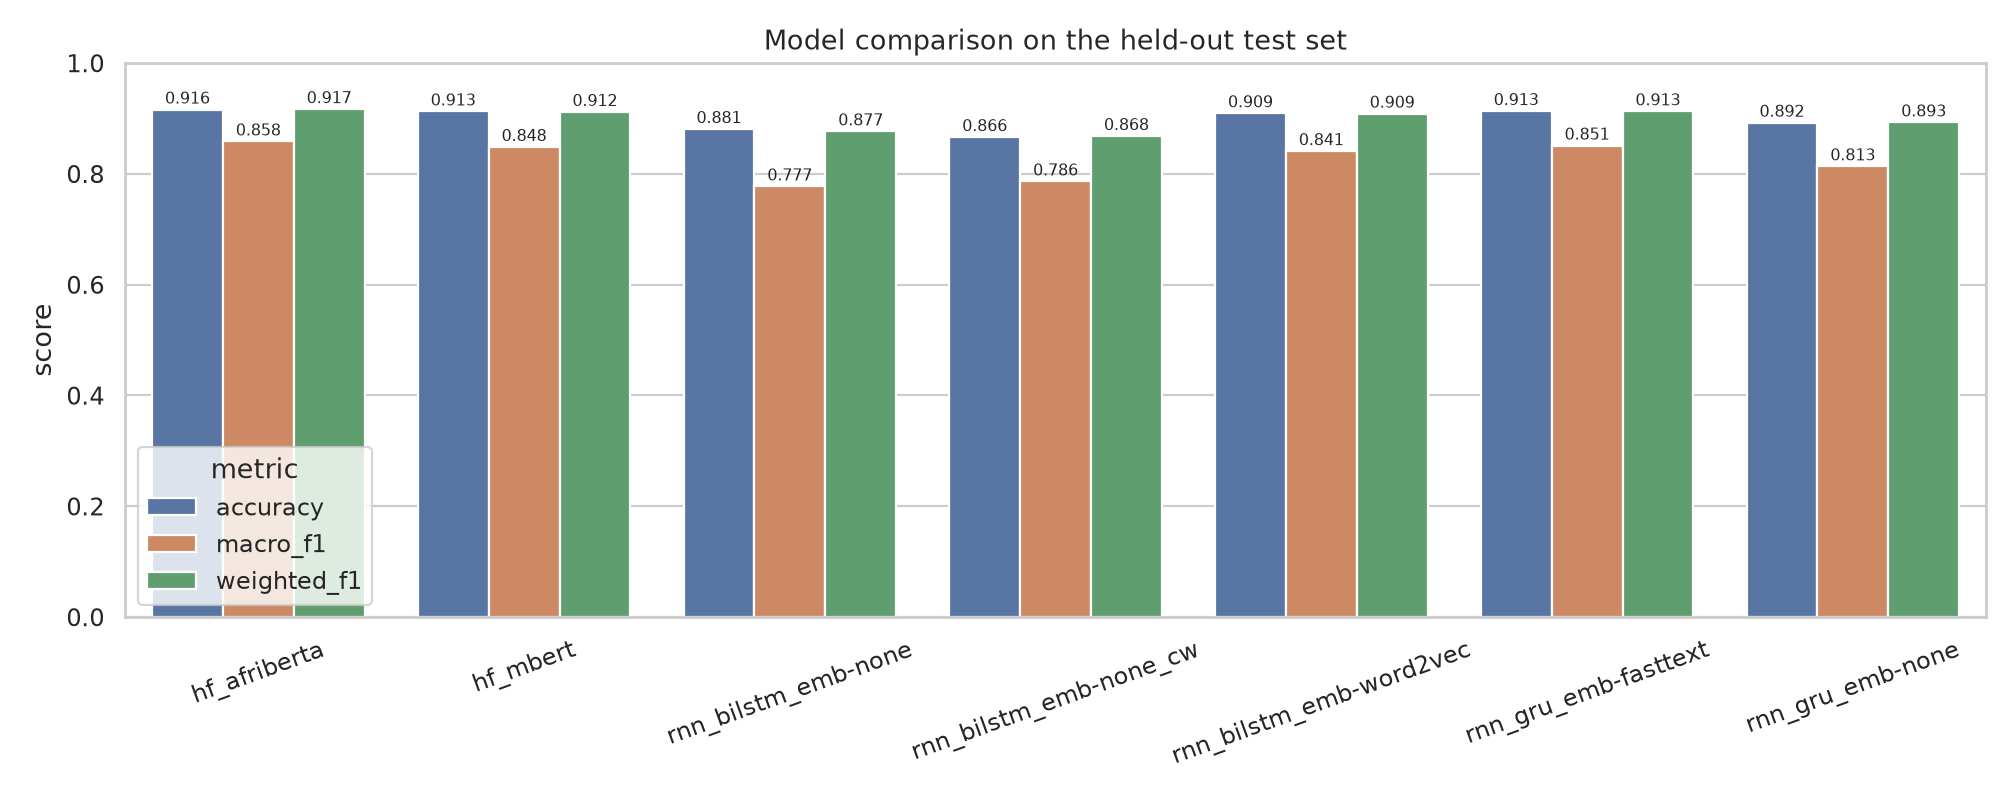

**tokenization_comparison_swahili_news.png**

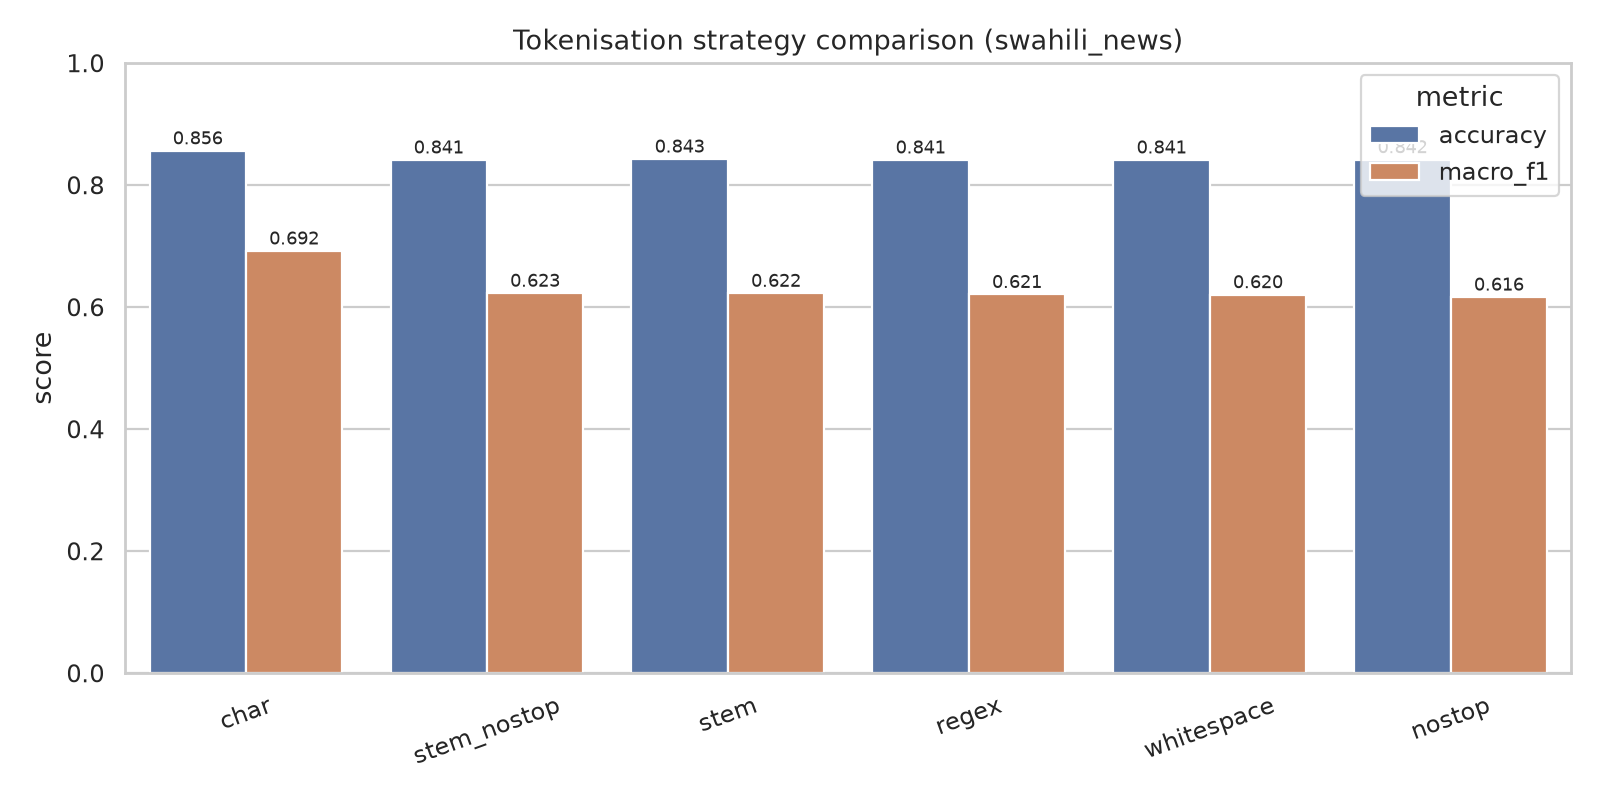

**label_distribution_swahili_news.png**

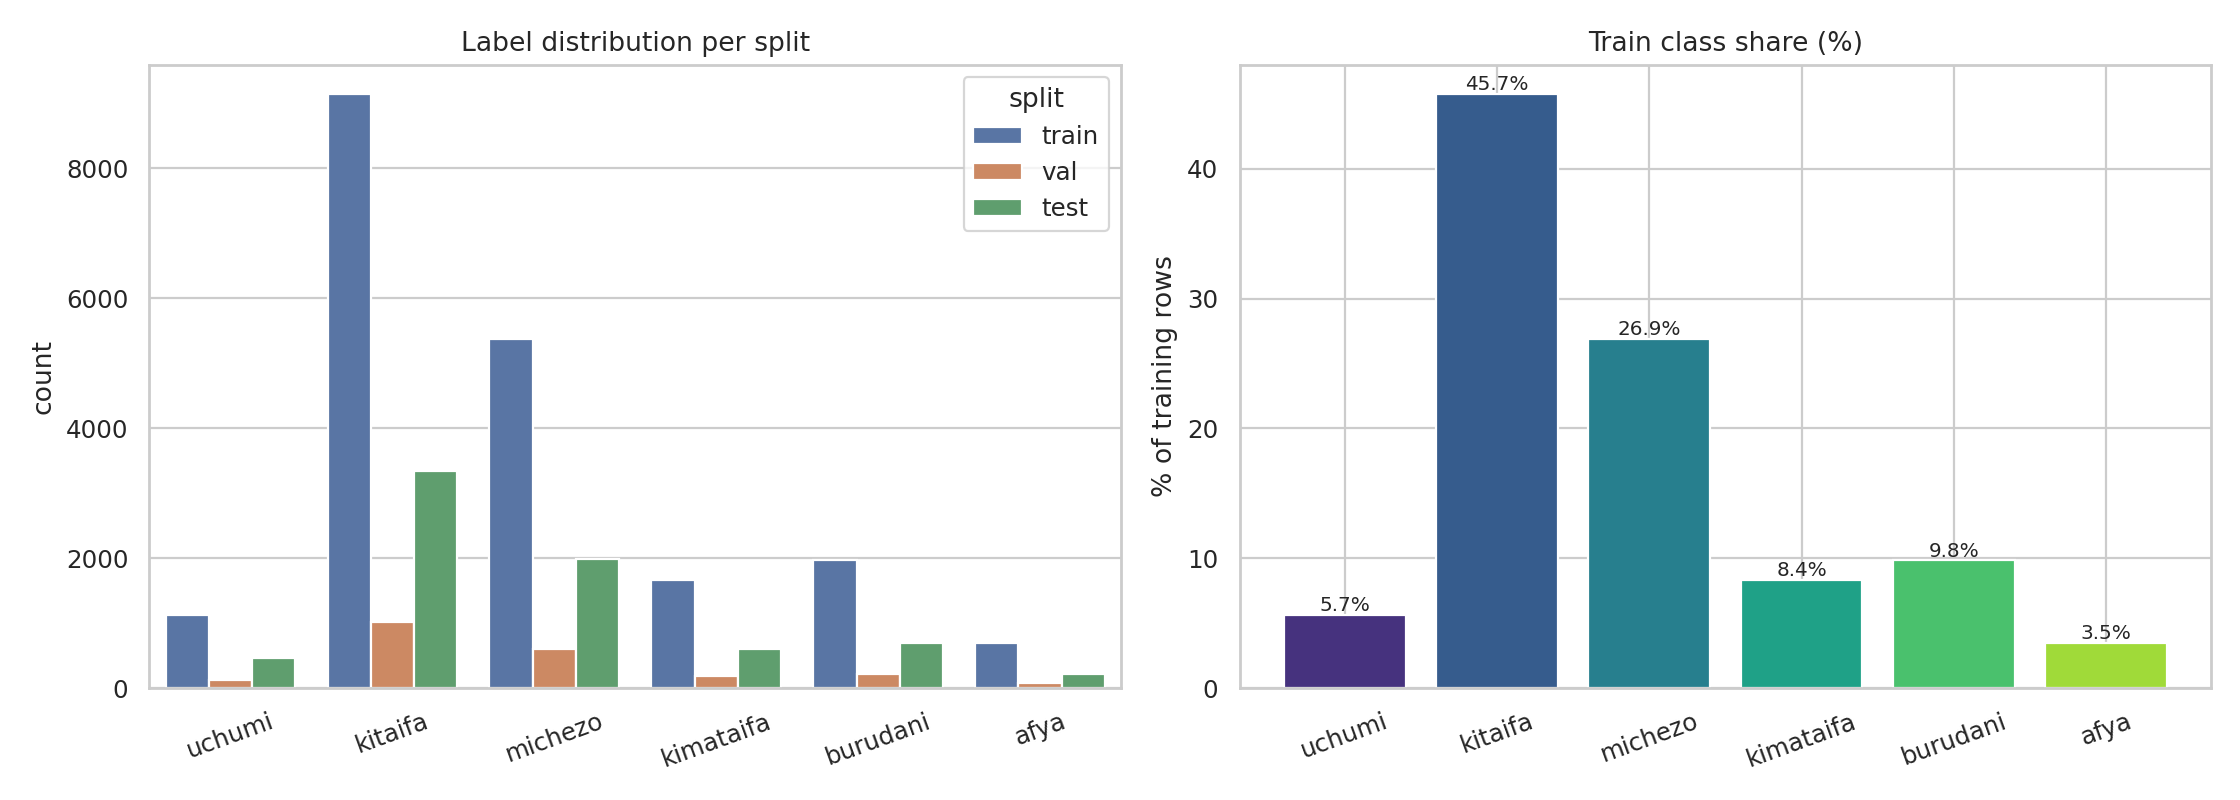

**text_length_distribution_swahili_news.png**

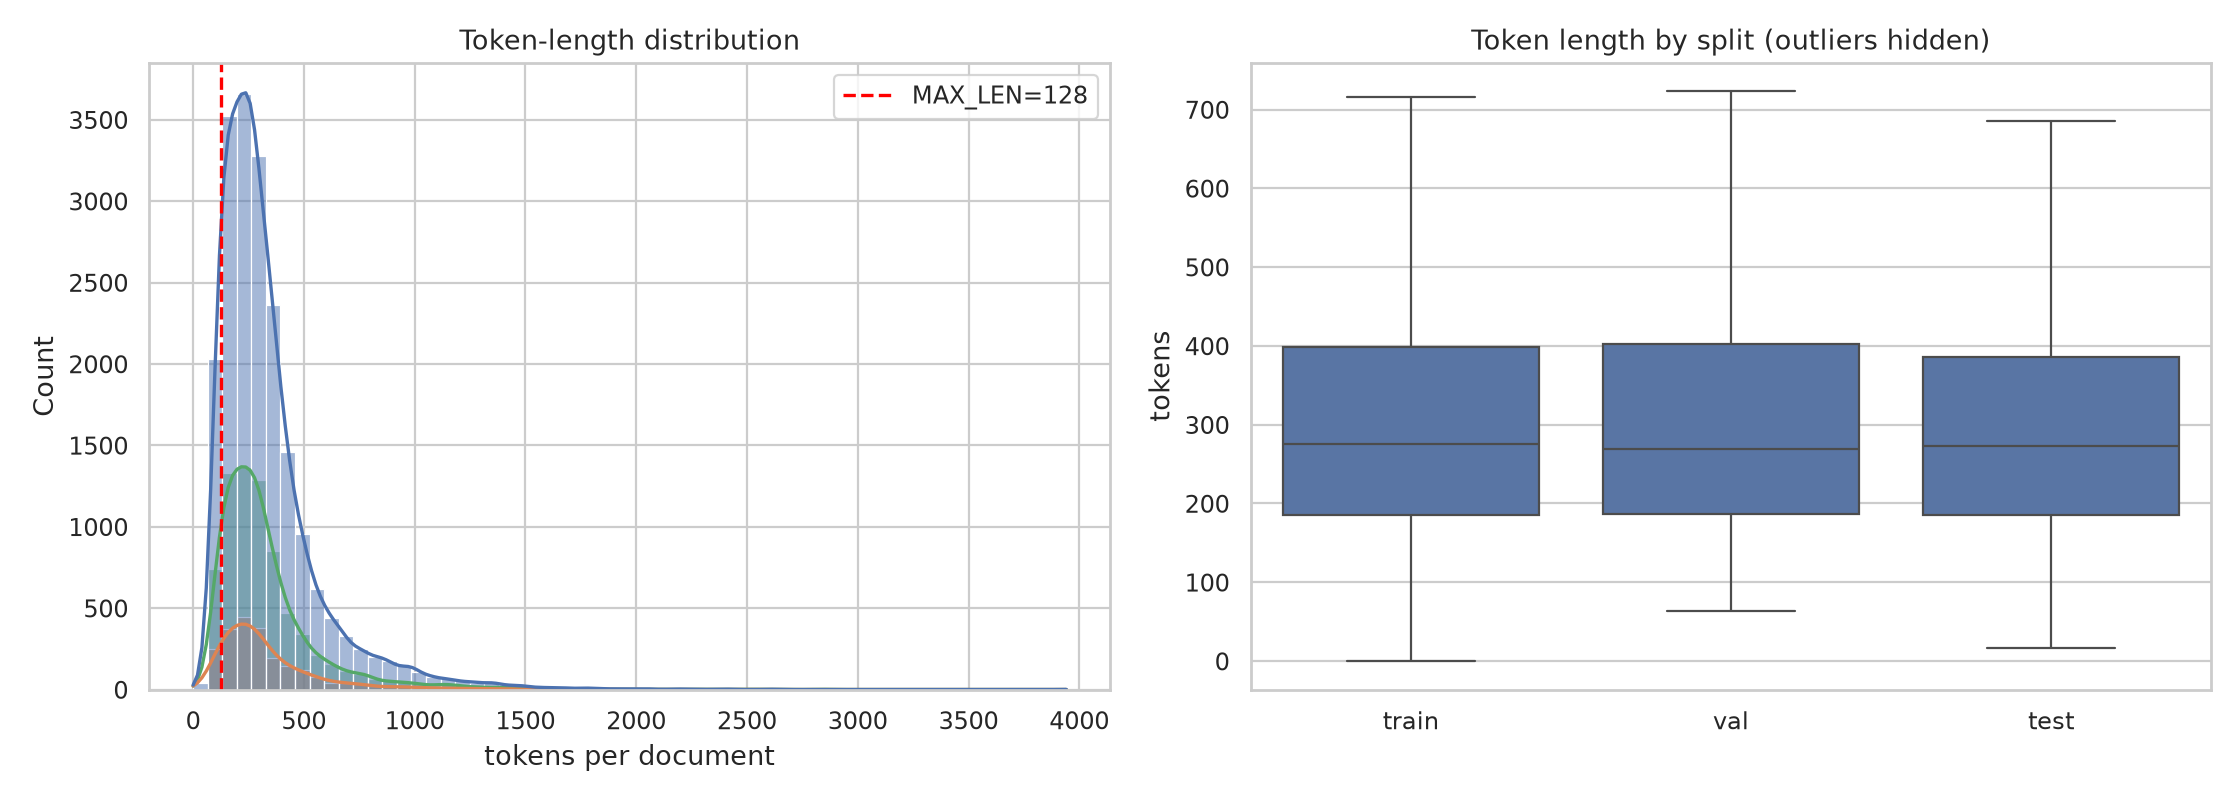

**wordcloud_overall_swahili_news.png**

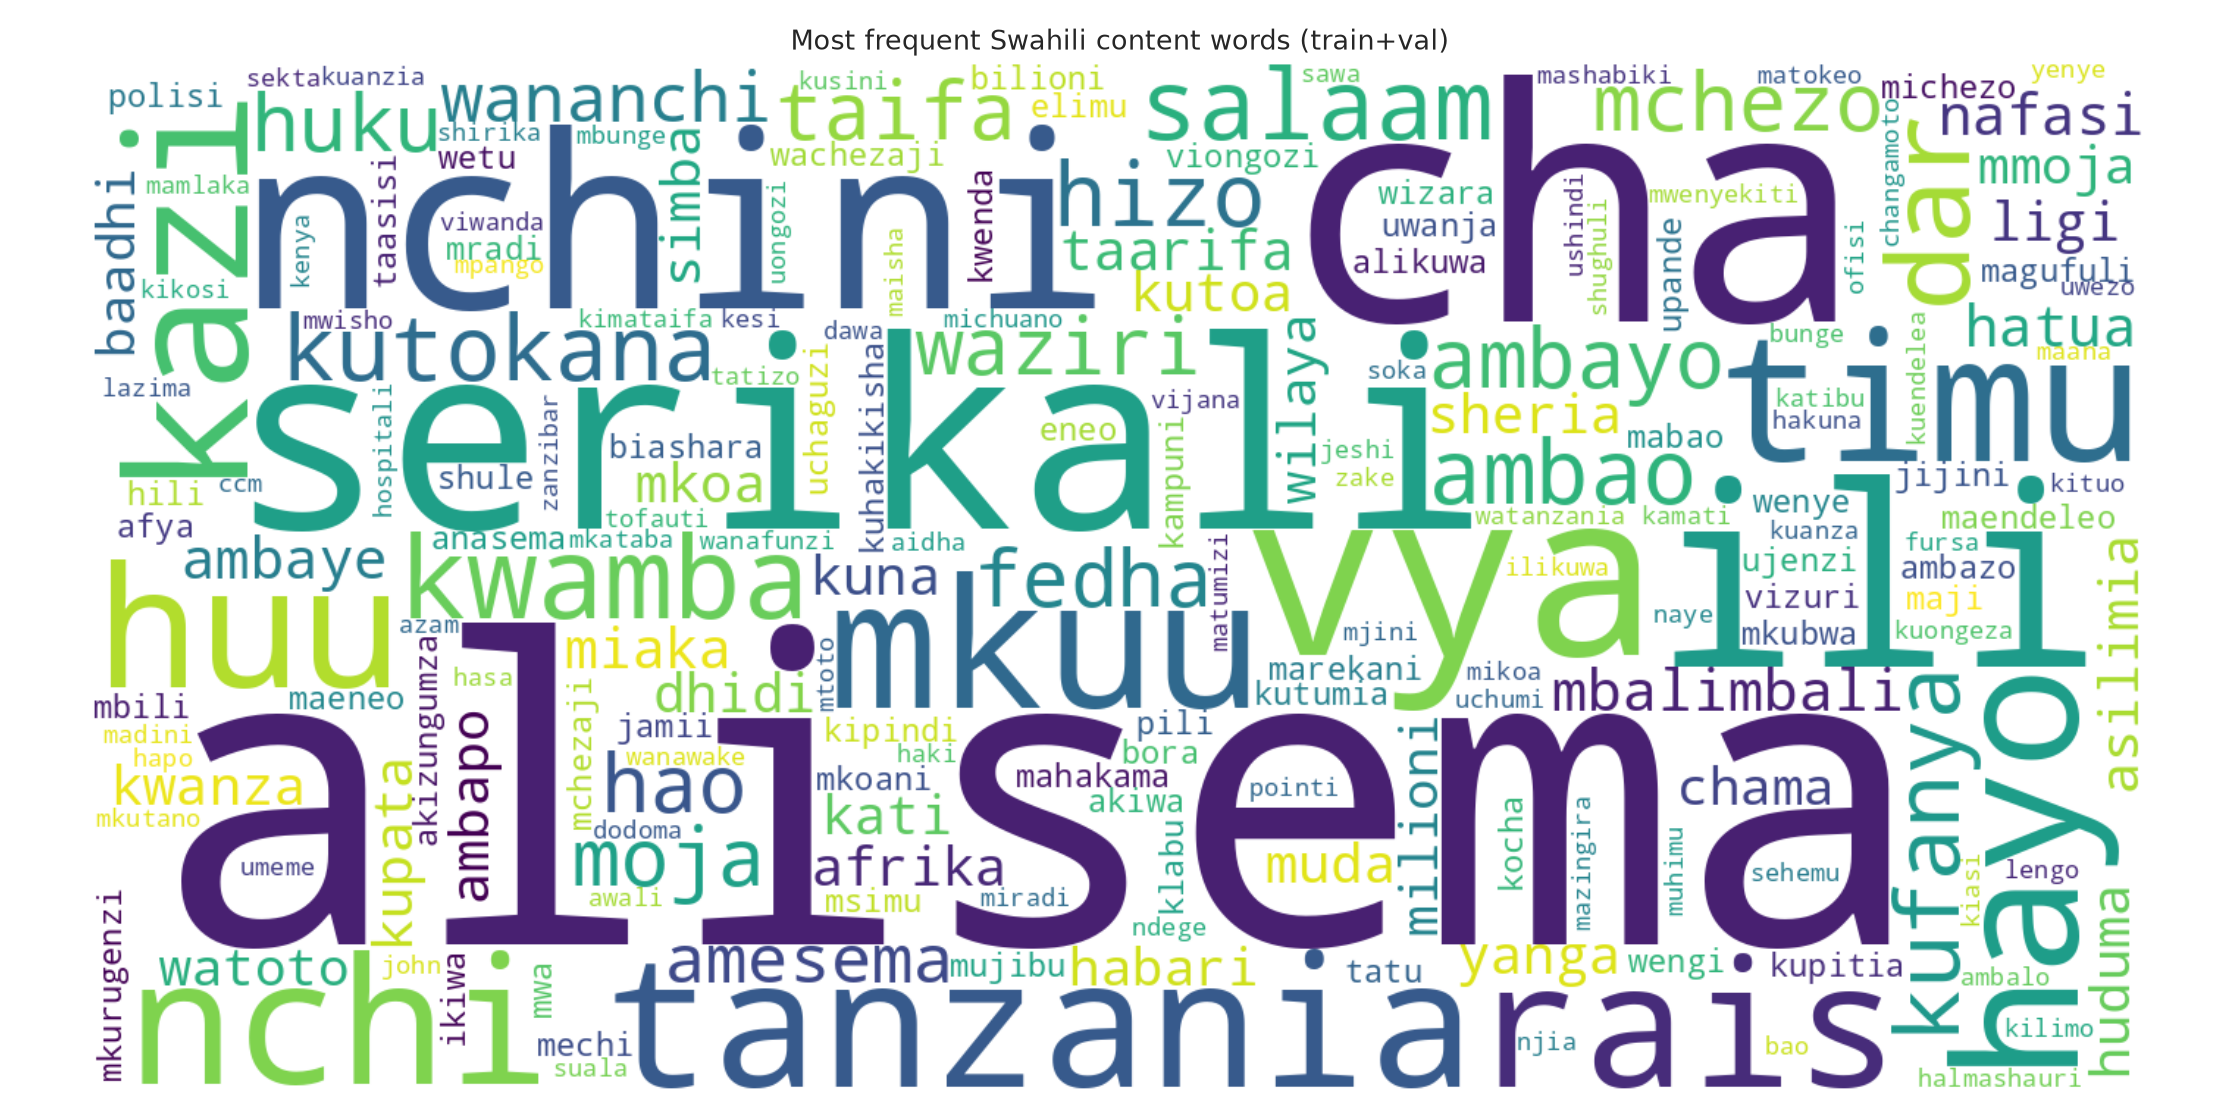

**wordcloud_per_class_swahili_news.png**

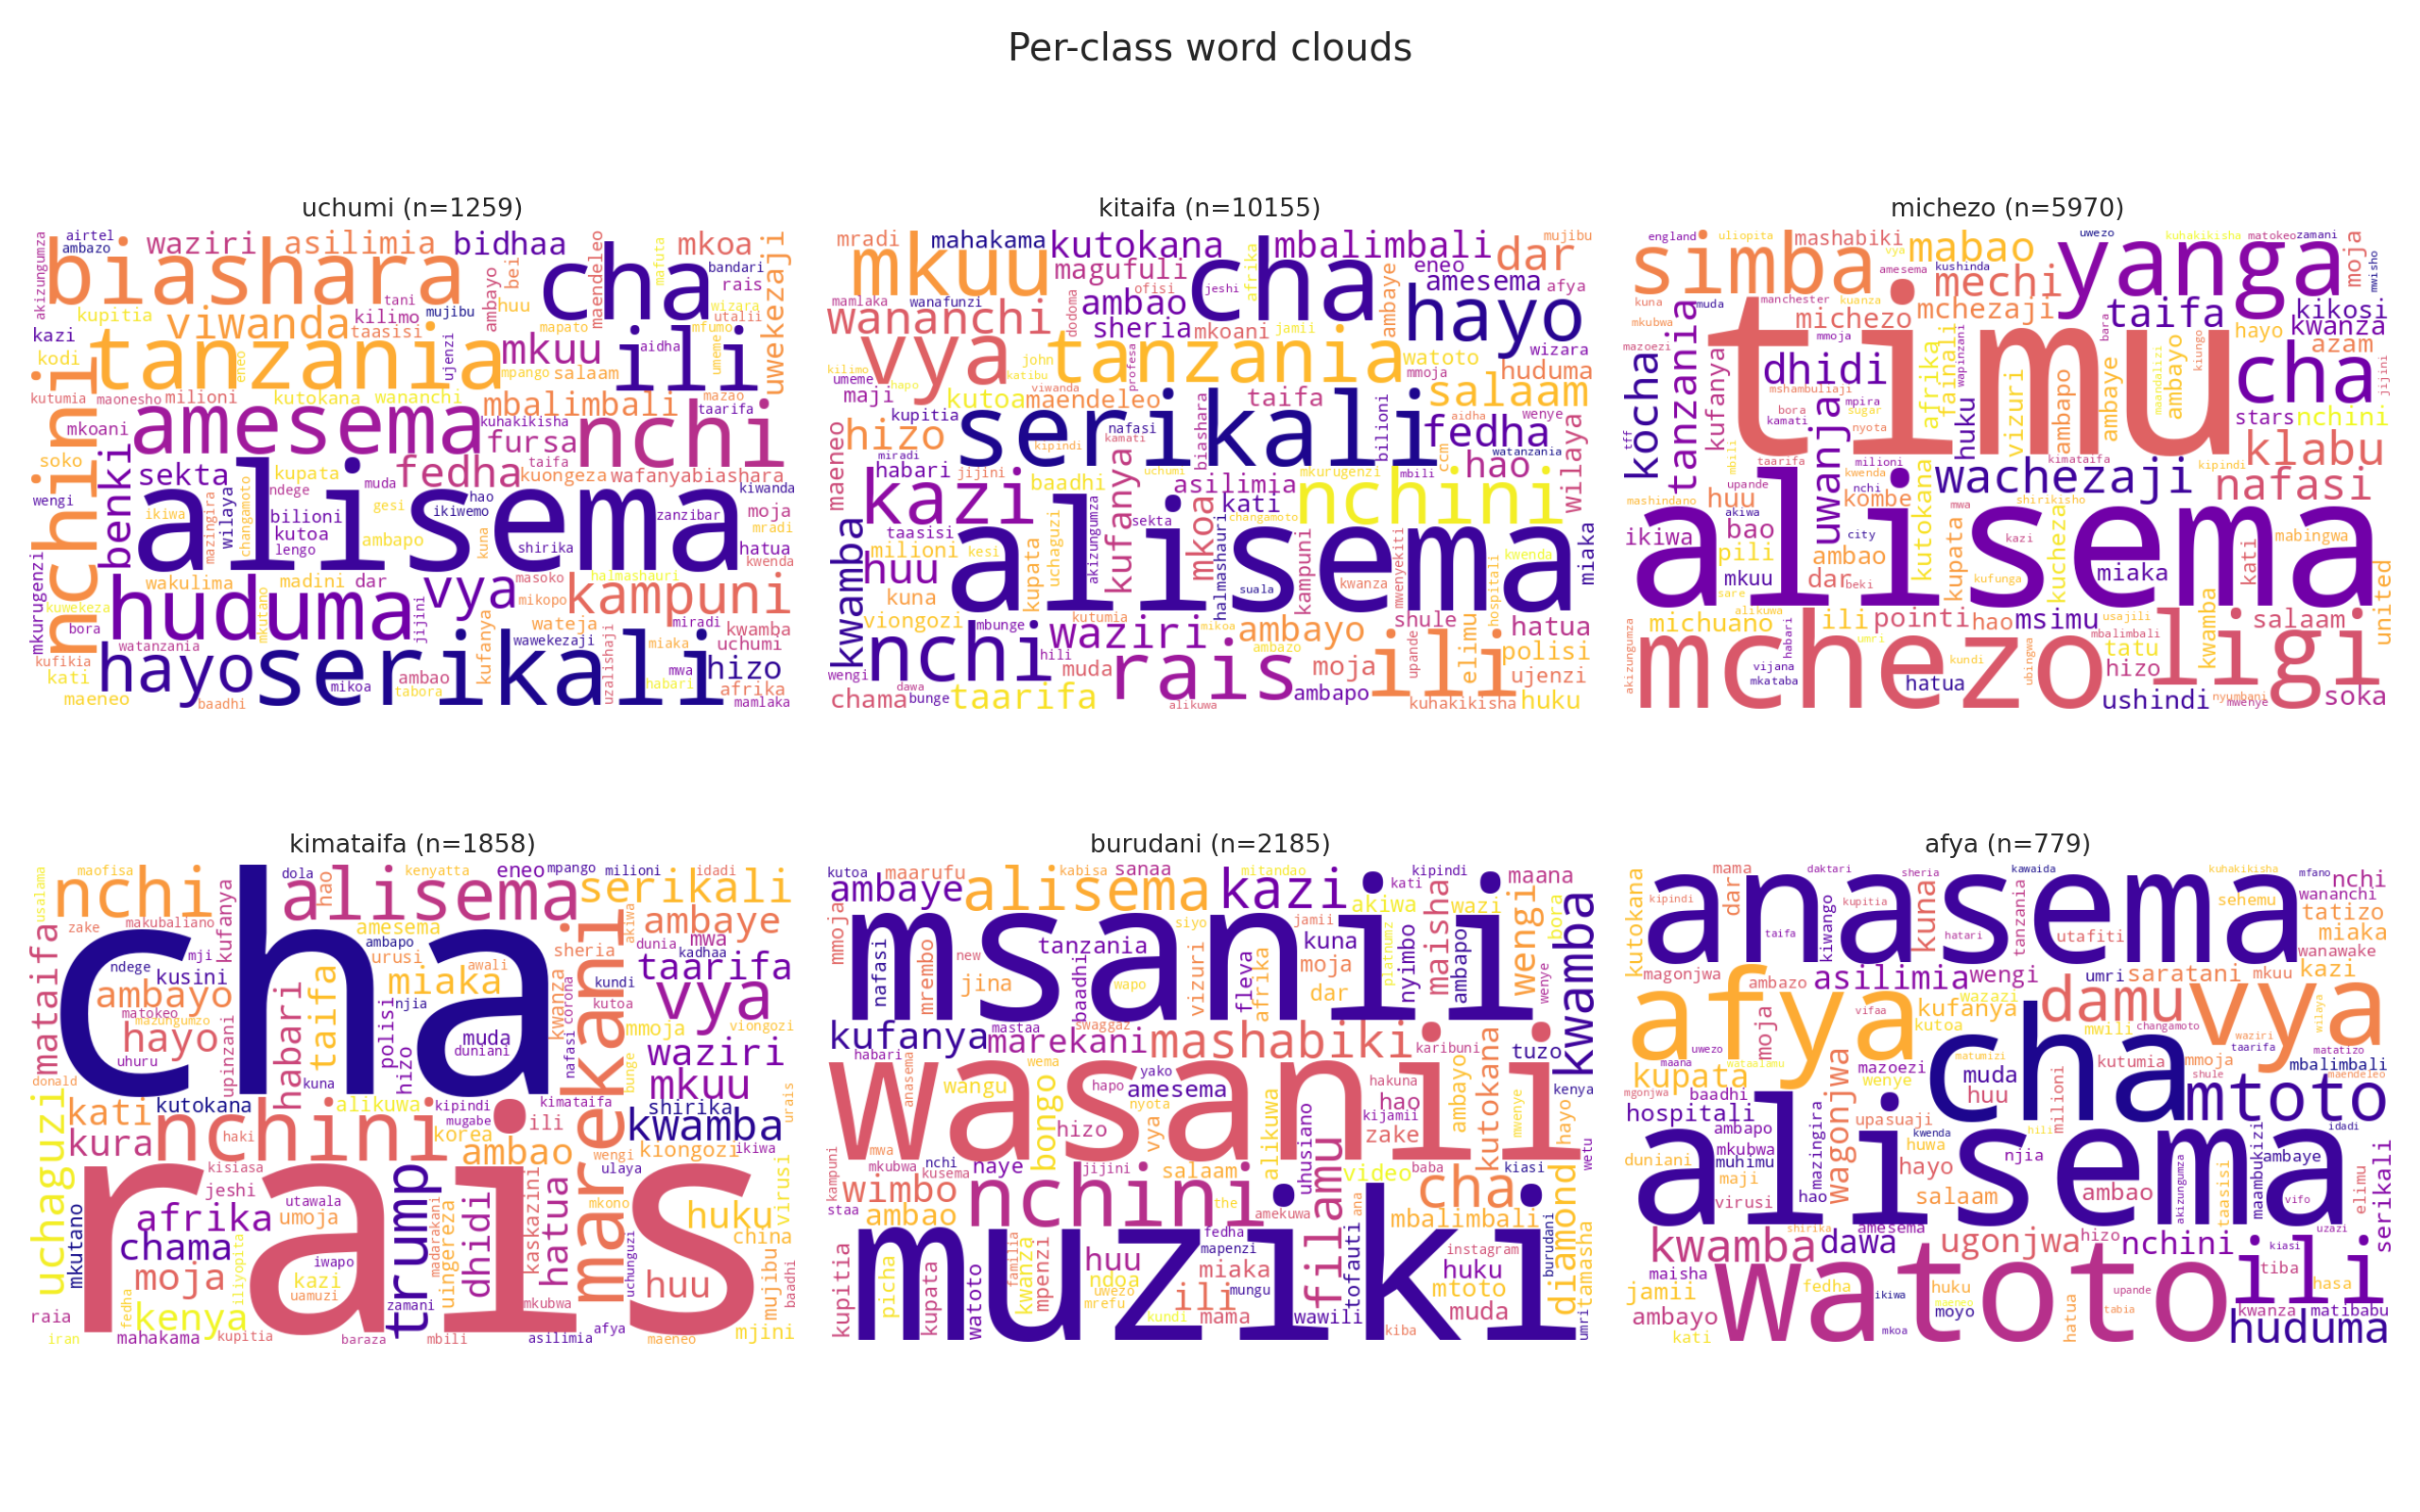

**top_words_per_class_swahili_news.png**

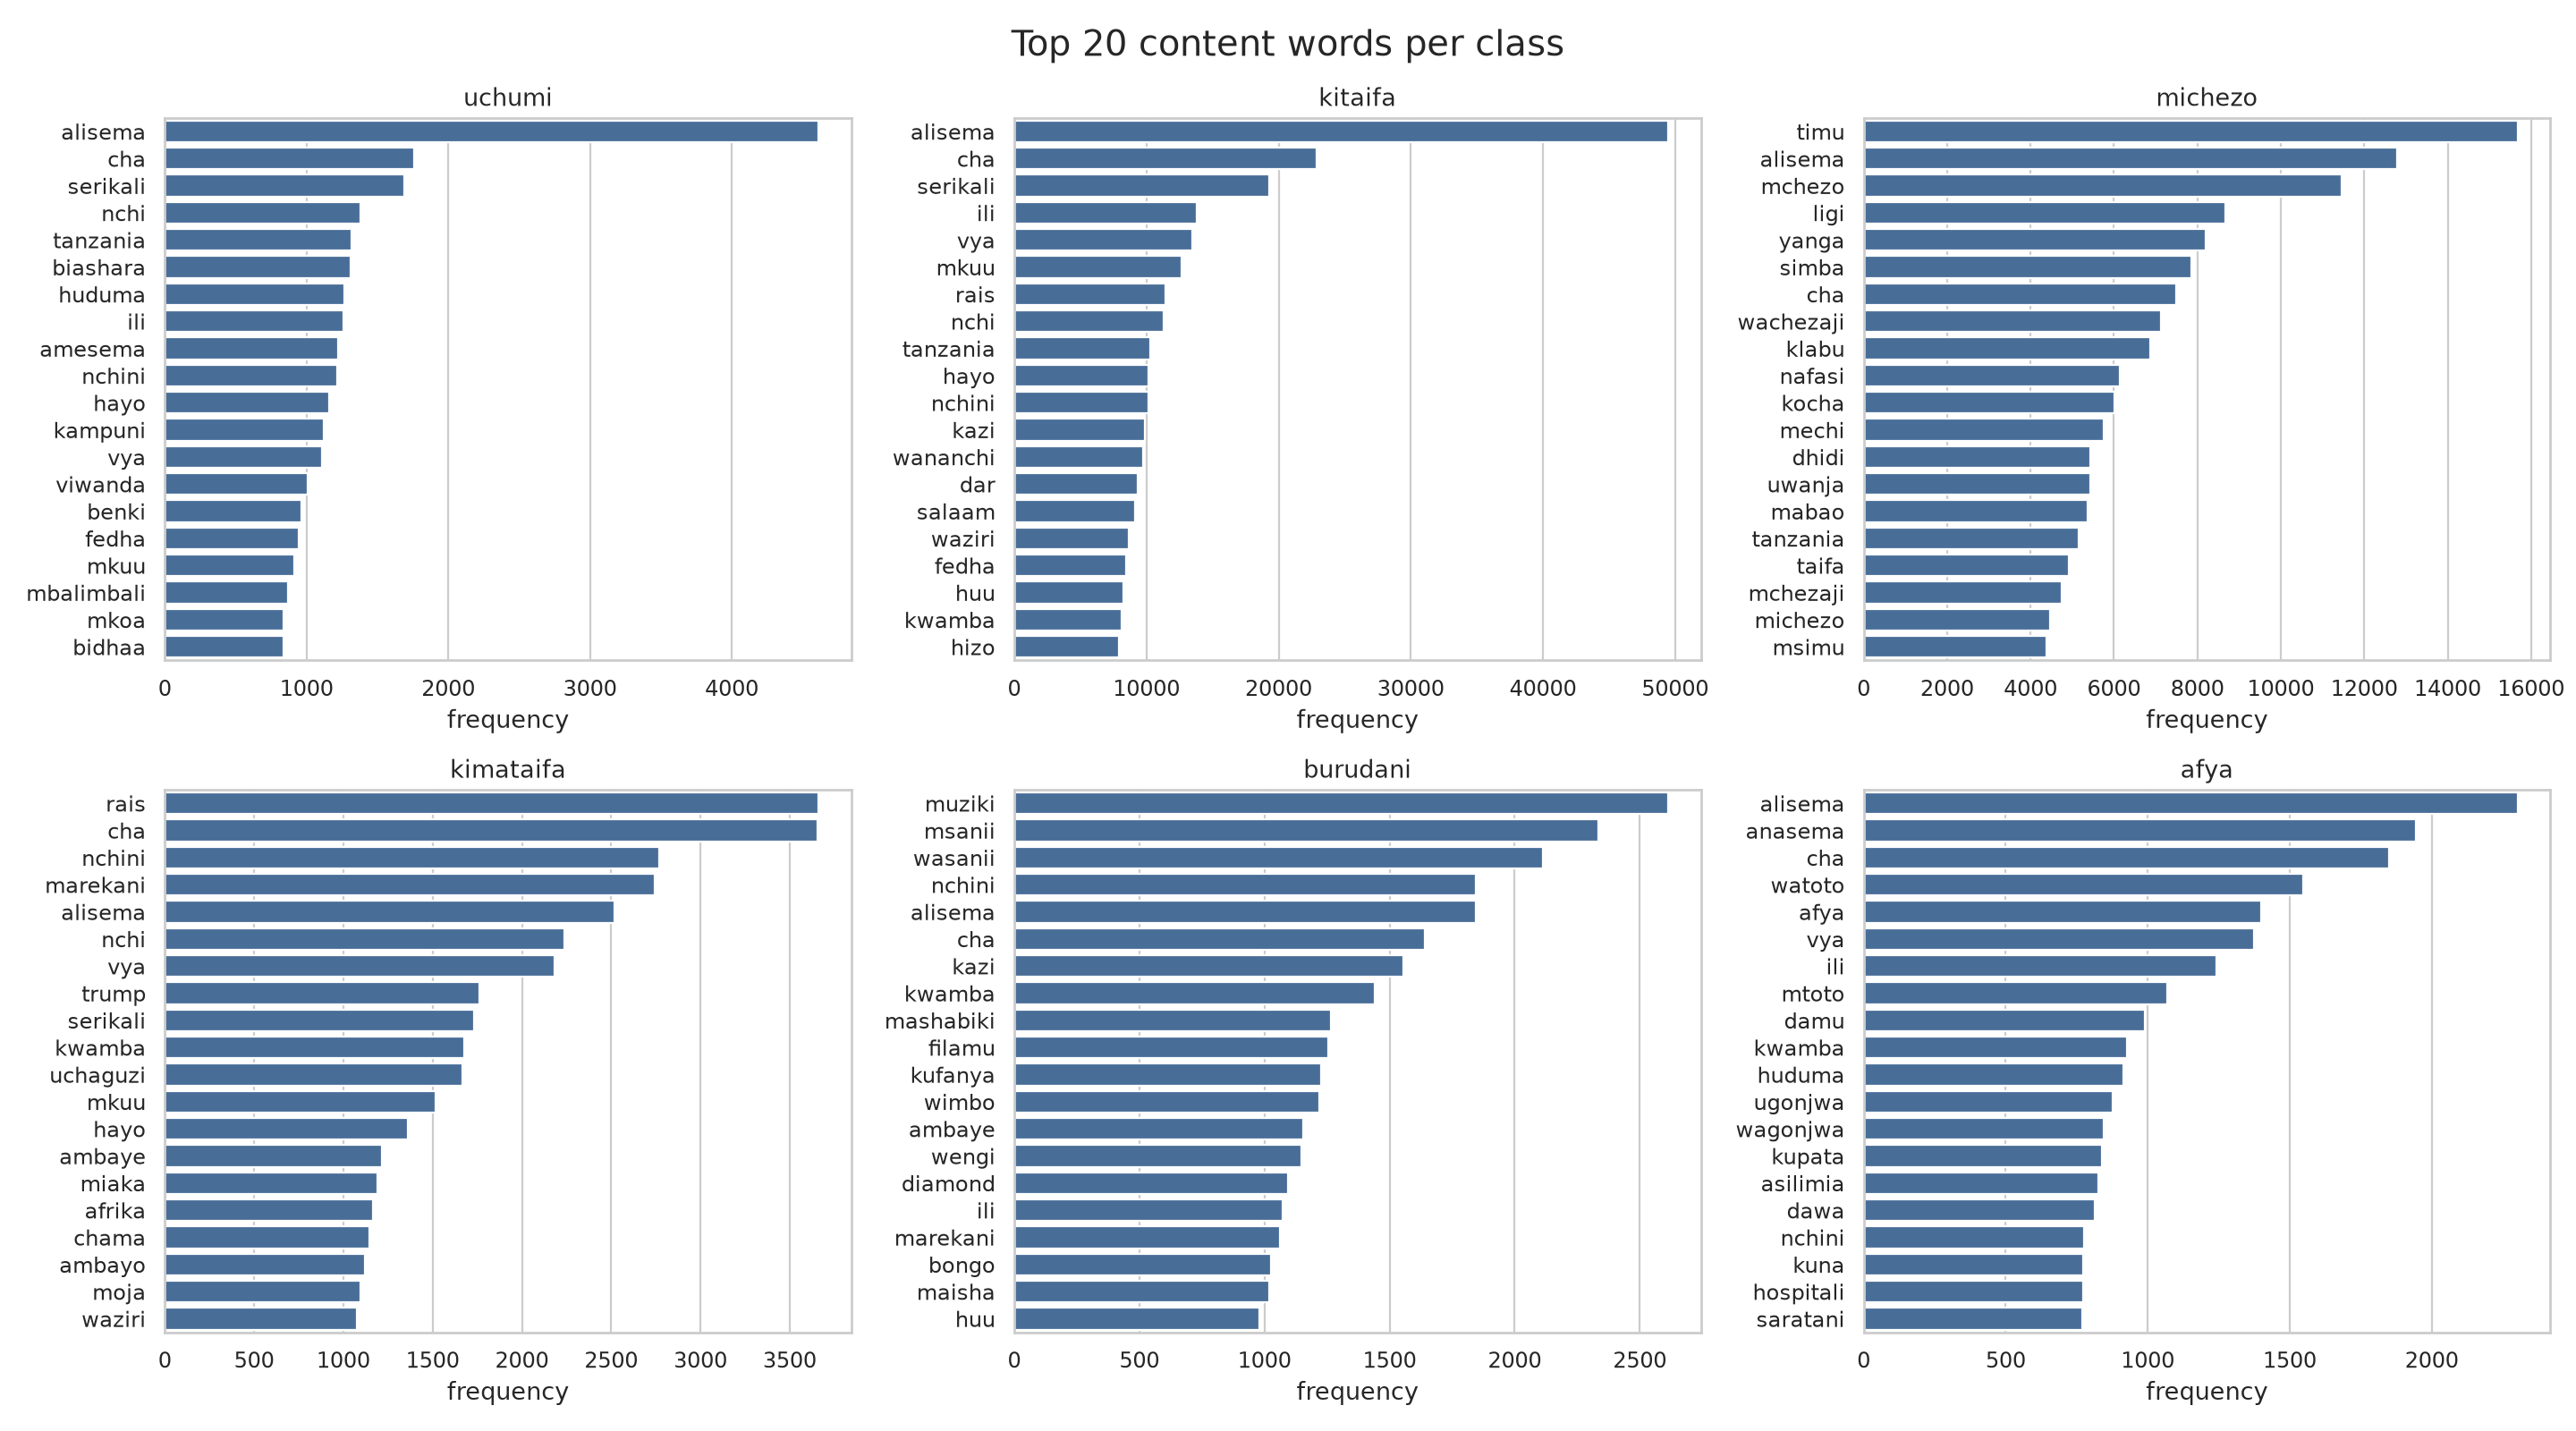

In [45]:
for name in ["model_comparison_swahili_news.png",
             "tokenization_comparison_swahili_news.png",
             "label_distribution_swahili_news.png",
             "text_length_distribution_swahili_news.png",
             "wordcloud_overall_swahili_news.png",
             "wordcloud_per_class_swahili_news.png",
             "top_words_per_class_swahili_news.png"]:
    p = FIG_DIR / name
    if p.exists():
        display(Markdown(f"**{name}**"))
        display(Image(filename=str(p)))

**tsne_documents_fasttext_swahili_news.png**

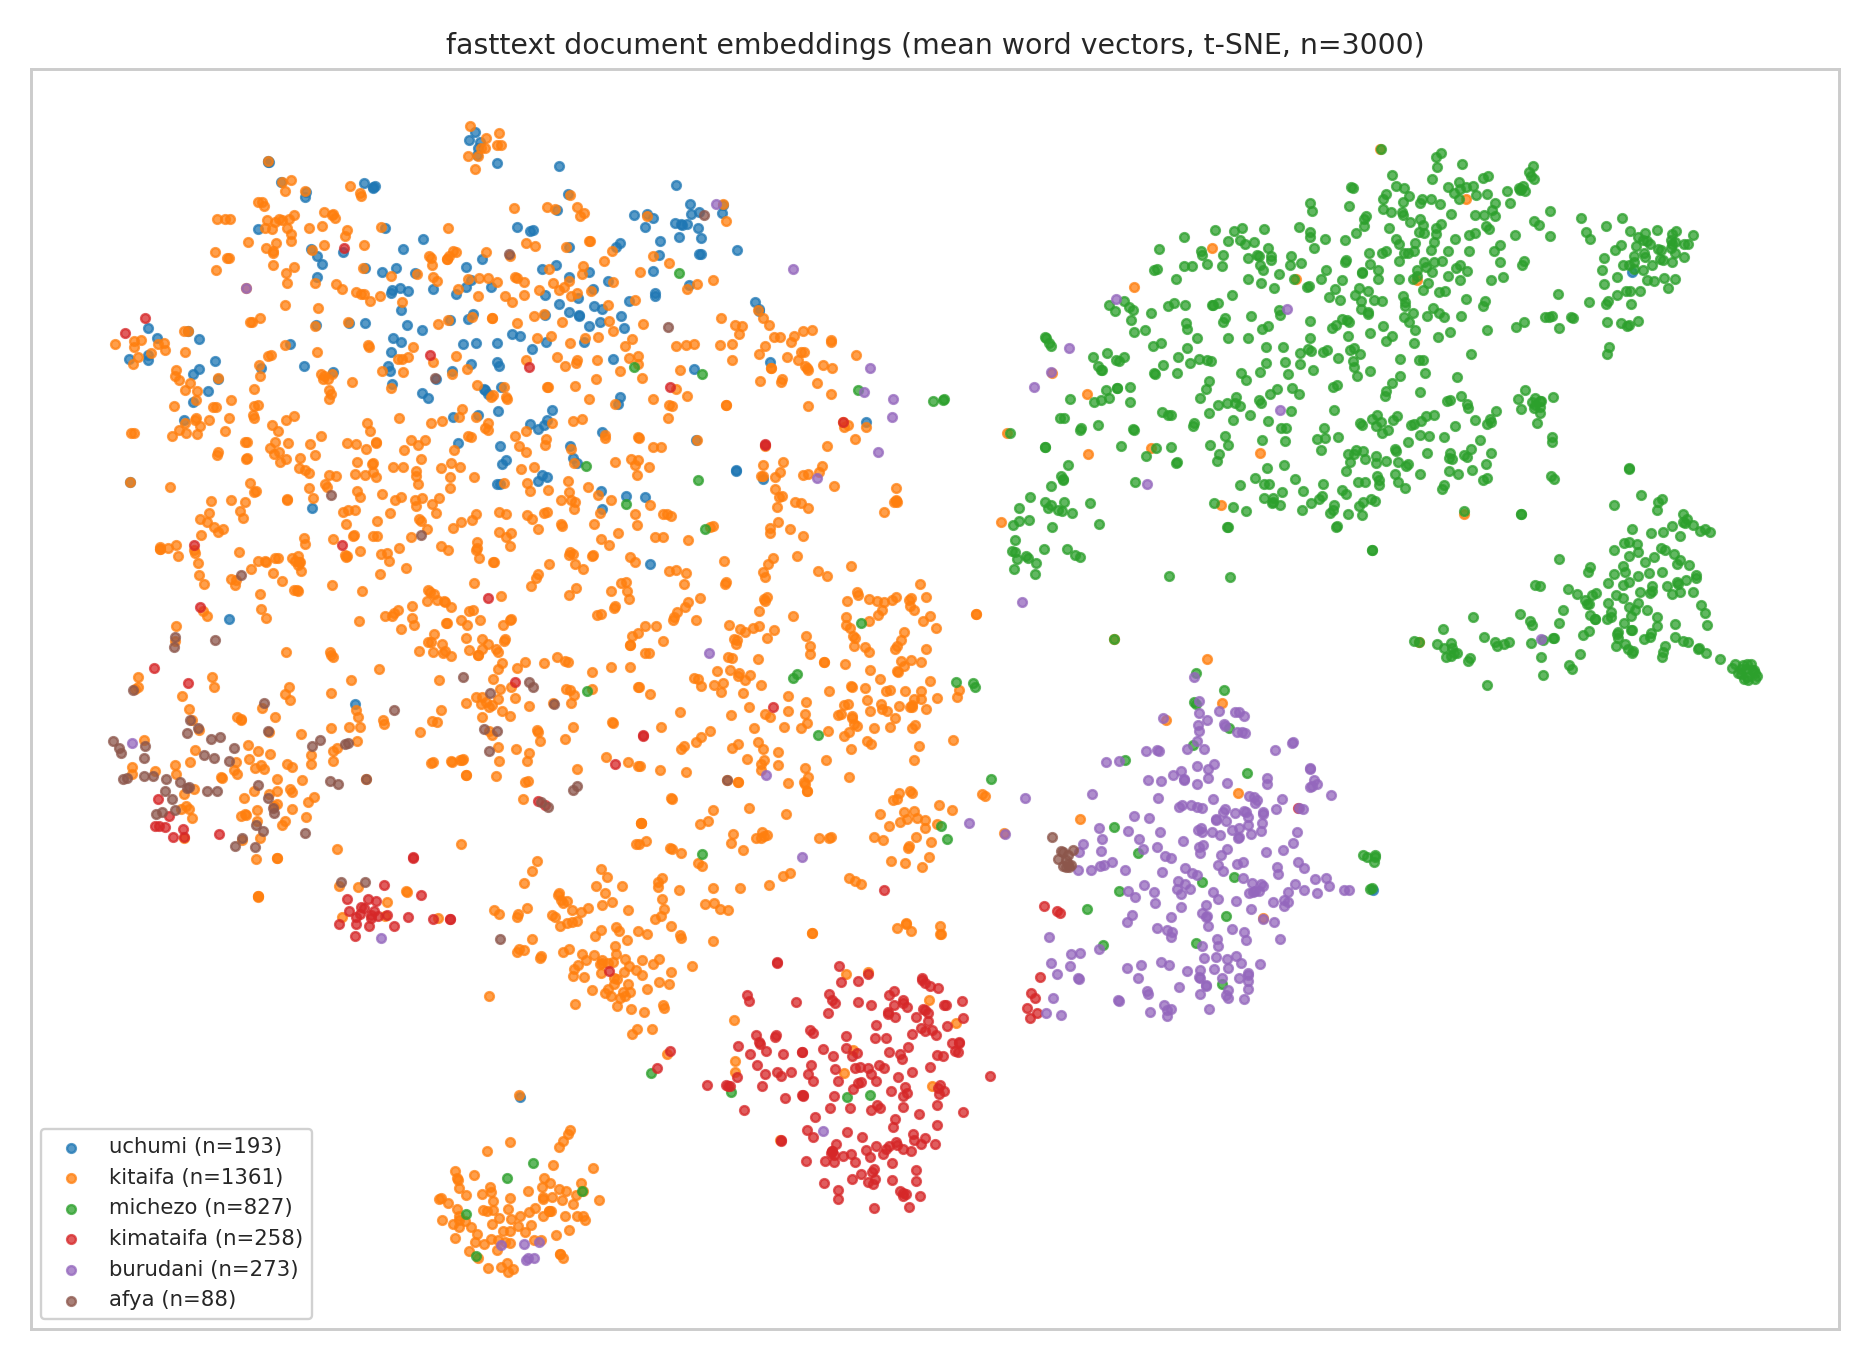

**tsne_documents_word2vec_swahili_news.png**

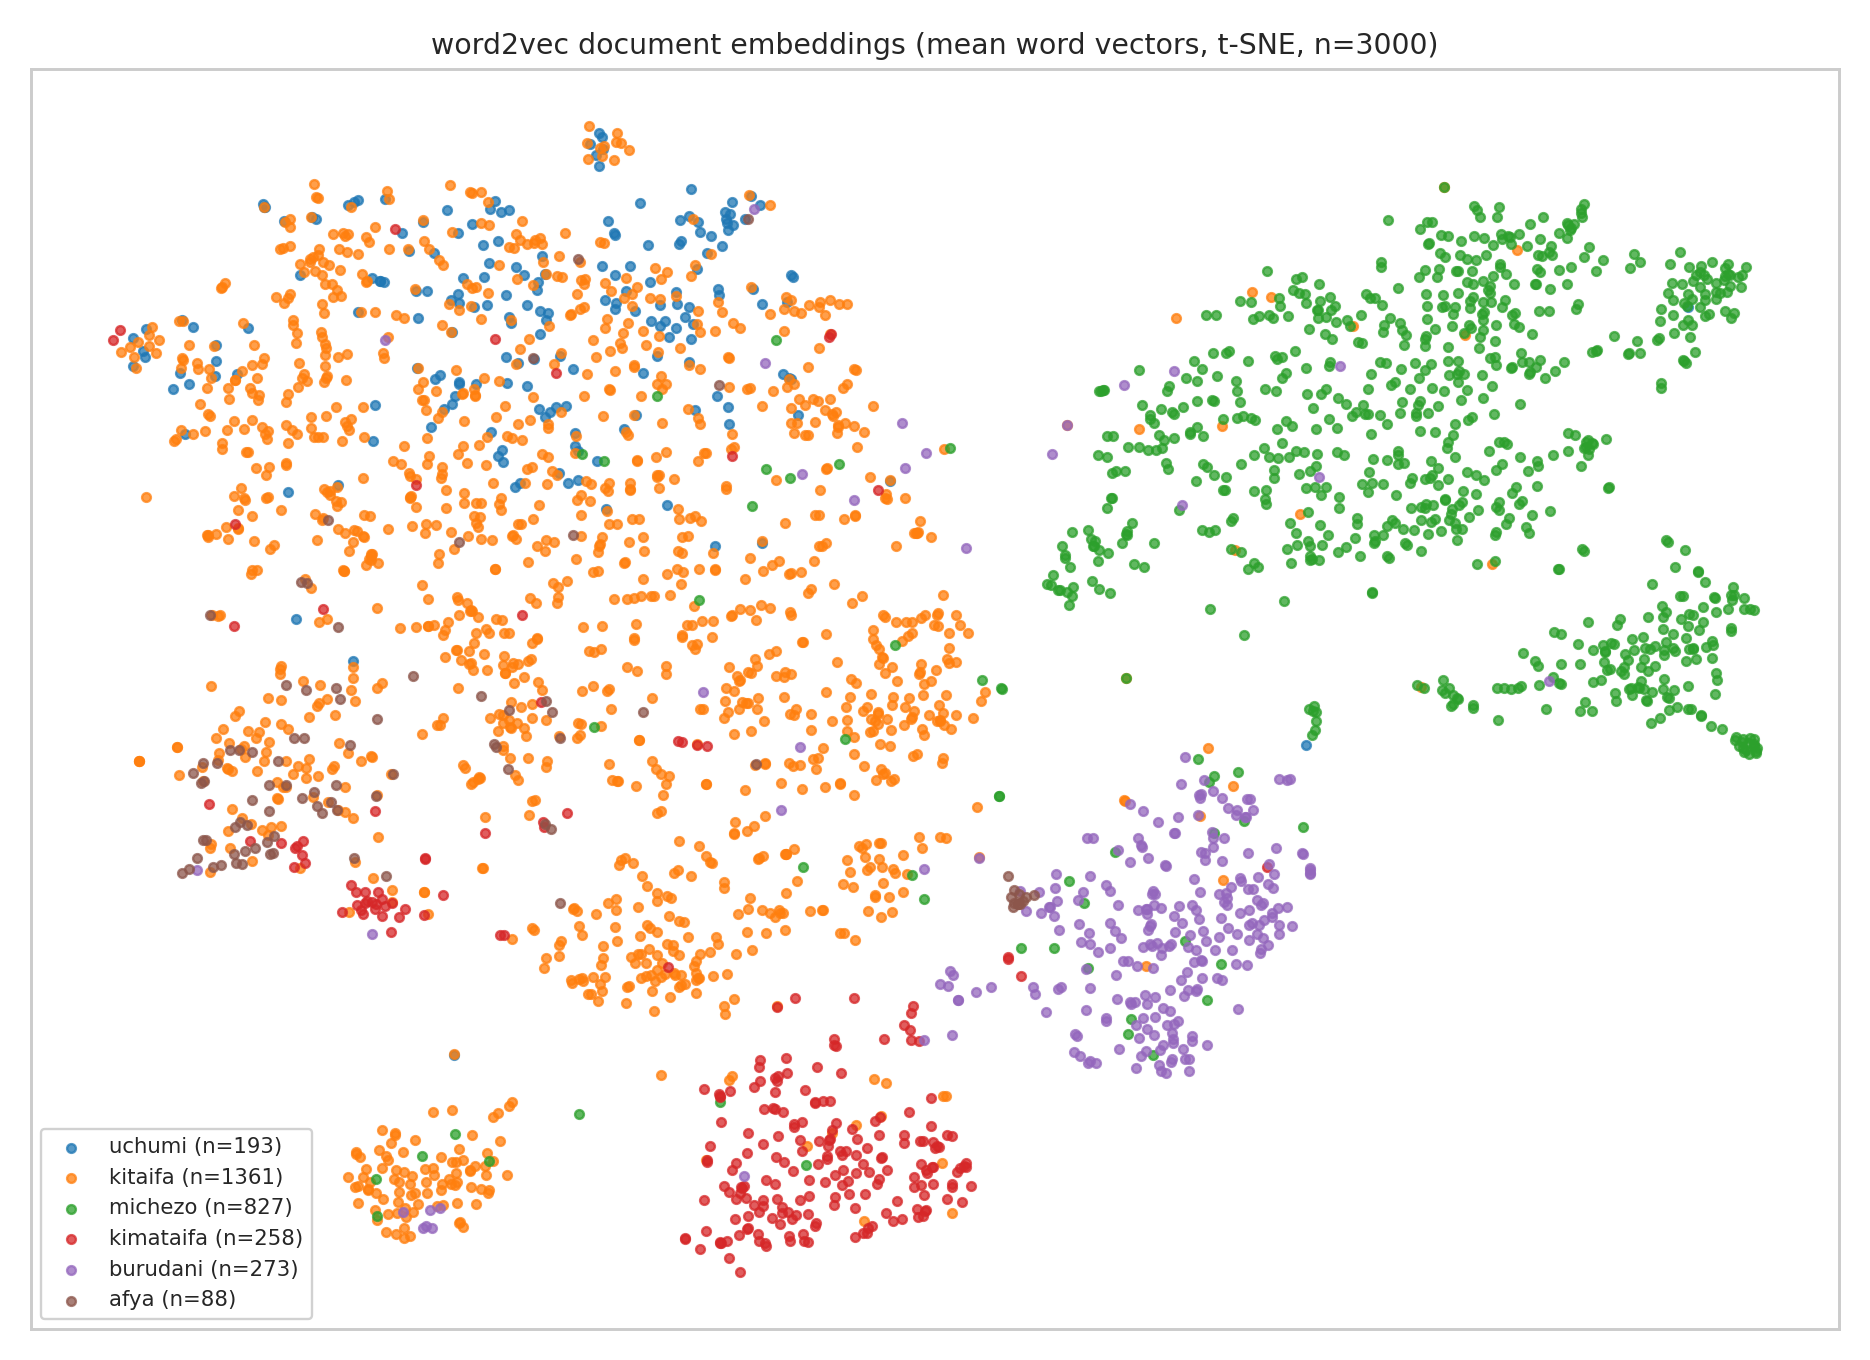

**tsne_transformer_best_swahili_news.png**

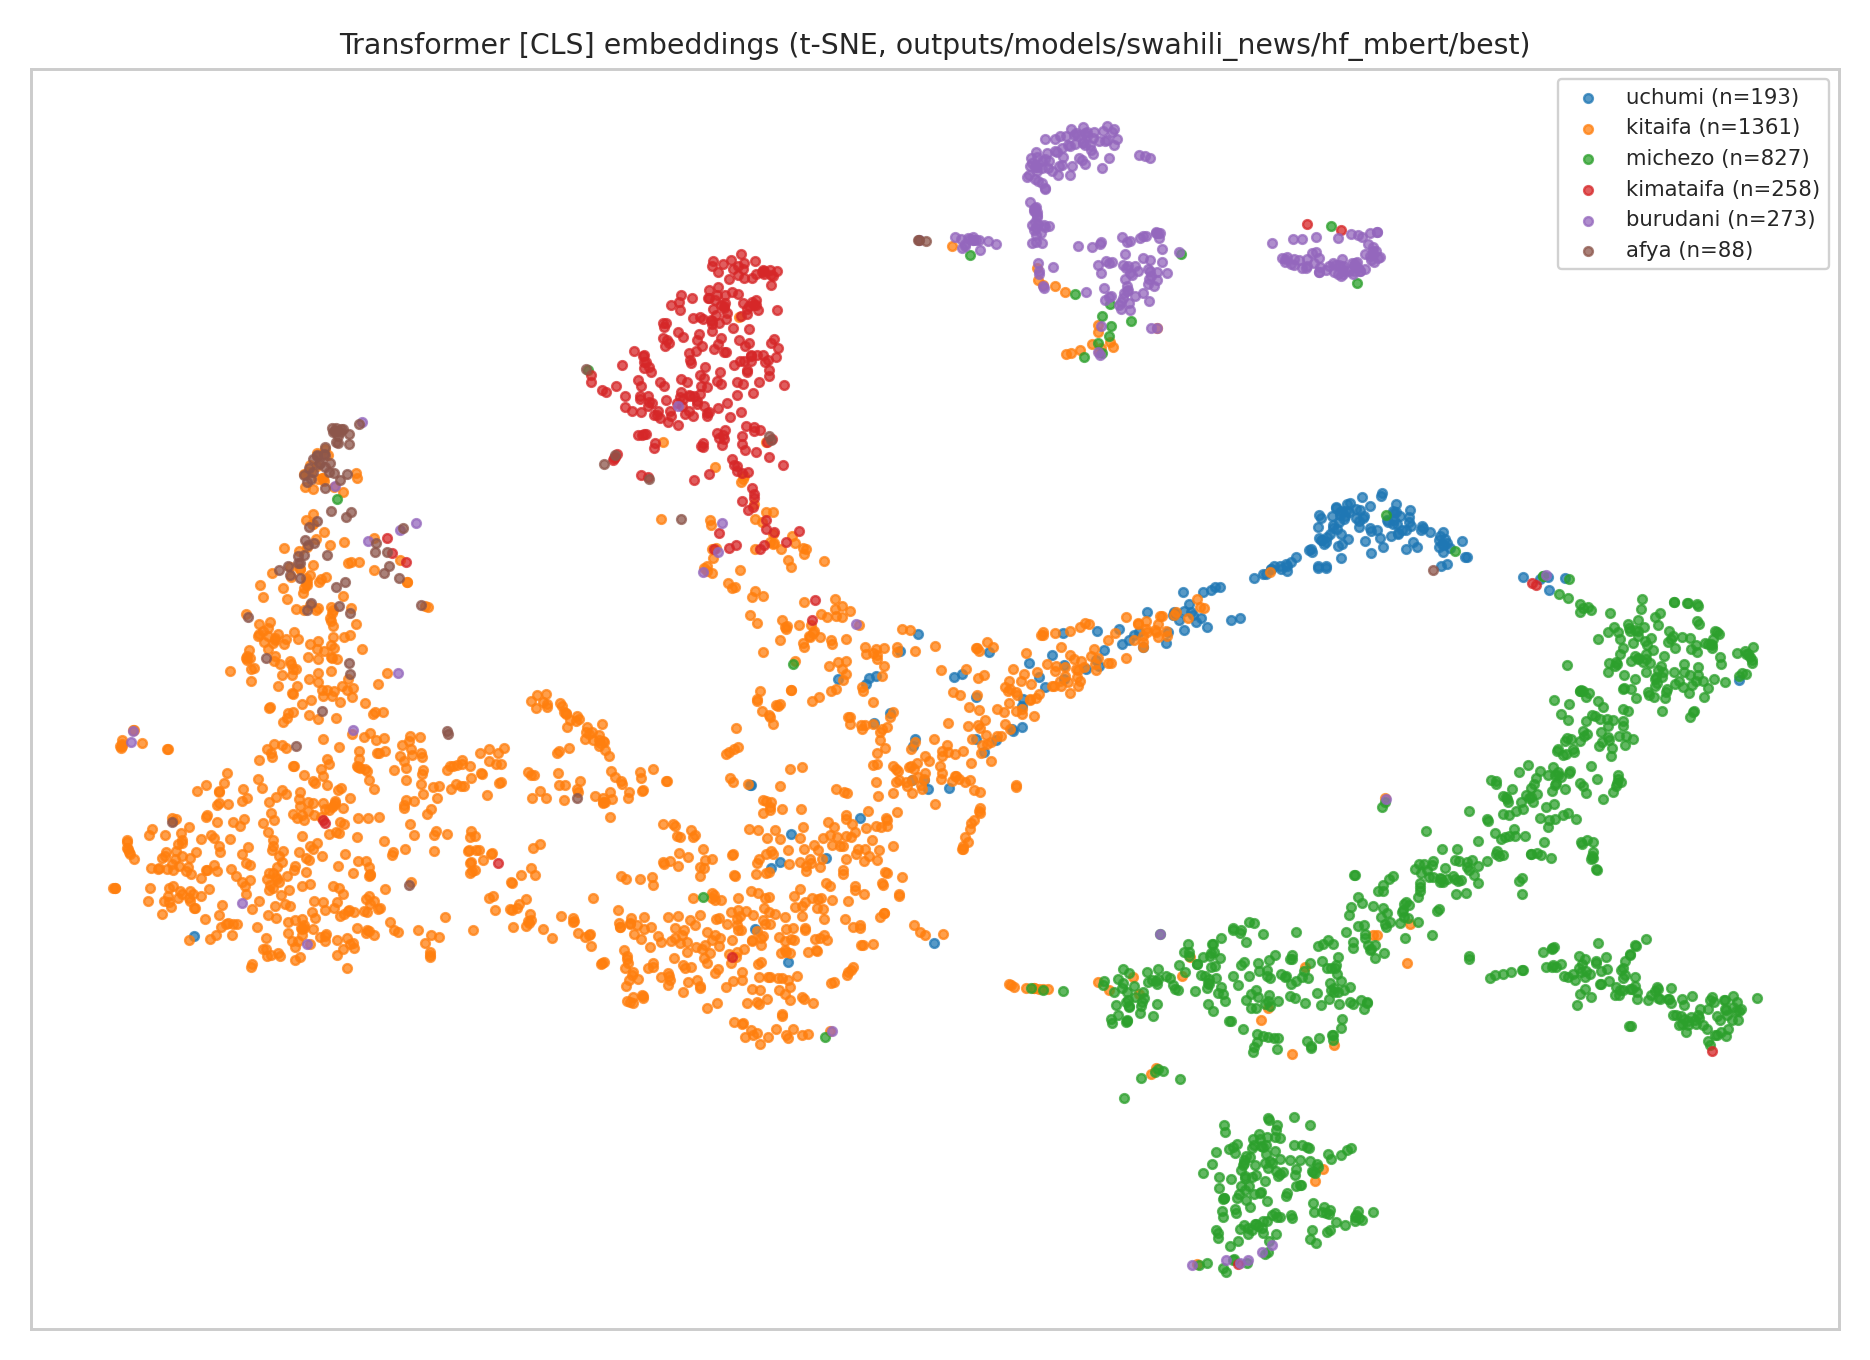

**hf_afriberta.history.png**

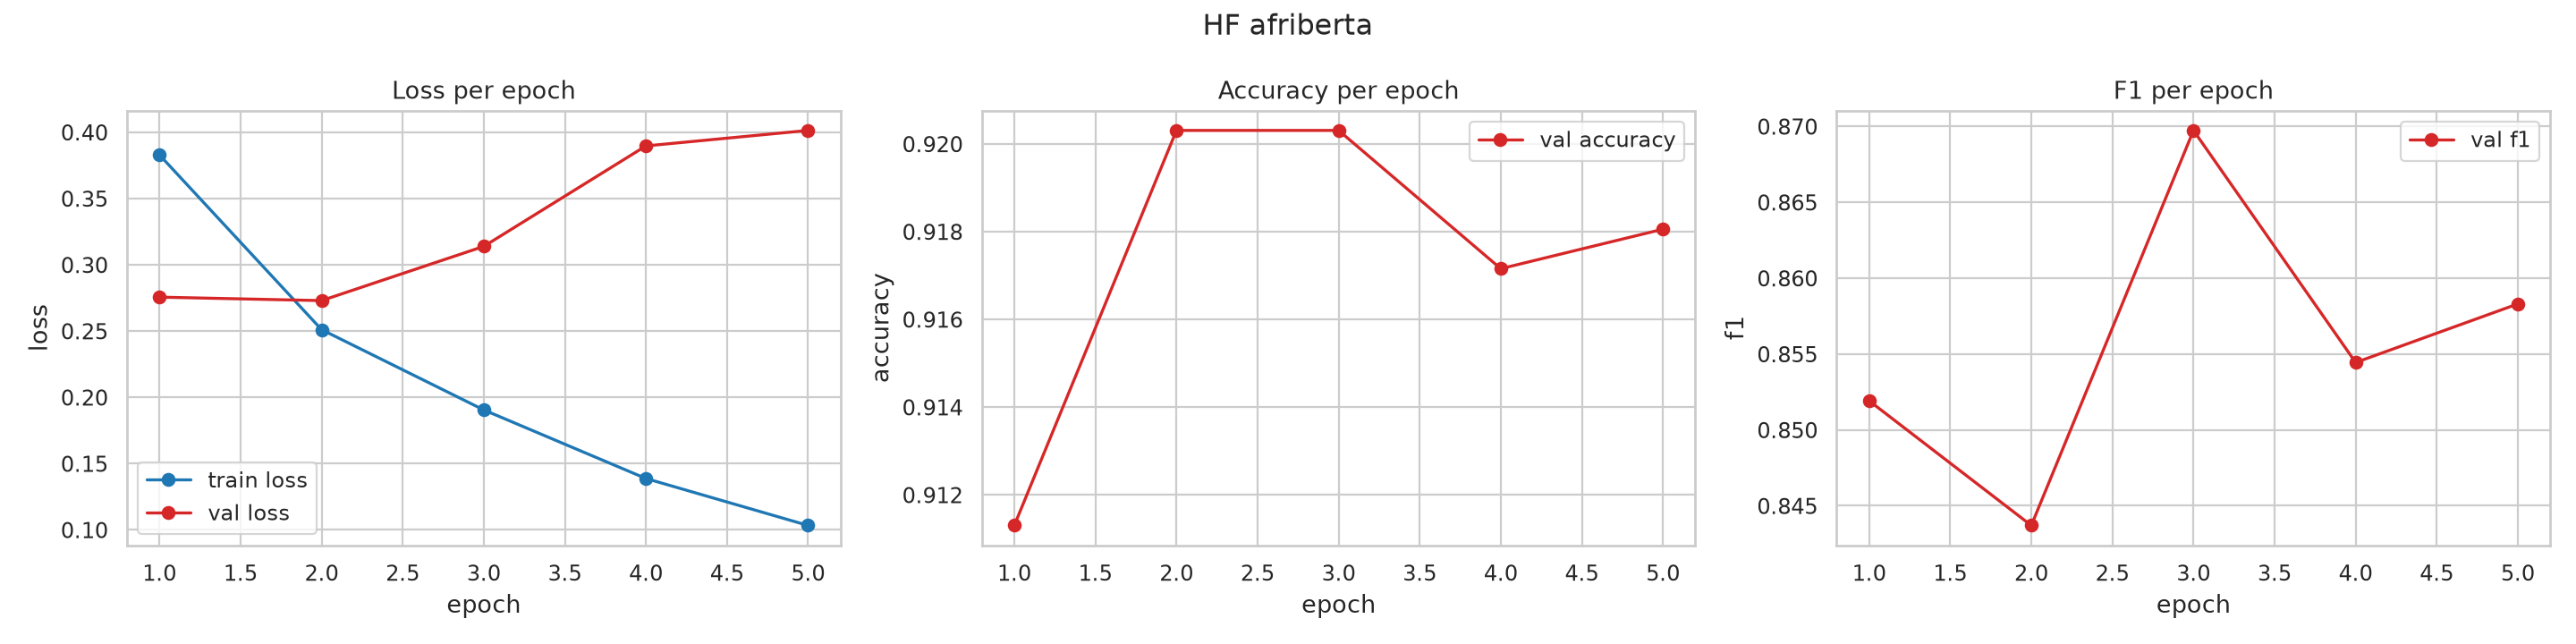

**hf_mbert.history.png**

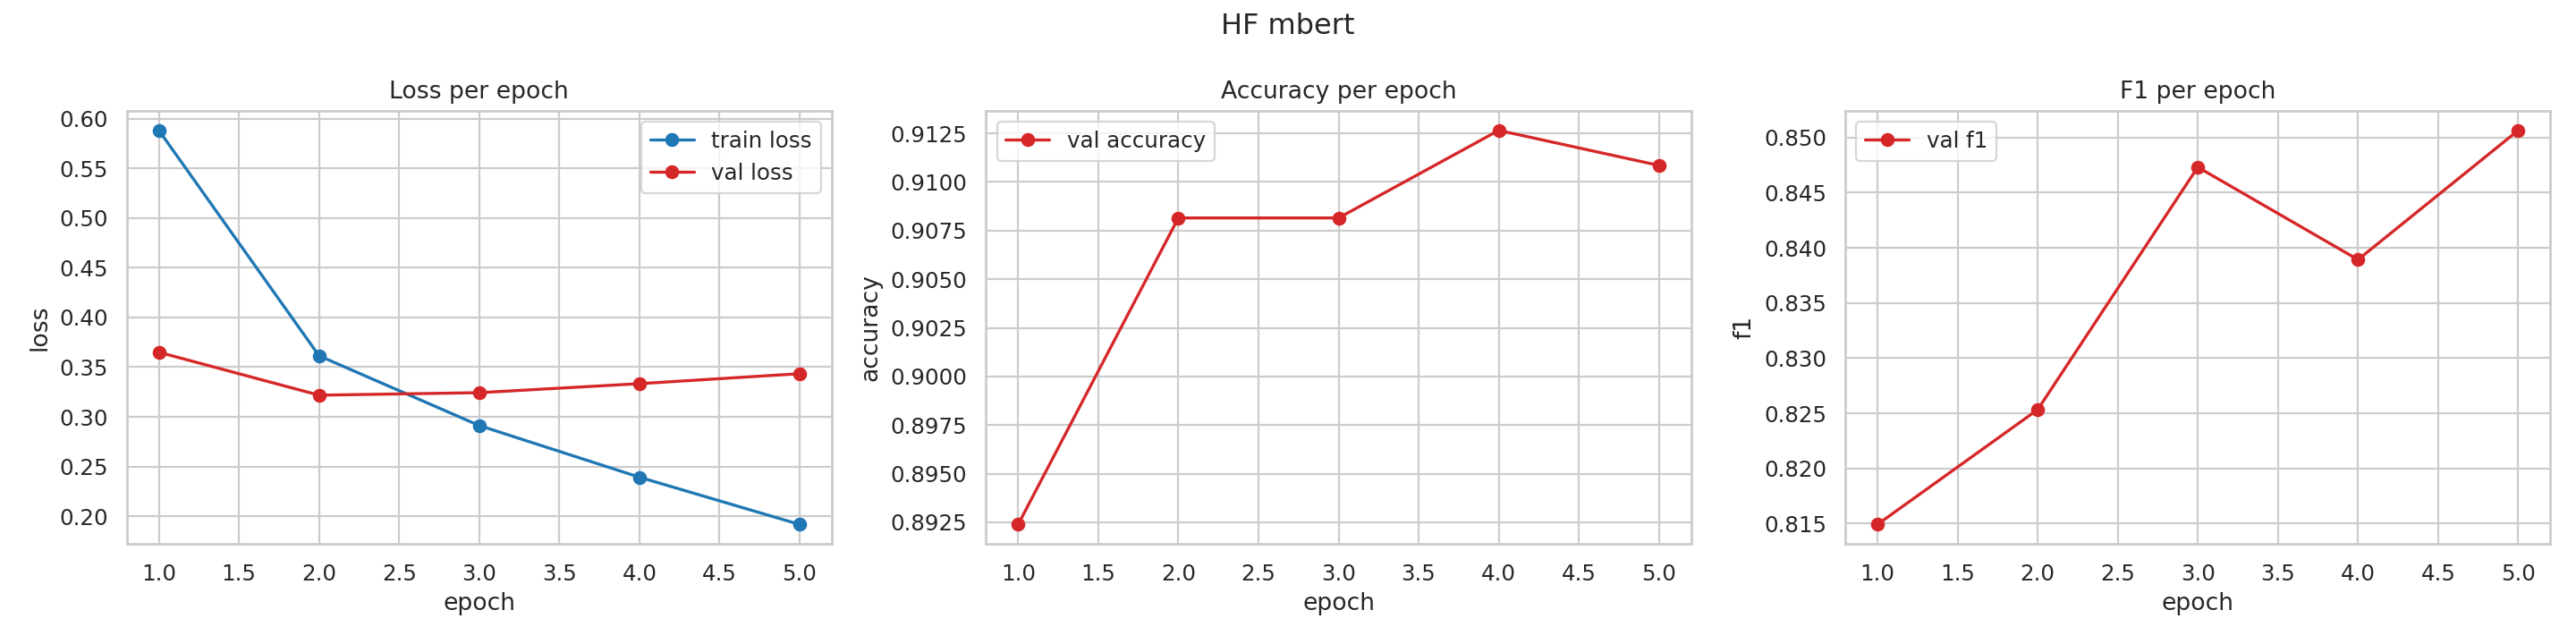

**rnn_bilstm_emb-none.history.png**

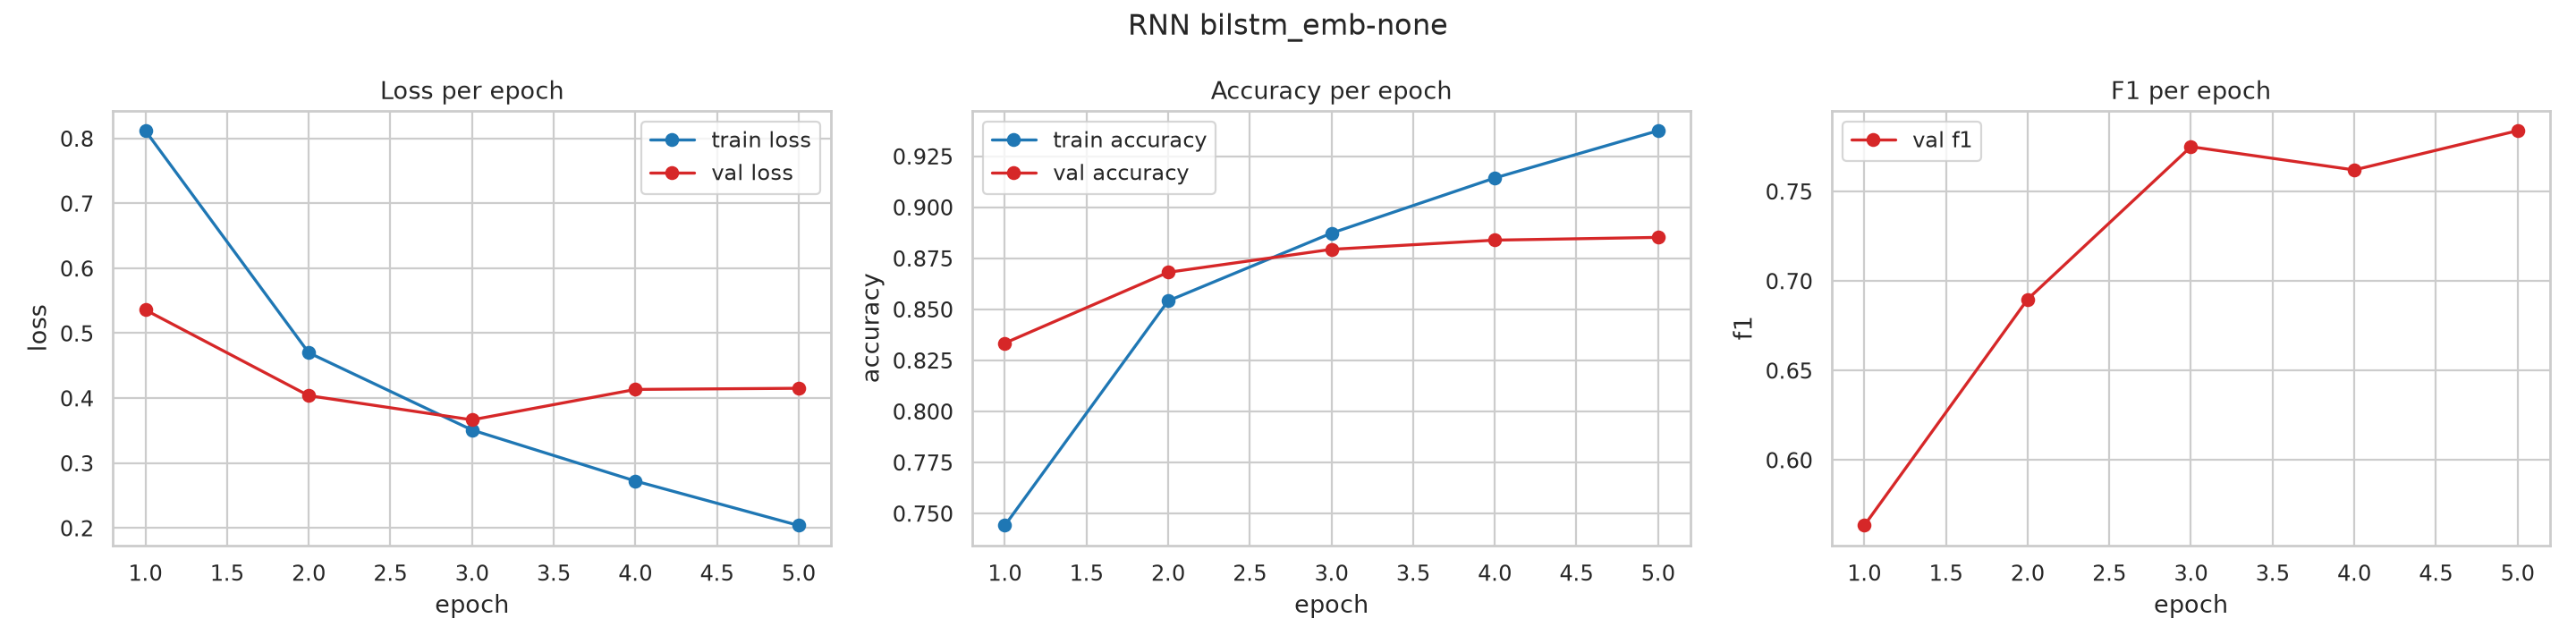

**rnn_gru_emb-fasttext.history.png**

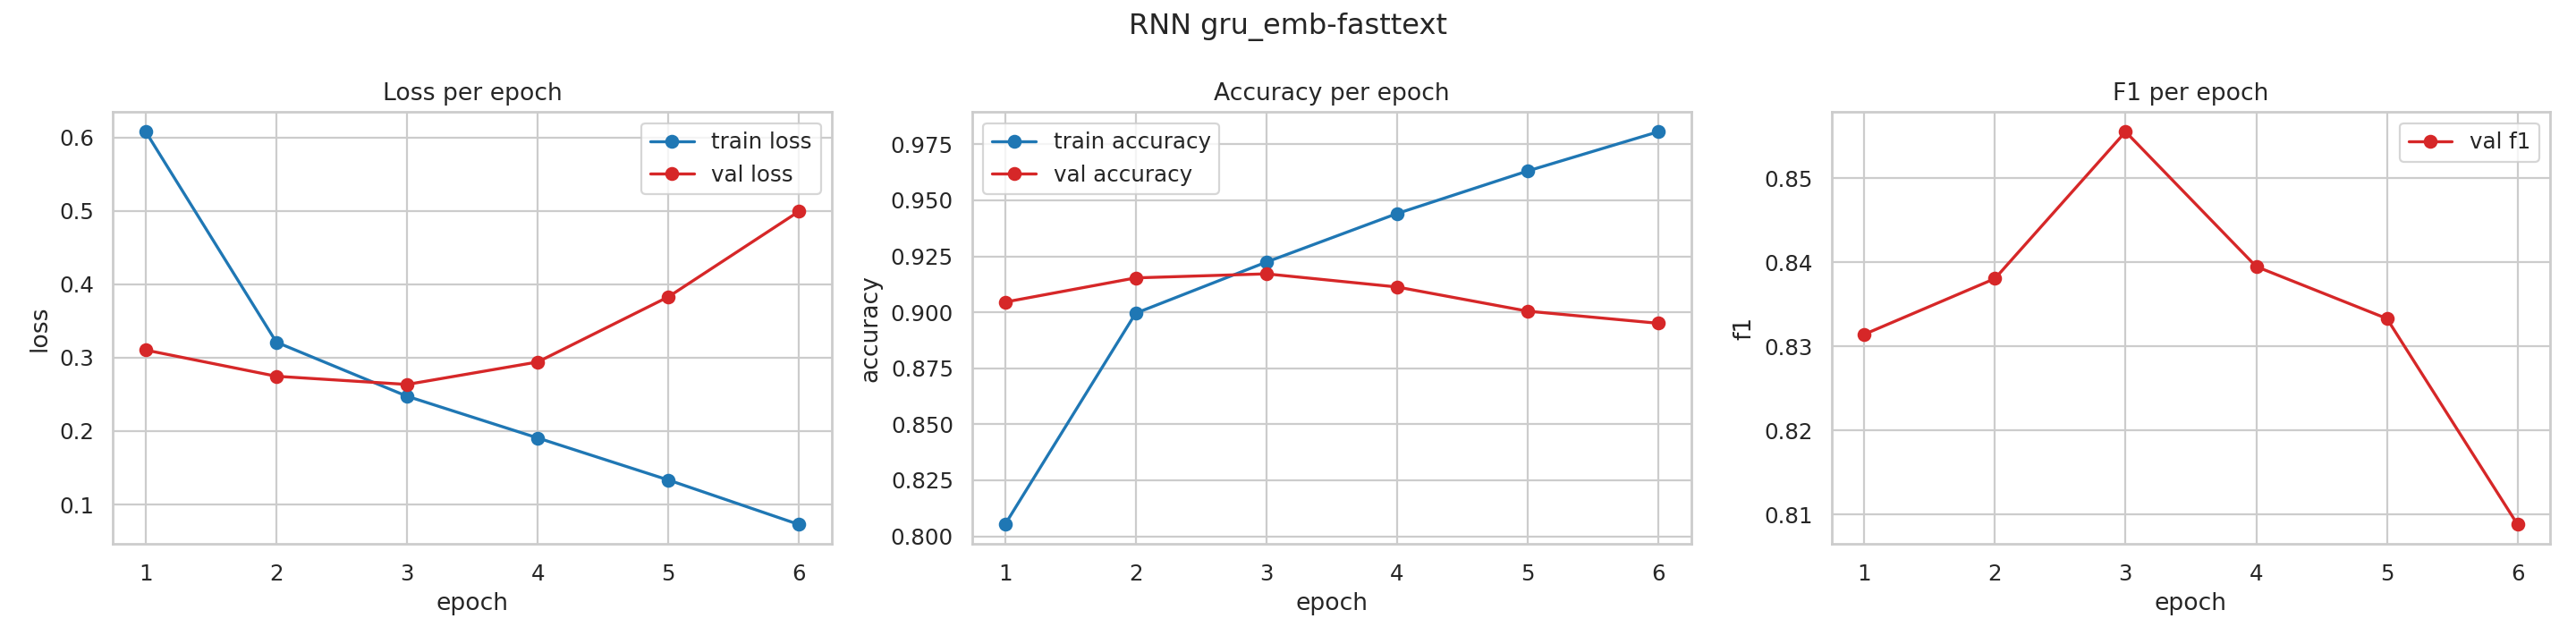

**hf_afriberta.confusion_matrix.png**

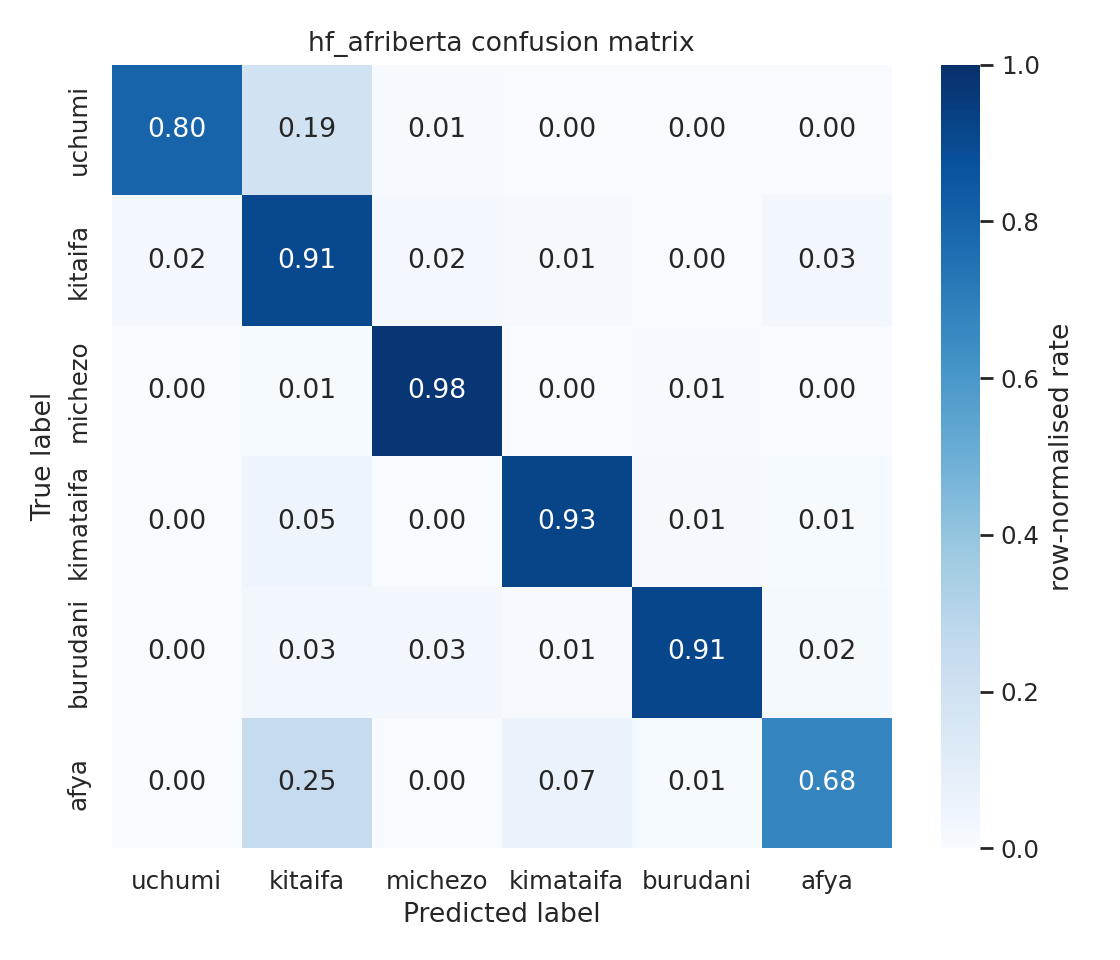

**hf_mbert.confusion_matrix.png**

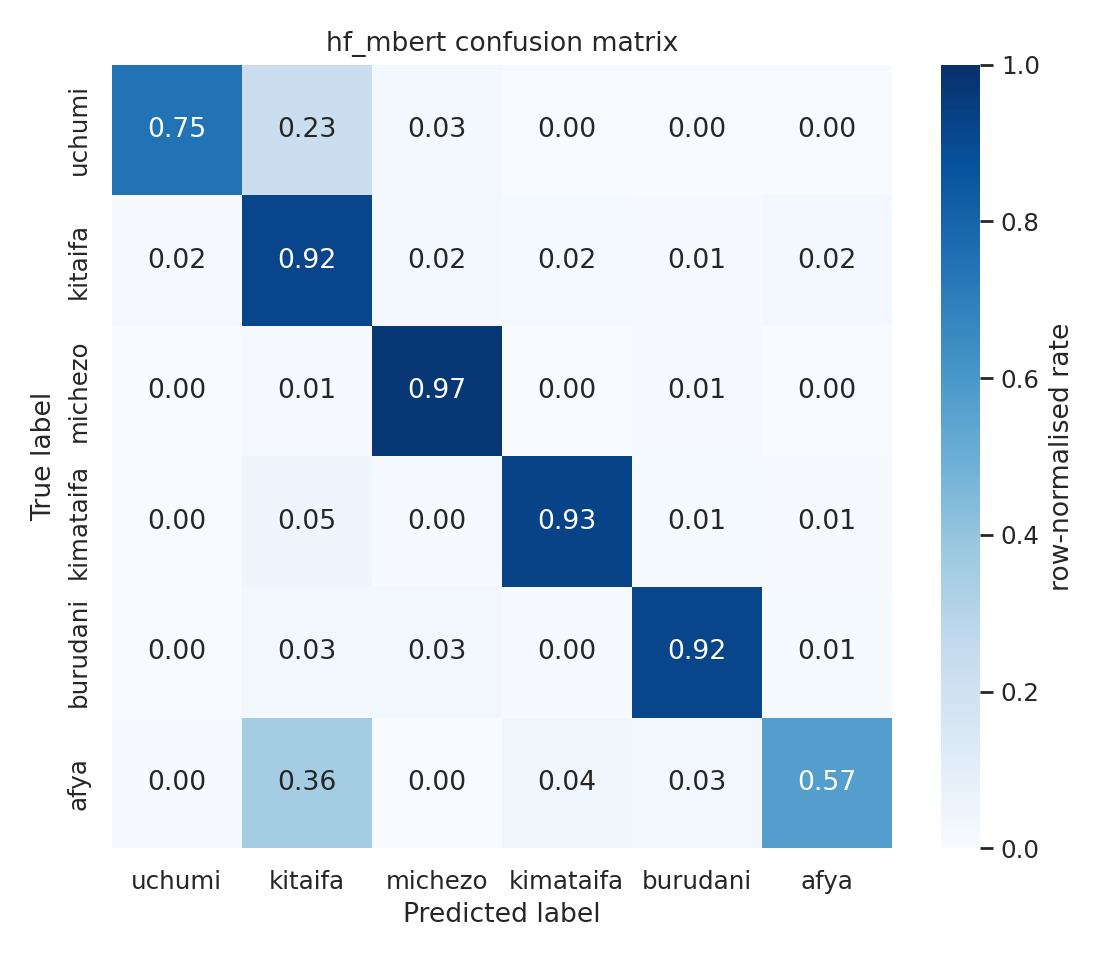

**rnn_bilstm_emb-none.confusion_matrix.png**

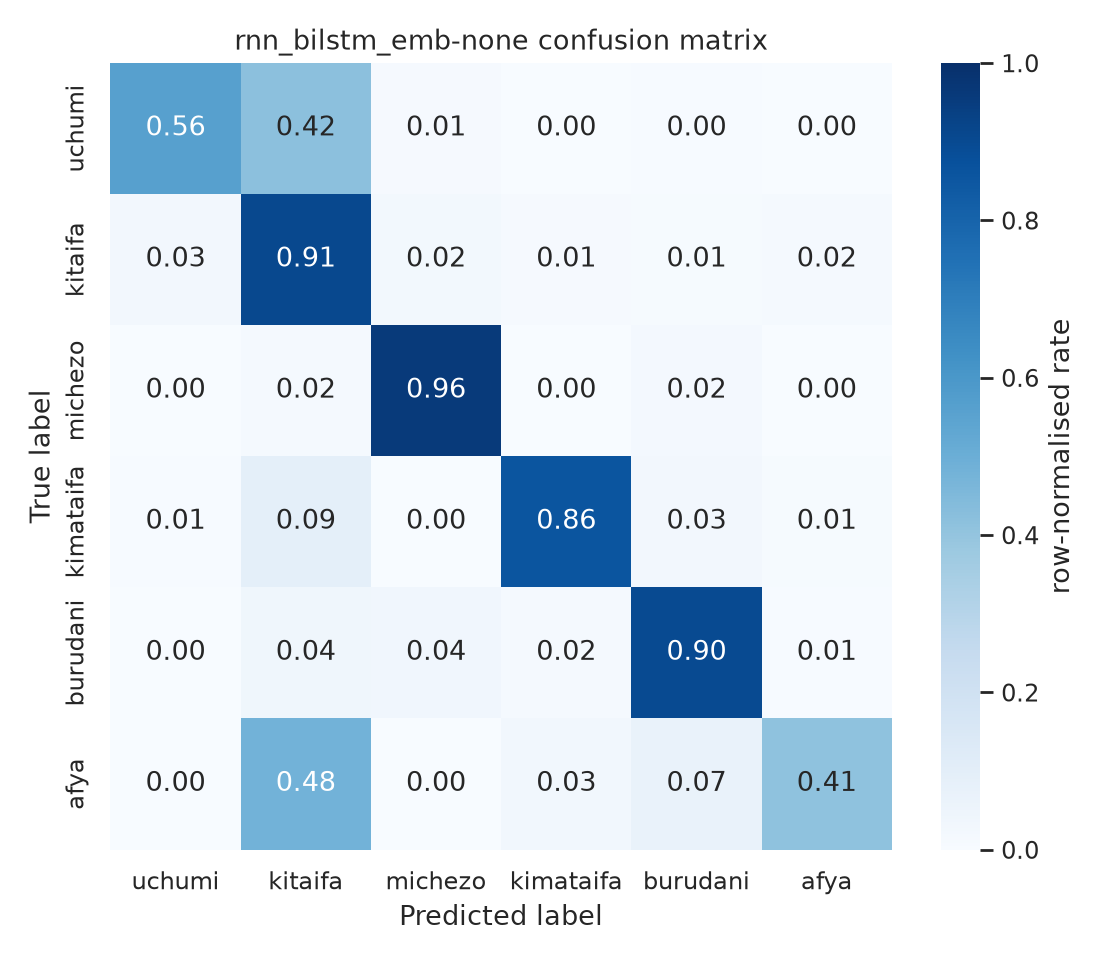

**rnn_bilstm_emb-word2vec.confusion_matrix.png**

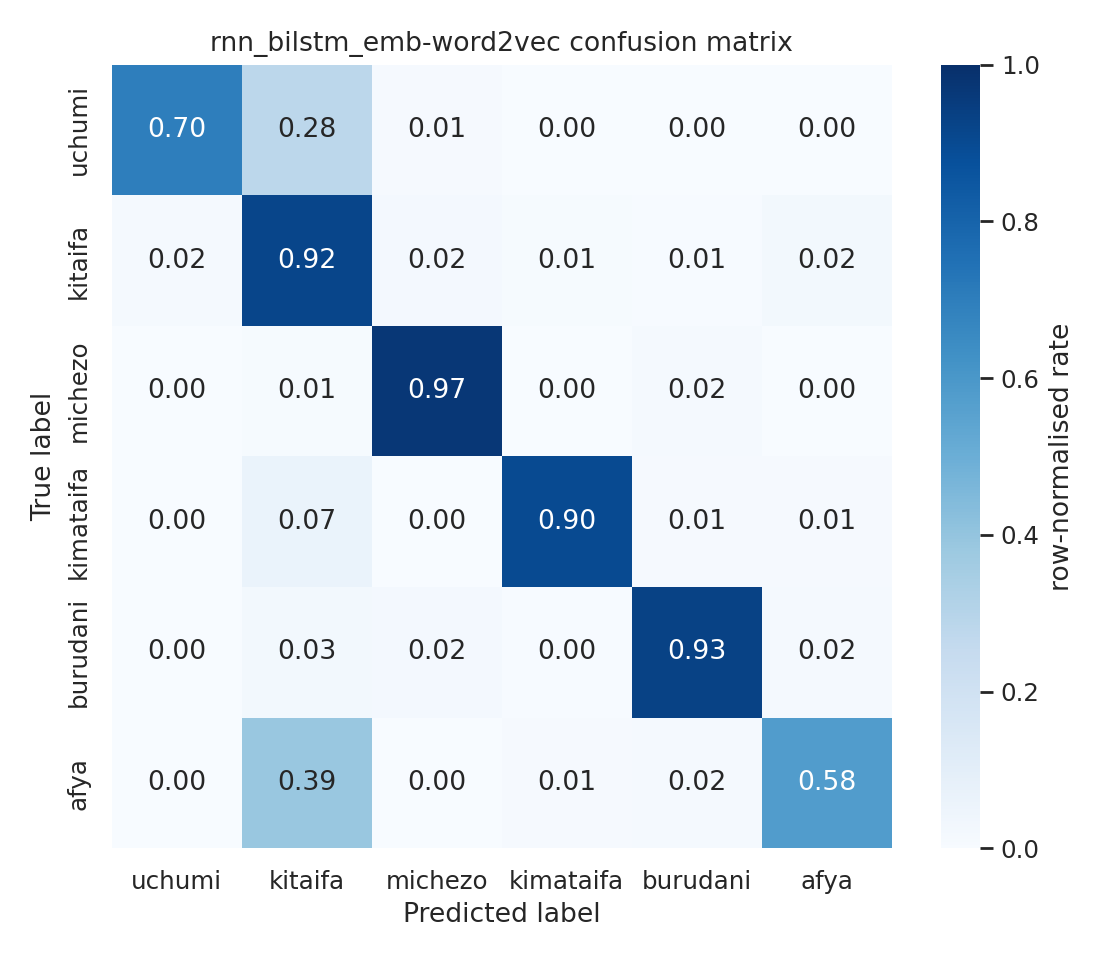

**rnn_gru_emb-fasttext.confusion_matrix.png**

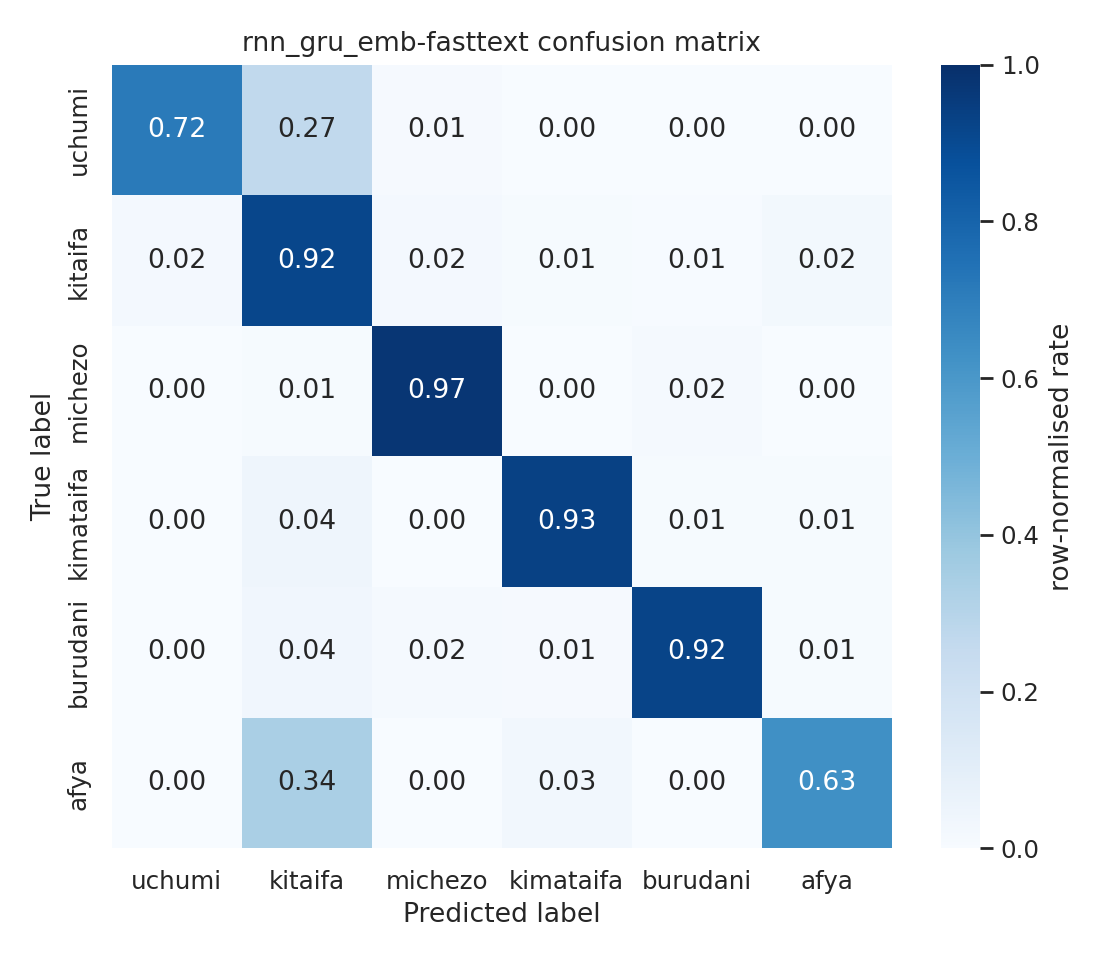

In [46]:
for p in sorted(FIG_DIR.glob("tsne_*.png")):
    display(Markdown(f"**{p.name}**"))
    display(Image(filename=str(p)))

for p in sorted(METRIC_DIR.glob("*.history.png")):
    display(Markdown(f"**{p.name}**"))
    display(Image(filename=str(p)))

for p in sorted(METRIC_DIR.glob("*.confusion_matrix.png")):
    display(Markdown(f"**{p.name}**"))
    display(Image(filename=str(p)))

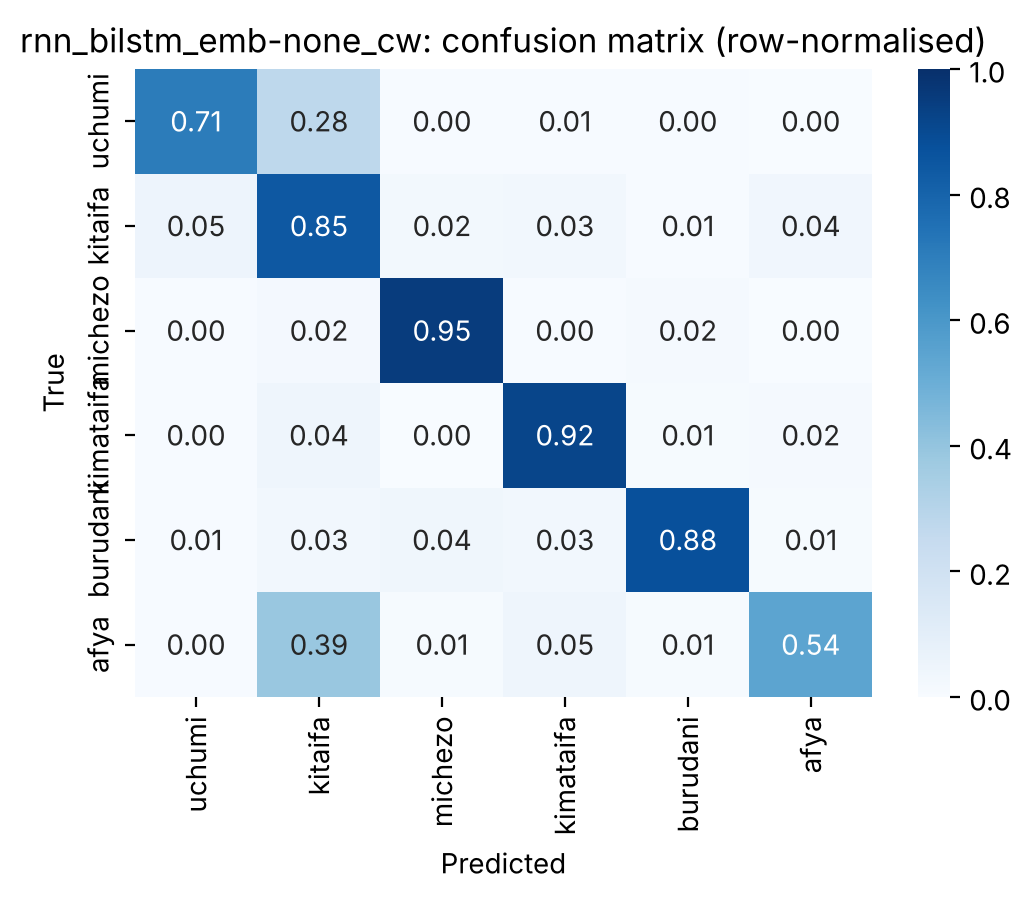

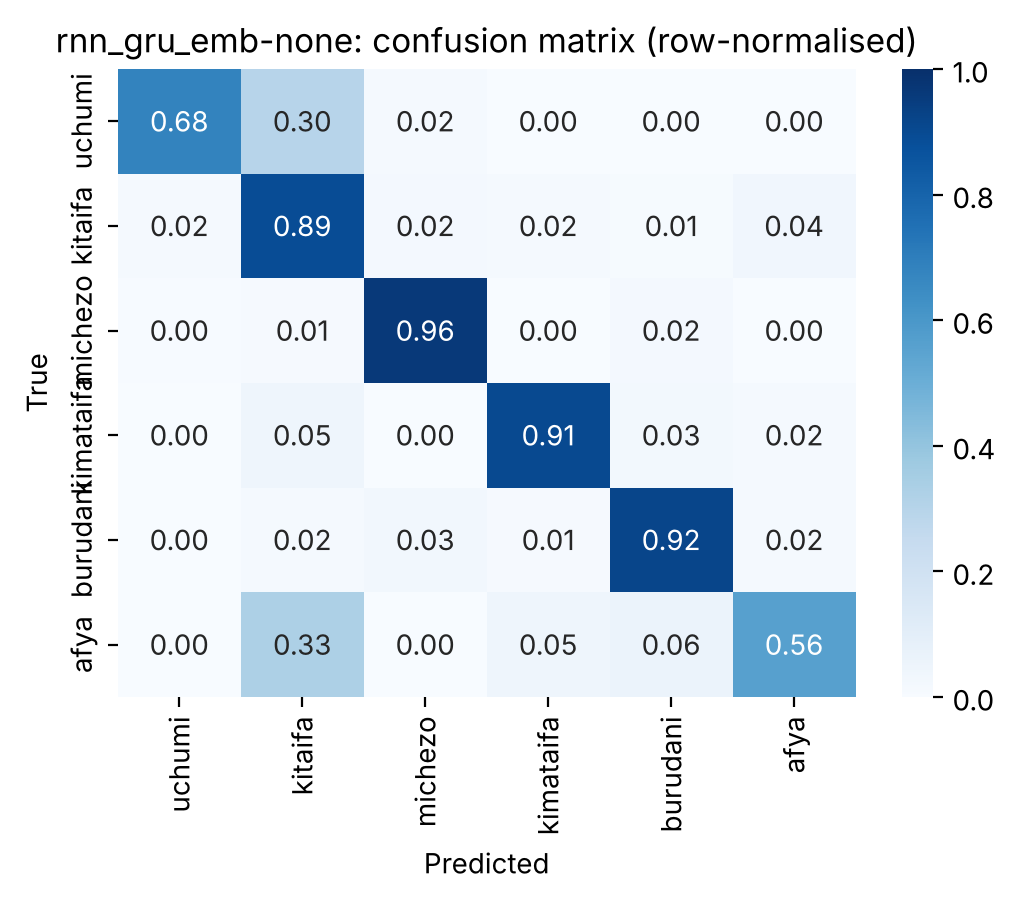

In [47]:
# Confusion matrices for the models that have no saved plot (drawn from their saved matrices).
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

have_png = {p.name.split(".")[0] for p in METRIC_DIR.glob("*.confusion_matrix.png")}
for csvp in sorted(METRIC_DIR.glob("*.confusion_matrix.csv")):
    name = csvp.name.split(".confusion_matrix")[0]
    if name in have_png:
        continue
    cm = pd.read_csv(csvp, index_col=0)
    fig, ax = plt.subplots(figsize=(5.4, 4.6))
    sns.heatmap(cm.div(cm.sum(axis=1), axis=0), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
    ax.set_title(f"{name}: confusion matrix (row-normalised)")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    fig.tight_layout()
    fig.savefig(METRIC_DIR / f"{name}.confusion_matrix.png", dpi=150)
    plt.show()

In [48]:
# Misclassification analysis: where the errors go, and how sure the models were.
rows = []
for name, d in _model_jsons():
    for c in d.get("confusions", [])[:3]:
        rows.append({"model": name, "true → predicted": f'{c["true"]} → {c["predicted"]}',
                     "errors": c["count"], "share of the true class": c["share_of_true_class"]})
display(Markdown("**Table: the three most common confusions for each model**"))
display(pd.DataFrame(rows).style.format({"share of the true class": "{:.1%}"}).hide(axis="index"))

rows = []
for p in sorted(METRIC_DIR.glob("*.misclassified.csv")):
    df = pd.read_csv(p)
    if "confidence" in df:
        sure = df["confidence"] >= 0.9
        rows.append({"model": p.name.split(".misclassified")[0], "wrong predictions": len(df),
                     "made with ≥ 90% confidence": int(sure.sum()), "share": float(sure.mean())})
display(Markdown("**Table: how many wrong predictions were made with at least 90% confidence**"))
display(pd.DataFrame(rows).sort_values("wrong predictions").style.format({"share": "{:.1%}"}).hide(axis="index"))

**Table: the three most common confusions for each model**

model,true → predicted,errors,share of the true class
hf_afriberta,kitaifa → afya,106,3.2%
hf_afriberta,uchumi → kitaifa,91,19.5%
hf_afriberta,kitaifa → michezo,79,2.4%
hf_mbert,uchumi → kitaifa,107,22.9%
hf_mbert,afya → kitaifa,78,35.6%
hf_mbert,kitaifa → michezo,72,2.2%
rnn_bilstm_emb-none,uchumi → kitaifa,179,38.3%
rnn_bilstm_emb-none,afya → kitaifa,130,59.4%
rnn_bilstm_emb-none,kitaifa → uchumi,97,2.9%
rnn_bilstm_emb-none_cw,kitaifa → uchumi,175,5.2%


**Table: how many wrong predictions were made with at least 90% confidence**

model,wrong predictions,made with ≥ 90% confidence,share
rnn_gru_emb-fasttext,637,217,34.1%
hf_mbert,642,382,59.5%
rnn_bilstm_emb-word2vec,666,178,26.7%
rnn_gru_emb-none,791,230,29.1%
rnn_bilstm_emb-none,875,383,43.8%
rnn_bilstm_emb-none_cw,982,561,57.1%


**What the error tables show**

- The most common mistakes all involve *kitaifa* (national): economy and health articles predicted as
  national, and national articles predicted as health, economy or sports.
- Sports (*michezo*) is the easiest topic; health and economy have the lowest F1 for every model.
- Likely causes (our interpretation, not separately tested): national, economy and health stories share
  vocabulary, the two smallest topics have the fewest training examples, and 128 tokens cut off most of
  each article.
- A sizeable share of the wrong predictions were made with at least 90% confidence (see the table),
  so confidence alone cannot be used to flag a model's own mistakes.

In [49]:
for p in sorted(METRIC_DIR.glob("*.classification_report.txt")):
    display(Markdown(f"**{p.name}**"))
    print(p.read_text())

for p in sorted(METRIC_DIR.glob("*.misclassified.csv")):
    df = pd.read_csv(p)
    display(Markdown(f"**{p.name} — {len(df)} errors (10 shown)**"))
    display(df.head(10))

**hf_afriberta.classification_report.txt**

              precision    recall  f1-score   support

      uchumi     0.8382    0.7987    0.8180       467
     kitaifa     0.9334    0.9080    0.9205      3348
     michezo     0.9482    0.9805    0.9640      1996
   kimataifa     0.9018    0.9256    0.9135       605
    burudani     0.9456    0.9147    0.9299       703
        afya     0.5461    0.6758    0.6041       219

    accuracy                         0.9159      7338
   macro avg     0.8522    0.8672    0.8583      7338
weighted avg     0.9183    0.9159    0.9167      7338



**hf_mbert.classification_report.txt**

              precision    recall  f1-score   support

      uchumi     0.8509    0.7452    0.7945       467
     kitaifa     0.9210    0.9194    0.9202      3348
     michezo     0.9472    0.9699    0.9584      1996
   kimataifa     0.8836    0.9289    0.9057       605
    burudani     0.9203    0.9203    0.9203       703
        afya     0.6127    0.5708    0.5910       219

    accuracy                         0.9125      7338
   macro avg     0.8560    0.8424    0.8484      7338
weighted avg     0.9113    0.9125    0.9116      7338



**rnn_bilstm_emb-none.classification_report.txt**

              precision    recall  f1-score   support

      uchumi     0.7287    0.6039    0.6604       467
     kitaifa     0.8683    0.9200    0.8934      3348
     michezo     0.9479    0.9569    0.9524      1996
   kimataifa     0.8986    0.8347    0.8655       605
    burudani     0.8858    0.8720    0.8789       703
        afya     0.5407    0.3333    0.4124       219

    accuracy                         0.8808      7338
   macro avg     0.8117    0.7535    0.7772      7338
weighted avg     0.8755    0.8808    0.8766      7338



... (8 outputs left out)

**rnn_gru_emb-fasttext.misclassified.csv — 637 errors (10 shown)**

,text,true_label,predicted_label,confidence,pred_true_prob
0,"GHASIA za ubaguzi zimeibuka tena nchini Afrika Kusini, katika maeneo tofauti ya Mji wa Soweto ambapo watu wawili waliuwawa katika mapigano yaliyotokea kati ya wenyeji na wageni katika mji huo. Kwa mujibu wa taarifa ya Polisi, shughuli katika maeneo hayo mengi zilizorota huku maduka yanayomilikiwa na wageni yakiporwa bidhaa kutokana na vurugu hizo.Maduka mengi yanayomilikiwa na wageni yamejengwa katika maeneo ya karibu na makazi na mengi yanamilikiwa na raia kutoka nchi za Ethiopia, Zimbabwe na Pakistan. Hali hiyo pia imewafanya wamiliki wengi wa maduka kufunga na kuondoka mjini humo wakihofia",kitaifa,kimataifa,0.864307,0.864307
1,"Wakurugenzi hao wametakiwa kufanya hivyo ili mipango ya miradi hiyo katika maeneo husika ya makubaliano na China ianze kutekelezwa.Kauli hiyo imetolewa na Waziri wa Nchi, Ofisi ya Waziri Mkuu (Tamisemi) Hawa Ghasia wakati akizungumza na waandishi wa habari juu ya ujio wa wageni kutoka China.Ghasia alisema kuwa miongoni mwa wageni watakaokuja ni pamoja na Magavana, Meya na wafanyabiashara kutoka nchini humo, ambapo imeelezwa lengo la ujio huo ni kuanzisha ushirikiano rasmi kati ya Serikali ya Tanzania na China kupitia Shirikisho la Ushirikiano wa Serikali za Mitaa za Afrika na China.“Kupitia u",uchumi,kitaifa,0.804331,0.804331
2,"Ma CHRISTIAN BWAYA\n MIGOGORO katika mahusiano ya ndoa ni jambo lisiloepukika. Hakujawahi kutokea watu wawili wenye vichwa tofauti wakaafikiana kwa kila jambo. Kutofautiana kupo lakini tunafahamu kuwa hatua madhubuti zisipochukuliwa mapema kuondoa tofauti hizi ndoa in- aweza kukumbwa na tufani. Inapofikia hatua hiyo wanandoa wanaweza kujikuta wakilazimika kuwahusisha watu wengine katika matatizo yao kwa sababu kadhaa. Mosi, ni kuwasaidia kutatua mgogoro uliopo. Mmojawapo anapoomba msaada wa ndugu na jamaa wengine kwa mfano, analenga kupata msaada wa mawazo yatakayochangia kutatua changamoto",kitaifa,afya,0.881354,0.881354
3,"SHIRIKA la Mawasiliano Tanzania (TTCL) kupitia Kampuni tanzu ya Fedha Mtandao (T-Pesa), wameanzisha mfumo wa kulipa kwa kutumia kadi kuongeza mapato na kuchochea uchumi.Kadi hiyo itatumiwa na wateja wanaotumia huduma hiyo ya T-Pesa kufanya malipo ya safari ikiwemo kwenye mabasi yaendayo haraka na kulipia bidhaa kupitia mashine za kielekroniki (EFDs).Akizungumza katika hafla ya utiaji saini jijini Dar es Salaam, Mkurugenzi wa T-Pesa, Moses Alphonce amesema mradi wa kutengeneza mfumo wa malipo kwa kutumia kadi unahusisha Kampuni za PayLink, KEH Hana Card na Atect and Company zote kutoka nchini",uchumi,kitaifa,0.579338,0.579338
4,"Korosho ni zao kuu la biashara mkoani Pwani, Mkuu wa Mkoa huo Mhandisi Evarist Ndikilo amesema leo jijini Dar es Salaam.Amesema katika msimu wa kilimo mwaka 2018/2019 mkoa huo ulikusanya tani 22,168 za korosho, na kwamba, zao hilo limekuwa likipandwa mwaka hadi mwaka na uzalishaji umekuwa ukiongezeka.Ndikilo amesema kwenye ofisi kuu za Benki ya Maendeleo ya Kilimo Tanzania (TADB) Kinondoni kuwa, korosho zilizokusanywa zimewaingizia wananchi zaidi ya shilingi bilioni 60/-.“Kwa hiyo nichukue fursa hii kwanza kuipongeza sana TADB…kwa hiyo benki ya TADB baada ya kupewa jukumu hili na Serikali ime",uchumi,kitaifa,0.578831,0.578831
5,"Mwandishi Wetu- Morogoro MKUU wa Mkoa wa Morogoro, Loatha Sanare amegeuka mbogo baada ya kupata taarifa za kuachiwa watu wanaodaiwa kukamatwa na dawa za Serikali kinyume cha sheria kuachiwa. Kutokana na hali hiyo, aliagizwa kukamatwa mara moja na kurudishwa mahabusi. Sanare aliamua kufanya ziara ya kukagua kituo cha afya na kujiridhisha na taratibu za kupokea dawa. Katika ziara hiyo,Sanare aliambatana na Mkuu wa Wilaya ya Morogoro,Chonjo, Katibu Tawala wa Mkoa, Mhandisi Emanuel Kolobelo, Mkurugenzi wa Halmashauri ya Morogoro, Rehema Bwasi na Mganga Mkuu wa Wilaya, Dk. Robert Manyerere. Baada",afya,kitaifa,0.825400,0.825400
6,"Na ZAINAB IDD-DAR ES SALAAM KATIKA kuhakikisha Tanzania inakuwa na maendeleo katika mchezo wa riadha wa mbio ndefu, Rais 

**rnn_gru_emb-none.misclassified.csv — 791 errors (10 shown)**

,text,true_label,predicted_label,confidence,pred_true_prob
0,"GHASIA za ubaguzi zimeibuka tena nchini Afrika Kusini, katika maeneo tofauti ya Mji wa Soweto ambapo watu wawili waliuwawa katika mapigano yaliyotokea kati ya wenyeji na wageni katika mji huo. Kwa mujibu wa taarifa ya Polisi, shughuli katika maeneo hayo mengi zilizorota huku maduka yanayomilikiwa na wageni yakiporwa bidhaa kutokana na vurugu hizo.Maduka mengi yanayomilikiwa na wageni yamejengwa katika maeneo ya karibu na makazi na mengi yanamilikiwa na raia kutoka nchi za Ethiopia, Zimbabwe na Pakistan. Hali hiyo pia imewafanya wamiliki wengi wa maduka kufunga na kuondoka mjini humo wakihofia",kitaifa,kimataifa,0.978991,0.978991
1,"Ma CHRISTIAN BWAYA\n MIGOGORO katika mahusiano ya ndoa ni jambo lisiloepukika. Hakujawahi kutokea watu wawili wenye vichwa tofauti wakaafikiana kwa kila jambo. Kutofautiana kupo lakini tunafahamu kuwa hatua madhubuti zisipochukuliwa mapema kuondoa tofauti hizi ndoa in- aweza kukumbwa na tufani. Inapofikia hatua hiyo wanandoa wanaweza kujikuta wakilazimika kuwahusisha watu wengine katika matatizo yao kwa sababu kadhaa. Mosi, ni kuwasaidia kutatua mgogoro uliopo. Mmojawapo anapoomba msaada wa ndugu na jamaa wengine kwa mfano, analenga kupata msaada wa mawazo yatakayochangia kutatua changamoto",kitaifa,afya,0.602357,0.602357
2,"PERTH, AUSTRALIA WAKATI baadhi ya\nhoteli katika majiji yaliyopo pwani kama vile Dar es Salaam yakikabiliwa na\nkero kutoka kwa kunguru wasumbufu, hoteli moja nchini Australia imevumbua njia\nya kuzuia ndege wasumbufu kusumbua wageni wake. Kwa mujibu wa\nmashirika ya habari, hoteli iliyo katika mji wa Perth, huwapa wageni wake\nbunduki bandia za kurushia ndege wa baharini maji ili kuwafukuza wanapokula\nufukweni. Mmiliki wa hoteli\nhiyo ya 3Sheets, Toby Evans, anasema ndege hao wa baharini wanaoitwa ‘seagulls’\nhusumbua wageni hivyo akaamua kutafuta njia ya kuwafukuza. Awali ndege hao\nwalikuwa wakisub",kimataifa,kitaifa,0.633670,0.633670
3,"SHIRIKA la Mawasiliano Tanzania (TTCL) kupitia Kampuni tanzu ya Fedha Mtandao (T-Pesa), wameanzisha mfumo wa kulipa kwa kutumia kadi kuongeza mapato na kuchochea uchumi.Kadi hiyo itatumiwa na wateja wanaotumia huduma hiyo ya T-Pesa kufanya malipo ya safari ikiwemo kwenye mabasi yaendayo haraka na kulipia bidhaa kupitia mashine za kielekroniki (EFDs).Akizungumza katika hafla ya utiaji saini jijini Dar es Salaam, Mkurugenzi wa T-Pesa, Moses Alphonce amesema mradi wa kutengeneza mfumo wa malipo kwa kutumia kadi unahusisha Kampuni za PayLink, KEH Hana Card na Atect and Company zote kutoka nchini",uchumi,kitaifa,0.543957,0.543957
4,"Na JUDITH NYANGE MKOA wa Mwanza kwa kushirikiana na wadau mbalimbali wa afya umefanikiwa kupunguza kwa asilimia nne vifo vinavyotokana na malaria kutoka asilimia 19.1 katika miaka mine. Vifo hivyo vimefikia asilimia 15 mwaka 2015/16 kutoka asilimia 19 za mwaka 2011/12. Mganga Mkuu wa Mkoa waMwanza, Dk. Leornard Subi, alikuwa akizungumza wakati wa kugawa vyandarua kwa wanafunzi wa Shule ya Msingi Senge, Kata ya Bujashi wilayani Magu ikishuhudiwa na wajumbe wa Bunge la Marekani. Dk. Subi alisema mwaka 2011/12 kiwango cha maambukizi ya malaria mkoani Mwanza kilikuwa asilimia 19.1 la",afya,kitaifa,0.753129,0.753129
5,"Na VERONICA ROMWALD – DAR ES SALAAM HATUA ya Rais Dk. John Magufuli kukemea hadharani wasanii wanaocheza utupu\nmajukwaani na wanaporekodi video za muziki ni ya kupongezwa.\nNi suala linalopaswa kuungwa mkono na kila mwananchi anayependa\nmaendeleo ya jamii na nchi kwa ujumla.\nAkihutubia katika mkutano wa Jumuiya ya Wazazi wa Chama Cha Mapinduzi\njuzi mjini Dodoma, Rais Magufuli alisema kila anapowasha televisheni\nyake anashangaa kukutana na mabinti wakicheza utupu.\nAlisema wakati mabinti wakicheza utupu, wanaume huwa wamevaa mavazi ya\nstaha na kusisitiza kwamba ni aibu kubwa kwa wazazi kuangalia",kitaifa,burudani,0.557010,0.557010
6,"Korosho ni zao kuu la biashara mkoani Pwani, Mkuu wa Mkoa huo Mhandisi Evarist Ndikilo amesema leo jijini Dar 

In [50]:
for rp in [RESULTS_DIR / "report" / "report.md", RESULTS_DIR / "report.md"]:
    if rp.exists():
        display(Markdown(rp.read_text()[:12000]))
        print("\n[report truncated for display; open report/report.md for the full text]")
        break

# Swahili Text Classification: News Topics and Social-Media Sentiment

**Group 1 — Text Classification (Swahili News / Social Media)**  
Course: Deep Learning and AI  
Date: <fill in>  
Members: <fill in>

---

## Abstract

This project studies text classification for Swahili, a morphologically rich,
lower-resource language. We compare two recurrent neural architectures (BiLSTM
and GRU) with two pretrained transformer models (mBERT and AfriBERTa) on the
six-class Swahili News dataset, and optionally on a three-class Swahili Twitter
sentiment dataset. We build a reproducible pipeline covering exploratory data
analysis, cleaning, tokenisation, optional Swahili stopword removal, a
conservative rule-based stemmer, vocabulary construction, and padding. The
recurrent models are trained with randomly initialised, Word2Vec and FastText
embeddings, while the transformers are fine-tuned with the Hugging Face Trainer.
All models are evaluated with accuracy, macro/weighted precision, recall and F1,
confusion matrices and a manual analysis of misclassified examples. We further
compare tokenisation strategies and visualise word, document and `[CLS]`
embeddings with PCA and t-SNE. The best model is the African-focused
**AfriBERTa** (accuracy 0.9159, macro-F1 0.8583), followed closely by
**GRU + FastText** (0.9132, 0.8509) and **mBERT** (0.9125, 0.8484).
Corpus-trained embeddings raise the recurrent baselines by 0.04–0.06 macro-F1,
and the best RNN nearly matches mBERT on this 20k-article dataset. Remaining
errors concentrate on semantically overlapping topics such as national versus
economy/health news. We discuss the limitations of the rule-based stemmer, the
small dataset size and the 128-token truncation.

---

## 1. Introduction

Swahili (`Kiswahili`) is spoken by more than 200 million people, yet it remains
under-represented in NLP benchmarks and pretrained resources compared with
English. Text classification is a foundational task: assigning a topic to a news
article or a sentiment to a tweet. Strong Swahili classifiers are useful for media
monitoring, content recommendation, moderation and public-opinion analysis.

The assignment asks for a comparative study rather than a single model. We
therefore ask three questions:

1. How much does a corpus-trained embedding (Word2Vec/FastText) help a recurrent
   classifier compared with random embeddings?
2. How do BiLSTM and GRU compare at similar capacity?
3. Do multilingual/African pretrained transformers outperform recurrent models on
   this amount of Swahili data?

We answer these questions with a fully reproducible pipeline and an explicit
error analysis.

---

## 2. Data

### 2.1 Swahili News (primary)

- Source: `community-datasets/swahili_news` (Hugging Face).
- Task: six-class topic classification.
- Splits: 22,207 training articles, 7,338 official test articles.
- We carve a stratified 10% validation set out of the training split, leaving
  19,986 training and 2,221 validation articles.
- Labels: `uchumi` (economy), `kitaifa` (national), `michezo` (sports),
  `kimataifa` (international), `burudani` (entertainment), `afya` (health).

### 2.2 Swahili Twitter sentiment (secondary)

- Source: `Davis/Swahili-tweet-sentiment` (Hugging Face).
- Task: three-class sentiment.
- Size: 2,263 tweets in a single split; we create a stratified split with 1,832
  training, 204 validation and 227 test tweets.
- Raw labels `-1`, `0`, `1` are mapped to negative, neutral and positive. The
  raw file does not include an explicit label dictionary, so this mapping is an
  assumption (discussed in Section 6).
- The training distribution is neutral 1,085, positive 553 and negative 194, an
  imbalance ratio of 5.6:1. Tweets are short (mean 16.8 tokens, median 16), so
  no truncation occurs at `MAX_LEN=128`; this makes the sentiment task very
  different from the long-article news task.

### 2.3 Exploratory data analysis

The dataset contains 22,207 training articles and 7,338 test articles. After
carving out a stratified 10% validation set, we have 19,985 training, 2,221
validation and 7,338 test documents.

| Split | Rows | Mean chars | Mean tokens | Median tokens | 95th pct tokens |
|---|---:|---:|---:|---:|---:|
| Train | 19,985 | 2,202 | 335.3 | 275 | 804 |
| Validation | 2,221 | 2,234 | 339.9 | 269 | 823 |
| Test | 7,338 | 2,169 | 330.5 | 272 | 777 |

The class distribution is strongly imbalanced:

| Label | Train count | Train share |
|---|---:|---:|
| `kitaifa` (national) | 9,139 | 45.7% |
| `michezo` (sports) | 5,373 | 26.9% |
| `burudani` (entertainment) | 1,967 | 9.8% |
| `kimataifa` (international) | 1,672 | 8.4% |
| `uchumi` (economy) | 1,133 | 5.7% |
| `afya` (health) | 701 | 3.5% |

The largest class is 13.0 times bigger than the smallest. This makes accuracy a
misleading headline metric: a majority-class classifier would already score about
46%. We therefore report **macro-F1** as the primary metric and inspect per-class
recall.

Text length is the second important finding. The mean article is about 335
tokens (median 275, 95th percentile 804), while the models use
`MAX_LEN = 128`. Consequently **90.4% of training articles are truncated**.
This is a deliberate speed/memory trade-off: news leads usually state the topic
in the first paragraph, but the truncation is a limitation and should be
discussed when interpreting results. A transformer experiment with
`MAX_LEN = 256` is a natural follow-up if GPU memory allows.

The EDA produces:

- `label_distribution_swahili_news.png` — class counts per split and class share;
- `text_length_distribution_swahili_news.png` — character/token length histograms and boxplots;
- `wordcloud_overall_swahili_news.png` and `wordcloud_per_class_swahili_news.png`;
- `top_words_per_class_swahili_news.png` — top-20 content words per class.

Word clouds are a qualitative sanity check. They confirm that cleaning preserves
topic vocabulary (e.g. sports terms such as `mpira`, `mechi`, `goli`) and that
stopword removal makes the clouds informative rather than dominated by `na`, `ya`
and `kwa`.

---

## 3. Methodology

### 3.1 Cleaning and tokenisation

Raw text is HTML-unescaped; URLs, e-mails, HTML tags and `@mentions` are removed;
hashtags keep their word (`#Michezo` → `michezo`); text is lowercased; characters
other than letters, digits, apostrophes and whitespace are replaced by spaces; and
whitespace is collapsed. Tokenisation uses a Unicode-aware word regex.

We deliberately keep the same cleaning for every model so that comparisons are
fair.

### 3.2 Swahili stopwords and stemming

Stopword removal is optional. The curated list contains high-frequency function
words (`na`, `ya`, `kwa`, `ni`, `za`, `la`, `katika`, …). Because Swahili encodes
tense, subject and negation in prefixes, removing stopwords can remove
grammatical information; we therefore compare with and without removal.

There is no widely used Swahili lemmatiser in the standard Python stack, so we
implement a conservative rule-based stemmer:

- words shorter than seven characters are not touched;
- at most two prefixes and one suffix (`ni`, `eni`, `ini`) are removed;
- an affix is removed only if the remaining stem has at least five characters.

Examples: `wanasoma` → `soma`, `wanasiasa` → `siasa`; `habari` and `kuhusu`
remain unchanged. This is a heuristic, not a morphological analyser, and is
evaluated empirically against unstemmed text.

### 3.3 Vocabulary and padding

The vocabulary is built **only from training tokens**, with
`<pad>=0`, `<unk>=1`, `MAX_WORDS=30,000` and `MIN_FREQ=2`. Documents are
truncated or right-padded to `MAX_LEN=128`, and their true lengths are stored so
padding can be masked.

### 3.4 Embeddings

We train skip-gram Word2Vec and FastText on the training corpus with Gensim
(vector size 200, window 5, minimum count 2, 20 epochs). The resulting vectors
initialise the RNN embedding matrix; out-of-vocabulary rows receive small random
vectors, and we report coverage. We compare:

1. random embeddings learned from scratch;
2. pretrained embeddings fine-tuned with the classifier;
3. pretrained embeddings frozen.

### 3.5 Recurrent models

Both RNNs share the same skeleton:

```
Embedding → pack_padded_sequence → BiLSTM/BiGRU (hidden 128 per direction)
→ masked mean + masked max pooling → concat → dropout → MLP → logits
```

The BiLSTM has four gates per cell; the GRU has two. Both are bidirectional, with
dropout 0.3, one recurrent layer and AdamW (learning rate 1e-3, weight decay
1e-4). We use early stopping on validation macro-F1 with patience 3.

### 3.6 Transformers

We fine-tune:

- **mBERT**: `bert-base-multilingual-cased`;
- **AfriBERTa**: `castorini/afriberta_large`.

The classification head is a linear layer on the `[CLS]` representation. We use
`MAX_LEN=128`, batch size 16, learning rate 2e-5, weight decay 0.01, warmup ratio
0.1, 5 epochs, mixed precision on GPU, early stopping on validation macro-F1
(patience 2), and reload the best checkpoint before test evaluation.

### 3.7 Evaluation

We report accuracy, macro and weighted precision/recall/F1, a per-class
classification report, a row-normalised confusion matrix, and a misclassification
CSV. Macro-F1 is the headline metric because class sizes differ. We also record
log loss and one-vs-rest ROC-AUC when probability outputs are available.

### 3.8 Tokenisation study

A fixed TF-IDF + logistic-regression classifier is trained on each tokenisation
variant: whitespace, regex words, stopword-removed, stemmed, stemmed +
stopword-removed, character 3–5-grams, and (on GPU/with transformers installed)
mBERT WordPiece. Holding the classifier fixed isolates the effect of tokenisation.

### 3.9 Embedding visualisation

We apply PCA (to 50 dimensions) followed by t-SNE (2 dimensions) to:

1. top-300 Word2Vec/FastText word vectors;
2. mean word vectors of test documents, coloured by topic;
3. `[CLS]` vectors from fine-tuned mBERT.

t-SNE is used qualitatively; inter-cluster distances are not interpretable.

## 4. Results

### 4.1 Exploratory data analysis

See Section 2.3 and the figures in `outputs/figures/`.

### 4.2 Recurrent models

All recurrent runs used 5–8 epochs, random/Word2Vec/FastText embeddings and the
same train/validation/test splits. The full results are:

| Model | Embeddings | Accuracy | Macro-P | Macro-R | Macro-F1 | Weighted-F1 | Errors |
|---|---|---:|---:|---:|---:|---:|---:|
| BiLSTM | random | 0.8808 | 0.8117 | 0.7535 | 0.7772 | 0.8766 | 875 |
| GRU | random | 0.8922 | 0.8103 | 0.8208 | 0.8134 | 0.8927 | 791 |
| BiLSTM | Word2Vec | 0.9092 | 0.8500 | 0.8343 | 0.8409 | 0.9085 | 666 |
| GRU | FastText | **0.9132** | **0.8543** | **0.8492** | **0.8509** | **0.9127** | **637** |
| BiLSTM | random + class weights | 0.8662 | 0.7688 | 0.8079 | 0.7862 | 0.8681 | 982 |

The first observation is that **corpus-trained embeddings help the RNNs
substantially**: Word2Vec raises BiLSTM macro-F1 from 0.777 to 0.841, and
FastText raises GRU macro-F1 from 0.813 to 0.851. The second is that **GRU beats
BiLSTM with random embeddings** (0.813 vs 0.777), suggesting that the extra LSTM
capacity is not necessary at this data size. The best recurrent model,
**GRU + FastText**, reaches 0.913 accuracy and 0.851 macro-F1.

Per-class results for the best RNN (GRU + FastText):

| Class | Precision | Recall | F1 | Support |
|---|---:|---:|---:|---:|
| `uchumi` | 0.833 | 0.717 | 0.771 | 467 |
| `kitaifa` | 0.919 | 0.918 | 0.918 | 3,348 |
| `michezo` | 0.957 | 0.973 | 0.965 | 1,996 |
| `kimataifa` | 0.913 | 0.934 | 0.923 | 605 |
| `burudani` | 0.914 | 0.923 | 0.919 | 703 |
| `afya` | 0.590 | 0.630 | 0.609 | 219 |

The class-weighted BiLSTM trades accuracy for recall: it improves `uchumi`
recall from 0.604 to 0.709 and `afya` recall from 0.333 to 0.543, but lowers
overall accuracy from 0.881 to 0.866. Its macro-F1 improves slightly
(0.777 → 0.786), which shows that the weighting does what it is supposed to do,
but not enough to beat the embedding-based runs.

Training curves and checkpoints ar


[report truncated for display; open report/report.md for the full text]


## 7. Export the figures

Works in every mode. It copies every plot into one folder, `results_export/`, and zips it
as `results_export.zip`, so nobody has to retrain a model to get the figures. In `"view"`
these are the saved plots; after `"full"` or `"quick"` they are the ones just produced.


In [51]:
import shutil
from pathlib import Path

DOWNLOAD_ZIP = True            # in Colab, also download the zip to your computer

EXPORT_DIR = Path("results_export")
shutil.rmtree(EXPORT_DIR, ignore_errors=True)
EXPORT_DIR.mkdir(parents=True)

# every plot: dataset plots, comparison charts, t-SNE, training curves, confusion matrices
pngs = [p for p in sorted((RESULTS_DIR / "outputs").rglob("*.png")) if "models" not in p.parts]
for p in pngs:
    shutil.copy(p, EXPORT_DIR / p.name)

zip_path = shutil.make_archive("results_export", "zip", EXPORT_DIR)
print(f"saved {len(pngs)} figures to {EXPORT_DIR}/ and {Path(zip_path).name}")

if DOWNLOAD_ZIP:
    try:
        from google.colab import files as colab_files
        colab_files.download(zip_path)
    except ImportError:
        pass


saved 26 figures to results_export/ and results_export.zip


## 8. What to submit

- `report/report.md`
- this notebook with outputs (or `File → Print → Save as PDF`)
- `outputs/figures/`
- `outputs/metrics/`
- or simply the figures in `results_export/` / `results_export.zip` from section 7

## Notes

- The assignment allows **Swahili News OR Twitter sentiment**. This project uses
  Swahili News; Twitter EDA is included as supplementary analysis.
- If a file is missing in `"view"` mode, that model was not trained; do not
  invent a number.

---

**Everything is inside this notebook: source code, report, and saved results.**